# EDA: распознавание российских дорожных знаков

Один ноутбук для трёх датасетов:

- RTSD: "watchman/rtsd-dataset" ([Kaggle](https://www.kaggle.com/datasets/watchman/rtsd-dataset));
- RTSD cleaned: "eleldar/rtsd_cleaned" ([Hugging Face](https://huggingface.co/datasets/eleldar/rtsd_cleaned));
- StarLine: "StarLineResearch/Russian_Road_Signs_Dataset" ([Hugging Face](https://huggingface.co/datasets/StarLineResearch/Russian_Road_Signs_Dataset)).

Датасет выбирается одной строкой в разделе 1. После чтения данные всех трёх источников приводятся к одинаковым таблицам, поэтому остальные разделы общие.

Ноутбук выполнен на реальных данных, выводы написаны по запускам трех датасетов.

## Как пользоваться

1. В разделе 1 оставить без `#` одну строку `DATASET`.
2. Указать, где лежат данные (`DATA_DIR`), либо разрешить скачивание (`ALLOW_DOWNLOAD = True`). Размеры: `RTSD` с кадрами около 18 ГБ, `StarLine` около 7 ГБ в архиве. Объём после распаковки проверяется отдельно.
3. Для другого датасета изменить строку `DATASET` и выполнить ноутбук с начала. Результаты каждого запуска сохраняются в отдельную папку. Раздел 16 ставит сохранённые запуски рядом.

### Соответствие пунктам чекпоинта

| Пункт | Где в ноутбуке |
|---|---|
| Баланс классов | раздел 6 |
| Качество и количество разметки | разделы 3-5, 8, 10 |
| Необычные случаи (выбросы) | разделы 6, 8, 9 |
| Аугментации | раздел 13 |
| Простейшая модель | раздел 14 |
| Подробные выводы | блоки "Вывод по разделу" и раздел 15 |
| Практическая применимость | отдельный PDF, в ноутбук не входит |
| Независимость обучения и проверки | раздел 11 |


## 0. Библиотеки

`pandas` - таблицы; `numpy` - числа; `matplotlib` - графики; `Pillow` - работа с изображениями; `scikit-learn` - только необязательная простая модель (раздел 14); `pyarrow` - чтение Parquet (только StarLine); `datasets` - чтение cleaned; `kagglehub` и `huggingface_hub` - скачивание при `ALLOW_DOWNLOAD = True`. Строки с `%pip` закомментированы: установку лучше выполнять осознанно, в окружение проекта.

In [1]:
# Установка (при необходимости раскомментировать и выполнить один раз):
# %pip install pandas numpy matplotlib Pillow scikit-learn
# %pip install pyarrow datasets kagglehub huggingface_hub

import ast, hashlib, importlib.metadata, json, platform, re, zipfile
from datetime import datetime
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Rectangle
from PIL import Image, ImageEnhance, ImageFilter, ImageOps

pd.set_option("display.max_colwidth", None)   # не обрезать длинный текст в ячейках таблицы
pd.set_option("display.max_columns", None)    # показывать все столбцы полностью
pd.set_option("display.width", None)          # не переносить таблицу по ширине, ширину задаёт окно
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["font.family"] = "DejaVu Sans"


## 1. Выбор датасета и настройки

Основное действие - оставить без `#` одну строку `DATASET`. Можно вставить и полную ссылку на страницу датасета: ноутбук ищет в тексте одно из трёх названий. Если без `#` остались две строки, действует последняя, если ни одной - появится ошибка. Остальные параметры при первом запуске можно не менять: по умолчанию ничего большого не скачивается и часть `test` не изучается.

In [2]:
# ===== 1.1. КАКОЙ ДАТАСЕТ АНАЛИЗИРУЕТСЯ (оставить без # одну строку) =====
DATASET = "watchman/rtsd-dataset"
# DATASET = "eleldar/rtsd_cleaned"
# DATASET = "StarLineResearch/Russian_Road_Signs_Dataset"

# ===== 1.2. ГДЕ ЛЕЖАТ ДАННЫЕ =====
DATA_DIR = Path('/home/alxndr/.cache/kagglehub/datasets/watchman/rtsd-dataset/versions/3')  # None: папка по умолчанию (data/rtsd, data/rtsd_cleaned, data/starline) или свой путь, например Path("D:/data/rtsd")
ALLOW_DOWNLOAD = False  # True: разрешить скачивание (файлы большие). Если датасет уже загружен локально, то False, а в строке выше указать путь.
DOWNLOAD_FRAMES = False  # только для датасета RTSD: False = скачать лишь разметку (JSON), True = ещё и кадры (около 18 ГБ)

In [3]:
# ===== 1.3. ДОПОЛНИТЕЛЬНЫЕ НАСТРОЙКИ (при первом запуске можно не менять) =====
CHECK_LIMIT = 300            # сколько картинок из каждой части реально открыть (None = все, это долго)
SIZE_SCAN_LIMIT = 5000       # сколько картинок просмотреть ради размера, если его нет в разметке (читается только заголовок файла)
SELECT_CLASSES = []          # классы для просмотра глазами, например ["2_1", "5_19_1"]; пусто = самые частые
INCLUDE_TEST_DETAILS = False # True: подробно изучать часть test; по умолчанию test сохраняется для итоговой проверки
ANALYZE_REDUCED = False      # RTSD: True = включить train_anno_reduced.json в основной анализ (по умолчанию отдельный аудит, раздел 12)
TARGET_SIZE = 640            # длинная сторона кадра после уменьшения перед детектором (оценка мелких знаков)
INPUT_SIZES = (640, 960, 1280)  # размеры входа модели для оценки доли мелких знаков (раздел 7.1)
GAP_SECONDS = 10             # пауза между кадрами, после которой начинается новая последовательность (раздел 11)
HASH_LIMIT = 10000           # если указано значение, не равное 0: то искать точные копии среди такого числа картинок на часть (долго)
QUALITY_CLASSES = 30         # у скольких самых частых классов оценивать яркость, контраст, резкость
QUALITY_PER_CLASS = 40       # сколько вырезок на класс и часть
FRAME_QUALITY_SAMPLE = 1000  # сколько кадров целиком оценить по яркости и резкости (раздел 10.2); 0 = пропустить
DARK_FRAME_LIMIT = 100        # кадр считается тёмным, если средняя яркость ниже этого значения
MIN_TRAIN_FOR_CANDIDATES = 200  # пороги для списка классов-кандидатов (стартовые значения для обсуждения)
MIN_EVAL_FOR_CANDIDATES = 20
AUG_CLASSES = []             # классы для показа аугментаций (раздел 13); пусто = подбираются автоматически
AUG_MIN_SIDE = 30            # для показа берутся вырезки не мельче этой условной стороны, px
RUN_BASELINE = True          # True: выполнить необязательную простую модель (раздел 14)
BASELINE_N_CLASSES = 15      # сколько самых частых классов брать в простую модель
BASELINE_MIN_TRAIN = 100     # минимум примеров класса в опорной части
BASELINE_PER_CLASS = 150     # не больше стольких вырезок на класс и часть
BASELINE_MIN_SIDE = 8        # слишком мелкие вырезки не берутся
BASELINE_EXCLUDE = []        # классы, исключаемые из простой модели; для StarLine можно сравнить второй запуск с ["unknown_sign", "table", "scoreboard", "scoreboard_sign"]
SEED = 42                    # делает выборки повторяемыми, но не делает данные независимыми
RESULTS_ROOT = Path("eda_results")
BASELINE_EVAL_SPLIT = "val"  # только известная валидация, не test/reduced

# Рекомендация по итогам первых запусков ноутбука: RTSD - "auto" (будет выбрано "time"); StarLine - "time" (group_id там не уникален: все его значения из train есть и в test); cleaned - "group_id" (sign_id подтверждён, тогда можно поставить GROUPING_CONFIRMED = True).
BASELINE_GROUP_SOURCE = "auto" # "auto", "group_id", "time" или None; без подтверждения групп результат помечается как предварительный
GROUPING_CONFIRMED = False   # True только после проверки происхождения и области уникальности групп (меняет только пометку результата)


In [4]:
# ===== 1.4. Какой датасет выбран (служебная ячейка, менять не нужно) =====
DATASETS = {
    "rtsd": {"name": "watchman/rtsd-dataset", "short": "RTSD",
             "url": "https://www.kaggle.com/datasets/watchman/rtsd-dataset", "folder": "data/rtsd", "has_boxes": True},
    "cleaned": {"name": "eleldar/rtsd_cleaned", "short": "RTSD cleaned",
                "url": "https://huggingface.co/datasets/eleldar/rtsd_cleaned", "folder": "data/rtsd_cleaned", "has_boxes": False},
    "starline": {"name": "StarLineResearch/Russian_Road_Signs_Dataset", "short": "StarLine",
                 "url": "https://huggingface.co/datasets/StarLineResearch/Russian_Road_Signs_Dataset", "folder": "data/starline", "has_boxes": True},
}
KIND = next((key for key, info in DATASETS.items() if info["name"].lower() in str(DATASET).lower()), None)
if KIND is None:
    raise ValueError("Датасет не распознан. Допустимы: " + ", ".join(info["name"] for info in DATASETS.values()))

HAS_BOXES = DATASETS[KIND]["has_boxes"]   # есть ли рамки на полных кадрах (у cleaned нет: там готовые вырезки)
DATA_DIR = Path(DATA_DIR).expanduser() if DATA_DIR else Path(DATASETS[KIND]["folder"])
for name in ["CHECK_LIMIT", "SIZE_SCAN_LIMIT"]:
    value = globals()[name]
    if value is not None and (not isinstance(value, int) or value <= 0):
        raise ValueError(f"{name}: подходит положительное целое число или None.")
for name in ["TARGET_SIZE", "GAP_SECONDS", "QUALITY_CLASSES", "QUALITY_PER_CLASS", "BASELINE_PER_CLASS"]:
    if globals()[name] <= 0:
        raise ValueError(f"{name}: значение должно быть больше нуля.")
if HASH_LIMIT < 0:
    raise ValueError("HASH_LIMIT не может быть отрицательным.")
print("Выбран датасет:", DATASETS[KIND]["name"], "|", DATASETS[KIND]["short"])
print("Папка с данными:", DATA_DIR, "| скачивание разрешено:", ALLOW_DOWNLOAD)
print("Рамки на полных кадрах:", "есть" if HAS_BOXES else "нет (готовые вырезки)")

Выбран датасет: watchman/rtsd-dataset | RTSD
Папка с данными: /home/alxndr/.cache/kagglehub/datasets/watchman/rtsd-dataset/versions/3 | скачивание разрешено: False
Рамки на полных кадрах: есть


## 2. Паспорт датасета

Паспорт фиксирует, на чём получены числа. Сведения взяты со страниц источников и из черновых ноутбуков. Лицензия на датасет записывается так, как указано на странице: проект у нас учебный, но запись "лицензия не найдена" остаётся честной. Сами данные в GitHub не выкладываются, достаточно ссылки.

| Критерий | watchman/rtsd-dataset | eleldar/rtsd_cleaned | StarLineResearch/Russian_Road_Signs_Dataset |
|---|---|---|---|
| Что внутри | полные кадры и JSON с рамками | готовые изображения отдельных знаков | полные кадры и таблица Parquet с рамками |
| Классификация | вырезки создаются по рамкам | подходит напрямую | вырезки создаются по рамкам |
| Детекция | подходит | в опубликованной схеме кадров и рамок нет | подходит |
| Классы | 155 | 198 | заявлен 61 класс |
| Части датасета | `train`, `val`, `reduced` | одна часть train | заявлены `train`/`test`, разделение по поездкам |
| Дополнительные поля | категории, размеры кадров, время в именах файлов | `sign_class`, `sign_id` | `object_id`, `timestamp_ns`, `bbox_msg_id`, `image_path` |

Числа из карточек проверены запусками.

In [5]:
PASSPORTS = {
    "rtsd": {
        "что внутри (по карточке)": "кадры видеорегистратора 1280x720 - 1920x1080; разметка рамок в формате COCO (train, val, train_anno_reduced)",
        "задача": "детекция и классификация (вырезки создаются по рамкам)",
        "число классов": "155 (подтверждено чтением JSON по результатам запуска)",
    },
    "cleaned": {
        "что внутри (по карточке)": "готовые вырезки знаков; поля image, sign_class, sign_id; описание очистки краткое",
        "задача": "классификация вырезок; исходных кадров и рамок в опубликованной схеме нет",
        "число классов": "198 (подтверждено полной загрузкой по результатам запуска; из них классы 3_24, 3_25 и другие разбиты по числовому значению, суммы по семействам совпадают с RTSD)",
        "что неизвестно": "смысл sign_id, происхождение и способ разделения частей",
    },
    "starline": {
        "что внутри (по карточке)": "кадры с четырёх камер, annotations.parquet; архив road_signs_dataset.zip около 7 ГБ",
        "задача": "детекция и создание вырезок для классификации",
        "число классов": "заявлен 61; по результатам запуска в train 57 классов, в test 34; объединение train и test не посчитано (сверить)",
        "заявленные размеры (карточка)": "train: 5 031 изображение; test: 1 409; всего 54 281 строка разметки",
        "что неизвестно": "явного ID поездки среди описанных полей нет; единицы timestamp_ns и способ деления по поездкам нужно проверить",
    },
}
passport = {"датасет": DATASETS[KIND]["name"], "страница": DATASETS[KIND]["url"], **PASSPORTS[KIND]}
passport["дата анализа"] = datetime.now().strftime("%Y-%m-%d")
display(pd.Series(passport, name="значение").to_frame())

,значение
датасет,watchman/rtsd-dataset
страница,https://www.kaggle.com/datasets/watchman/rtsd-dataset
что внутри (по карточке),"кадры видеорегистратора 1280x720 - 1920x1080; разметка рамок в формате COCO (train, val, train_anno_reduced)"
задача,детекция и классификация (вырезки создаются по рамкам)
число классов,155 (подтверждено чтением JSON по результатам запуска)
дата анализа,2026-11-10


## 3. Чтение данных: три источника - две одинаковые таблицы

| Таблица | Одна строка | Главные столбцы |
|---|---|---|
| `images` | одно изображение в одной части датасета | `image_key` (уникальный ключ), `split`, `file_name`, `path`, `img_w`, `img_h`, `time_sec` |
| `objects` | один размеченный знак (для cleaned - одна готовая вырезка) | `image_key`, `split`, `class_name`, `x`, `y`, `w`, `h`, `group_id` |

- `split` - название части датачета (`train`, `val`, `test`). Название не доказывает независимость частей: это проверяется в разделе 11.
- `class_name` - всегда текст, например `5_19_1`. Номера классов не измеряют величину: их нельзя усреднять, корреляция номеров бессмысленна.
- `x, y, w, h` - рамка (bounding box): левый верхний угол, ширина и высота в пикселях. У cleaned рамок нет.
- `group_id` - идентификатор объекта в источнике (`object_id` у StarLine, `sign_id` у cleaned). Его смысл и область действия не подтверждены.
- `time_sec` - время кадра в секундах, если известно: у RTSD из имени файла, у StarLine из `timestamp_ns`.

Для чтения достаточно изучить блок выбранного датасета. После чтения таблица `audit` показывает исходные количества до любых преобразований.

### Общие функции

In [6]:
def has_file(root, filename):
    """Есть ли файл с таким именем в папке root (в самой папке или глубже)."""
    root = Path(root)
    if (root / filename).is_file():
        return True
    return root.exists() and next(root.rglob(filename), None) is not None


def find_unique_file(root, filename):
    """Находит ровно один файл с таким именем; иначе понятная ошибка."""
    root = Path(root)
    direct = root / filename
    if direct.is_file():
        return direct
    matches = sorted(root.rglob(filename)) if root.exists() else []
    if len(matches) != 1:
        raise ValueError(f"Нужен ровно один файл {filename}, найдено: {len(matches)}. Проверьте DATA_DIR.")
    return matches[0]


def local_image_path(root, name):
    """Путь к кадру RTSD. В разметке имя начинается с 'rtsd-frames/', а архив мог распаковаться глубже."""
    name = str(name).replace("\\", "/")
    candidates = [root / name, root / "rtsd-frames" / name]
    existing = [p for p in candidates if p.is_file()]
    return str(existing[0] if existing else candidates[0])


def parse_bbox(value):
    """Рамка может быть списком, массивом или строкой. Возвращает [x, y, w, h]; при ошибке [nan, nan, nan, nan]."""
    try:
        if isinstance(value, str):
            try:
                value = json.loads(value)
            except json.JSONDecodeError:
                value = ast.literal_eval(value)
        if value is None or len(value) != 4:
            return [np.nan] * 4
        return [float(v) for v in value]
    except (ValueError, TypeError, SyntaxError, OverflowError):
        return [np.nan] * 4


def rtsd_time_from_names(names):
    """RTSD: время съёмки в имени файла autosaveДД_ММ_ГГГГ_чч_мм_сс. Не распознали - NaN (дата не выдумывается)."""
    pattern = r"autosave(\d{2})_(\d{2})_(\d{4})_(\d{2})_(\d{2})_(\d{2})"
    parts = pd.Series(list(names)).str.extract(pattern)
    parts.columns = ["day", "month", "year", "hour", "minute", "second"]
    stamps = pd.to_datetime(parts.apply(pd.to_numeric, errors="coerce"), errors="coerce")
    return (stamps - pd.Timestamp("1970-01-01")).dt.total_seconds().to_numpy()

### 3.1. Блок A: RTSD, "watchman/rtsd-dataset"

Формат COCO: в одном JSON три списка - `images` (кадры), `annotations` (рамки) и `categories` (классы). Класс рамки определяется по `category_id` через словарь `categories`. Нумерация категорий не обязана идти подряд. Кадры лежат в папке `rtsd-frames`. По умолчанию читаются `train` и `val`, `reduced` исследуется отдельно (раздел 12).

In [7]:
def read_rtsd(root):
    names = {"train": "train_anno.json", "val": "val_anno.json"}
    if ANALYZE_REDUCED:
        names["reduced"] = "train_anno_reduced.json"
    image_parts, object_parts, audit_rows, category_maps = [], [], [], {}
    for split, filename in names.items():
        annotation_file = find_unique_file(root, filename)
        data = json.loads(annotation_file.read_text(encoding="utf-8"))
        category_map = {c["id"]: None if c.get("name") is None else (str(c["name"]).strip() or None) for c in data["categories"]}
        if len(category_map) != len(data["categories"]):
            raise ValueError(f"{split}: повторяются ID категорий; сначала нужно уточнить словарь.")
        category_maps[split] = category_map

        im = pd.DataFrame(data["images"], columns=["id", "file_name", "width", "height"])
        image_parts.append(pd.DataFrame({
            "image_key": split + ":" + im["id"].astype(str), "split": split, "source_id": im["id"].astype(str),
            "file_name": im["file_name"], "path": [local_image_path(annotation_file.parent, n) for n in im["file_name"]],
            "img_w": im["width"], "img_h": im["height"]}))

        an = pd.DataFrame(data["annotations"], columns=["id", "image_id", "category_id", "bbox", "area", "iscrowd"])
        boxes = pd.DataFrame([parse_bbox(v) for v in an["bbox"]], columns=["x", "y", "w", "h"], index=an.index)
        object_parts.append(pd.DataFrame({
            "image_key": split + ":" + an["image_id"].astype(str), "split": split,
            "annotation_id": (an["id"] if "id" in an else an.index.to_series()).astype(str),
            "class_name": an["category_id"].map(category_map), "group_id": None,
            "annotation_area": an["area"] if "area" in an else np.nan,
            "iscrowd": an["iscrowd"] if "iscrowd" in an else 0, **{c: boxes[c] for c in "xywh"}}))
        audit_rows.append({"split": split, "images_in_json": len(im), "annotations_in_json": len(an),
                           "categories_in_json": len(data["categories"]),
                           "bad_bbox": int(boxes.isna().any(axis=1).sum())})
    images = pd.concat(image_parts, ignore_index=True)
    images["time_sec"] = rtsd_time_from_names(images.file_name)
    return images, pd.concat(object_parts, ignore_index=True), pd.DataFrame(audit_rows), category_maps, {}

### 3.2. Блок B: StarLine, "StarLineResearch/Russian_Road_Signs_Dataset"

Одна таблица `annotations.parquet`: каждая строка содержит рамку, класс и путь к картинке. Часть `train`/`test` определяется по названию папки в пути. Если однозначно определить нельзя, чтение останавливается. Размеры кадров берутся из заголовков файлов (раздел 5). Кадры без аннотаций в такой таблице не видны, поэтому их число неизвестно. Для чтения нужен `pyarrow`. Архив `road_signs_dataset.zip` можно распаковать вручную (тогда `DATA_DIR` указывает на папку с таблицей и изображениями) или поставить `ALLOW_DOWNLOAD = True`: ноутбук распакует его в `extracted` и поставит метку завершения. После прерывания распаковка просто повторяется.

In [8]:
def read_starline(root):
    annotation_file = find_unique_file(root, "annotations.parquet")
    raw = pd.read_parquet(annotation_file)
    required = {"image_path", "label", "bbox_coords"}
    if not required.issubset(raw.columns):
        raise ValueError(f"Не хватает полей {sorted(required - set(raw.columns))}; есть {list(raw.columns)}")
    raw = raw.reset_index(drop=True)
    paths = raw["image_path"].astype(str).str.replace("\\", "/", regex=False)
    split = paths.str.extract(r"(?:^|/)(train|test|val|validation)(?:/|$)")[0]
    if split.isna().any():
        raise ValueError("Часть датасета определить не удалось, пример пути: " + paths[split.isna()].iloc[0])
    split = split.replace({"validation": "val"})
    keys = split + ":" + paths

    boxes = pd.DataFrame([parse_bbox(v) for v in raw["bbox_coords"]], columns=["x", "y", "w", "h"])
    timestamp = pd.to_numeric(raw["timestamp_ns"], errors="coerce") if "timestamp_ns" in raw else pd.Series(np.nan, index=raw.index)
    objects = pd.DataFrame({
        "image_key": keys, "split": split, "annotation_id": raw.index.astype(str),
        "class_name": raw["label"].map(lambda v: None if pd.isna(v) else (str(v).strip() or None)),
        "group_id": raw["object_id"] if "object_id" in raw else None, "timestamp_ns": timestamp,
        "bbox_msg_id": raw["bbox_msg_id"] if "bbox_msg_id" in raw else None, **{c: boxes[c] for c in "xywh"}})

    images = pd.DataFrame({"image_key": keys, "split": split, "source_id": paths, "file_name": paths,
                           "path": [str(annotation_file.parent / p) for p in paths], "img_w": np.nan, "img_h": np.nan})
    images = images.drop_duplicates("image_key").reset_index(drop=True)
    images["time_sec"] = images.image_key.map(objects.groupby("image_key").timestamp_ns.min() / 1e9)
    audit = pd.DataFrame([{"rows_in_parquet": len(raw), "unique_images_in_parquet": len(images),
                           "bad_bbox": int(boxes.isna().any(axis=1).sum()),
                           "note": "кадры без аннотаций в этой таблице не видны"}])
    return images, objects, audit, {}, {}

### 3.3. Блок C: cleaned, "eleldar/rtsd_cleaned"

Готовые вырезки знаков, поля `image`, `sign_class`, `sign_id`. Исходных кадров и рамок в опубликованной схеме нет, поэтому разделы про рамки для него пропускаются. Картинки хранятся в файлах Arrow и декодируются только по запросу. Имена частей берутся из датасета как есть: если часть одна, отдельной проверочной части нет. Нужна библиотека `datasets`. Данные можно скачать (`ALLOW_DOWNLOAD = True`) или прочитать из папки, сохранённой командой `save_to_disk`.

Если передан одиночный Dataset без названия части, используется `unspecified`, а не придуманное `train`. Чтение обычной папки Parquet автоматически не угадывается. Если нужна такая поддержка, сначала стоит проверить её структуру.

In [9]:
def read_cleaned(root):
    from datasets import Dataset, DatasetDict, load_dataset, load_from_disk
    from datasets import Image as HFImage
    if (Path(root) / "dataset_dict.json").is_file() or (Path(root) / "state.json").is_file():
        data = load_from_disk(str(root))               # папка, сохранённая через save_to_disk
    elif Path(root).exists() and any(Path(root).iterdir()):
        raise ValueError("Для cleaned нужна папка save_to_disk (dataset_dict.json или state.json). Обычный скачанный архив этим способом не читается.")
    elif ALLOW_DOWNLOAD:
        data = load_dataset("eleldar/rtsd_cleaned")
    else:
        raise FileNotFoundError("Локальной копии cleaned нет. Нужно указать DATA_DIR (папка save_to_disk) или поставить ALLOW_DOWNLOAD = True.")
    if isinstance(data, Dataset):
        data = DatasetDict({"unspecified": data})
    stores, image_parts, object_parts = {}, [], []
    for split, ds in data.items():
        if not {"image", "sign_class"}.issubset(ds.column_names):
            raise ValueError(f"Схема cleaned изменилась: {ds.column_names}")
        ds = ds.cast_column("image", HFImage(decode=False))       # пиксели заранее не декодируются
        stores[split] = ds
        columns = [c for c in ("sign_class", "sign_id") if c in ds.column_names]
        meta = ds.select_columns(columns).to_pandas()
        keys = split + ":" + meta.index.astype(str)
        image_parts.append(pd.DataFrame({"image_key": keys, "split": split, "source_id": meta.index.astype(str),
            "file_name": keys, "path": "", "hf_index": meta.index, "img_w": np.nan, "img_h": np.nan, "time_sec": np.nan}))
        object_parts.append(pd.DataFrame({"image_key": keys, "split": split, "annotation_id": meta.index.astype(str),
            "class_name": meta["sign_class"].map(lambda v: None if pd.isna(v) else (str(v).strip() or None)),
            "group_id": meta["sign_id"] if "sign_id" in meta else None,
            "x": np.nan, "y": np.nan, "w": np.nan, "h": np.nan}))
    images, objects = pd.concat(image_parts, ignore_index=True), pd.concat(object_parts, ignore_index=True)
    audit = pd.DataFrame([{"images": len(images), "objects": len(objects), "parts": ", ".join(stores),
                           "note": "готовые вырезки, исходных рамок нет"}])
    return images, objects, audit, {}, stores

### 3.4. Поиск или скачивание данных и запуск чтения

Скачивание выполняется только при `ALLOW_DOWNLOAD = True`. Если данные уже скачаны, достаточно указать папку в `DATA_DIR`.

In [10]:
def locate_or_download(kind, root):
    """Возвращает папку с данными. Сначала используются локальные файлы; скачивание только при ALLOW_DOWNLOAD = True."""
    root = Path(root)
    if kind == "rtsd":
        required = ["train_anno.json", "val_anno.json"]
        if all(has_file(root, name) for name in required):
            if not (root / "rtsd-frames").exists() and not DOWNLOAD_FRAMES:
                print("Найдена только разметка: разделы с картинками будут пропущены.")
            return root
        if not ALLOW_DOWNLOAD:
            raise FileNotFoundError("Для RTSD нужны train_anno.json и val_anno.json. Укажите их папку в DATA_DIR или поставьте ALLOW_DOWNLOAD = True.")
        import kagglehub
        if DOWNLOAD_FRAMES:                                       # весь датасет, около 18 ГБ
            return Path(kagglehub.dataset_download("watchman/rtsd-dataset"))
        for name in required:                                      # только небольшие файлы разметки
            downloaded = Path(kagglehub.dataset_download("watchman/rtsd-dataset", path=name))
        print("Скачаны только train_anno.json и val_anno.json; reduced и label_map при необходимости скачиваются отдельно.")
        return downloaded.parent
    if kind == "starline":
        extracted = root / "extracted"
        if has_file(root, "annotations.parquet") and not (extracted.exists() and not (extracted / ".extract_complete").exists()):
            return root
        if (extracted / ".extract_complete").exists():
            return extracted
        zips = sorted(root.rglob("*.zip")) if root.exists() else []
        if not zips:
            if not ALLOW_DOWNLOAD:
                raise FileNotFoundError(f"В {root} нет annotations.parquet и ZIP-архива. Нужно скачать StarLine (ALLOW_DOWNLOAD = True) или указать другую папку.")
            from huggingface_hub import hf_hub_download
            root.mkdir(parents=True, exist_ok=True)
            zips = [Path(hf_hub_download(repo_id="StarLineResearch/Russian_Road_Signs_Dataset", repo_type="dataset",
                                         filename="road_signs_dataset.zip", local_dir=str(root)))]
        if not ALLOW_DOWNLOAD:
            raise FileNotFoundError(f"Найден архив {zips[0].name}. Его можно распаковать вручную или поставить ALLOW_DOWNLOAD = True: тогда он распакуется в {extracted}.")
        with zipfile.ZipFile(zips[0]) as archive:
            archive.extractall(extracted)                          # повторная распаковка после прерывания безопасна
        (extracted / ".extract_complete").write_text("ok")         # метка: распаковка дошла до конца
        return extracted
    return root                                                    # cleaned читается через datasets


data_root = locate_or_download(KIND, DATA_DIR)
reader = {"rtsd": read_rtsd, "starline": read_starline, "cleaned": read_cleaned}[KIND]
images, objects, audit, category_maps, hf_stores = reader(data_root)
if images.empty or objects.empty:
    raise ValueError("Нет изображений или аннотаций. Дальнейшие графики пока неинформативны.")
print("Исходные количества до соединения таблиц:")
display(audit)
display(images.head(3))
display(objects.head(3))

Исходные количества до соединения таблиц:


,split,images_in_json,annotations_in_json,categories_in_json,bad_bbox
0,train,54188,95492,155,0
1,val,5000,8866,155,0


,image_key,split,source_id,file_name,path,img_w,img_h,time_sec
0,train:0,train,0,rtsd-frames/autosave01_02_2012_09_13_33.jpg,/home/alxndr/.cache/kagglehub/datasets/watchman/rtsd-dataset/versions/3/rtsd-frames/rtsd-frames/autosave01_02_2012_09_13_33.jpg,1280,720,1.328088e+09
1,train:1,train,1,rtsd-frames/autosave01_02_2012_09_13_34.jpg,/home/alxndr/.cache/kagglehub/datasets/watchman/rtsd-dataset/versions/3/rtsd-frames/rtsd-frames/autosave01_02_2012_09_13_34.jpg,1280,720,1.328088e+09
2,train:2,train,2,rtsd-frames/autosave01_02_2012_09_13_35.jpg,/home/alxndr/.cache/kagglehub/datasets/watchman/rtsd-dataset/versions/3/rtsd-frames/rtsd-frames/autosave01_02_2012_09_13_35.jpg,1280,720,1.328088e+09


,image_key,split,annotation_id,class_name,group_id,annotation_area,iscrowd,x,y,w,h
0,train:0,train,0,2_1,None,324,0,649.0,376.0,18.0,18.0
1,train:1,train,1,2_1,None,420,0,671.0,356.0,20.0,21.0
2,train:2,train,2,2_1,None,702,0,711.0,332.0,27.0,26.0


## 4. Проверка таблиц: можно ли доверять данным

Нули в таблице ниже - хороший признак, но не доказательство качества разметки: отсутствие технических ошибок не означает, что класс назван верно и что на кадре размечены все знаки.

- **Повторные `image_key`** - одна картинка записана дважды (рамки могли бы размножиться при объединении таблиц).
- **Пустые классы**, **ссылки на неизвестные изображения**, **повторные ID аннотаций внутри части**.
- **Изображения без файла на диске** - если скачан только JSON, это ожидаемо.
- **Один путь в нескольких частях** - один файл числится и в обучении, и в проверке.

Объекты без класса или без изображения исключаются из анализа с выводом числа и доли. Список сохраняется в `excluded_objects.csv`. Если таких объектов много, это повод вернуться к источнику.

In [11]:
analysis_splits = [s for s in images.split.unique()
                   if (INCLUDE_TEST_DETAILS or s.lower() != "test") and (ANALYZE_REDUCED or s != "reduced")]
if not analysis_splits:
    raise ValueError("Нет частей для EDA без test. Проверьте назначение частей источника.")
integrity = pd.Series({
    "повторные image_key": int(images.image_key.duplicated().sum()),
    "пустые классы": int(objects.class_name.isna().sum()),
    "ссылки на неизвестные изображения": int((~objects.image_key.isin(images.image_key)).sum()),
    "пустые ID аннотаций": int((objects.annotation_id == "").sum()),
    "повторные ID аннотаций внутри части": int(objects.duplicated(["split", "annotation_id"]).sum()),
}, name="число")

if KIND != "cleaned":
    exists = images.path.map(lambda p: Path(p).is_file())
    integrity["изображения без файла на диске"] = int((~exists).sum())
    integrity["один путь в нескольких частях"] = int(images.groupby("path").split.nunique().gt(1).sum())
    HAVE_IMAGES = bool(exists[images.split.isin(analysis_splits)].any())
else:
    HAVE_IMAGES = True       # cleaned хранит картинки внутри датасета

if KIND == "rtsd":           # у RTSD есть полный реестр кадров, поэтому видны кадры без рамок
    integrity["кадры без единой рамки"] = int((~images.image_key.isin(objects.image_key)).sum())

display(integrity.to_frame())
print("Картинки доступны:", HAVE_IMAGES)
if not HAVE_IMAGES:
    print("Разделы, которым нужны изображения, будут пропущены. Для RTSD нужны кадры (DOWNLOAD_FRAMES = True).")
assert not images.image_key.duplicated().any(), "Сначала нужно разобраться с повторными ключами изображений."
bad_objects = objects.class_name.isna() | ~objects.image_key.isin(images.image_key)
excluded_objects = objects[bad_objects].copy()          # сохраняются в результатах, чтобы потери были видны
if len(excluded_objects):
    print(f"Исключено из анализа объектов без класса или без изображения: {len(excluded_objects)} "
          f"({len(excluded_objects) / len(objects):.2%} от всех). Список сохраняется в результатах.")
    objects = objects[~bad_objects].copy()
if objects.empty:
    raise ValueError("После исключения некорректных объектов разметка пуста: нужно разобраться с источником.")
# Сохраняются исходные размеры: их не подменяет последующее чтение файла.
images["meta_w"] = pd.to_numeric(images.img_w, errors="coerce")
images["meta_h"] = pd.to_numeric(images.img_h, errors="coerce")
images["img_w"], images["img_h"] = images.meta_w, images.meta_h

invalid_dimensions = (~np.isfinite(images.img_w)) | (~np.isfinite(images.img_h)) | (images.img_w <= 0) | (images.img_h <= 0)
print("Изображений с неизвестными или некорректными размерами в метаданных:", int(invalid_dimensions.sum()))
images.loc[invalid_dimensions, ["img_w", "img_h"]] = np.nan


,число
повторные image_key,0
пустые классы,0
ссылки на неизвестные изображения,0
пустые ID аннотаций,0
повторные ID аннотаций внутри части,0
изображения без файла на диске,0
один путь в нескольких частях,0
кадры без единой рамки,0


Картинки доступны: True
Изображений с неизвестными или некорректными размерами в метаданных: 0


## 5. Изображения: размеры и проверка чтения

- **Размер кадра** показывает, насколько мал знак относительно кадра. У `RTSD` размеры записаны в JSON, у `StarLine` и `cleaned` берутся из заголовков файлов (быстро, без декодирования). Читается не больше `SIZE_SCAN_LIMIT` файлов, поэтому для больших датасетов размер известен части изображений: охват печатается.
- **Проверка чтения** реально открывает случайные картинки (не больше `CHECK_LIMIT` из каждой части). Наличие файла и успешное декодирование - разные вещи. Результат относится к проверенной выборке.

Проверки чтения и размеров не открывают test при `INCLUDE_TEST_DETAILS = False`. Название этой части и число строк могут быть видны в общем паспорте. Ошибки поиска размеров не считаются автоматически проверенными проверкой чтения: выборки могут различаться.

In [12]:
def get_source(row):
    """Откуда читать изображение: байты или путь (cleaned) либо путь к файлу."""
    if KIND == "cleaned":
        item = hf_stores[row["split"]][int(row["hf_index"])]["image"]
        return BytesIO(item["bytes"]) if item.get("bytes") is not None else item.get("path")
    return row["path"]


def open_image(row):
    """Открывает изображение целиком (пиксели декодируются) и возвращает копию."""
    with Image.open(get_source(row)) as im:
        im.load()
        return im.copy()


def image_size(row):
    """Размер (ширина, высота) только по заголовку файла."""
    with Image.open(get_source(row)) as im:
        return im.size


def fill_missing_sizes(df, limit):
    missing = df[df.split.isin(analysis_splits) & (df.img_w.isna() | df.img_h.isna())]
    if missing.empty or not HAVE_IMAGES:
        return df, 0
    if limit is not None and len(missing) > limit:
        missing = missing.sample(limit, random_state=SEED)
    widths, heights = {}, {}
    for _, row in missing.iterrows():
        try:
            widths[row.image_key], heights[row.image_key] = image_size(row)
        except Exception:
            pass                                   # нечитаемые файлы выявит проверка чтения ниже
    df = df.copy()
    df["img_w"] = df.img_w.fillna(df.image_key.map(widths))
    df["img_h"] = df.img_h.fillna(df.image_key.map(heights))
    return df, len(widths)


images, scanned = fill_missing_sizes(images, SIZE_SCAN_LIMIT)
print("Размеры считаны из заголовков файлов у:", scanned, "изображений")
print("Размеры известны у", int(images.img_w.notna().sum()), "из", len(images), "изображений")
if images.img_w.notna().any():
    print("Размеры кадров или вырезок (px), по известным:")
    display(images[["img_w", "img_h"]].describe().loc[["count", "min", "50%", "max"]].round(0))


Размеры считаны из заголовков файлов у: 0 изображений
Размеры известны у 59188 из 59188 изображений
Размеры кадров или вырезок (px), по известным:


,img_w,img_h
count,59188.0,59188.0
min,1280.0,720.0
50%,1280.0,720.0
max,1920.0,1080.0


In [13]:
# Проверка чтения: реально декодируется случайная выборка из каждой части
read_rows = []
if HAVE_IMAGES:
    for split, part in images[images.split.isin(analysis_splits)].groupby("split", sort=False):
        n = len(part) if CHECK_LIMIT is None else min(CHECK_LIMIT, len(part))
        for _, row in part.sample(n, random_state=SEED).iterrows():
            result = {"image_key": row.image_key, "split": split}
            try:
                im = open_image(row)
                result.update(ok=True, actual_w=im.width, actual_h=im.height, mode=im.mode, error="")
            except Exception as e:
                result.update(ok=False, actual_w=np.nan, actual_h=np.nan, mode="", error=f"{type(e).__name__}: {e}")
            read_rows.append(result)
read_check = pd.DataFrame(read_rows, columns=["image_key", "split", "ok", "actual_w", "actual_h", "mode", "error"])

if len(read_check):
    display(read_check.groupby("split").agg(проверено=("ok", "size"), открылось=("ok", "sum")))
    display(read_check.loc[~read_check.ok, ["image_key", "error"]].head(10))
    images = images.drop(columns=["actual_w", "actual_h"], errors="ignore")   # чтобы повторный запуск ячейки не ломал таблицу
    images = images.merge(read_check[["image_key", "actual_w", "actual_h"]], on="image_key", how="left", validate="one_to_one")
    mismatch = images.meta_w.notna() & images.actual_w.notna() & ((images.meta_w != images.actual_w) | (images.meta_h != images.actual_h))
    print("Несовпадения размера в метаданных и в файле среди проверенных:", int(mismatch.sum()))
    images["img_w"] = images.actual_w.combine_first(images.img_w)
    images["img_h"] = images.actual_h.combine_first(images.img_h)
else:
    print("Проверка чтения пропущена: картинок нет.")

,проверено,открылось
split,,
train,300,300
val,300,300


,image_key,error


Несовпадения размера в метаданных и в файле среди проверенных: 0


### Рабочие таблицы и "закрытый" test

- `obj_w`, `obj_h` - размер знака в пикселях исходного изображения: для детекции это размер рамки, для `cleaned` - размер готовой вырезки вместе с возможным фоном (где размер удалось считать);
- `active_splits` - части, которые анализируются подробно. Для части с названием `test` по умолчанию не строятся подробные распределения, качество и примеры (общий размер и число категорий видны в паспорте): её разумно сохранить для итоговой проверки. Название `test` не гарантирует независимость, поэтому в разделе 11 для всех частей используются только время и идентификаторы;
- `ann` - широкая таблица: объект и размеры его кадра, `reference` - опорная часть для графиков (`train`, если есть).

In [14]:
image_by_key = images.set_index("image_key", drop=False)       # быстрый поиск картинки по ключу

objects = objects.copy()
if HAS_BOXES:
    objects["obj_w"], objects["obj_h"] = objects["w"], objects["h"]
else:                                                           # у вырезок размер объекта равен размеру картинки
    objects["obj_w"] = objects.image_key.map(image_by_key.img_w)
    objects["obj_h"] = objects.image_key.map(image_by_key.img_h)

active_splits = [s for s in images.split.unique()
                 if (INCLUDE_TEST_DETAILS or s.lower() != "test") and (ANALYZE_REDUCED or s != "reduced")]
if not active_splits:
    raise ValueError("Нет частей для подробного анализа: проверьте INCLUDE_TEST_DETAILS.")
active_images = images[images.split.isin(active_splits)].copy()
active_objects = objects[objects.split.isin(active_splits)].copy()

ann = active_objects.merge(active_images[["image_key", "img_w", "img_h"]], on="image_key", how="left", validate="many_to_one")
ann["side"] = np.sqrt((ann.obj_w * ann.obj_h).where((ann.obj_w > 0) & (ann.obj_h > 0)))                    # "условная сторона" знака: сторона квадрата той же площади
reference = "train" if "train" in active_splits else active_splits[0]

overview = images.groupby("split").size().rename("изображений").to_frame()
overview["объектов (знаков)"] = objects.groupby("split").size()
overview["классов с примерами"] = objects.groupby("split").class_name.nunique()
overview["подробно анализируется"] = overview.index.isin(active_splits)
display(overview.fillna(0))
print("Подробный анализ:", active_splits, "| опорная часть:", reference)

,изображений,объектов (знаков),классов с примерами,подробно анализируется
split,,,,
train,54188,95492,155,True
val,5000,8866,139,True


Подробный анализ: ['train', 'val'] | опорная часть: train


Табличный взгляд (`describe`) показывает странные числа: нулевые или отрицательные размеры, гигантские значения, большую долю пропусков. У `cleaned` пустые `x, y, w, h` - свойство формата, так как рамок у него нет.

In [15]:
columns = ["split", "class_name", "x", "y", "w", "h", "obj_w", "obj_h"]
display(active_objects[columns].describe(include="all").T)
print("Доля пропусков по столбцам (%):")
display((active_objects[columns].isna().mean() * 100).round(2).to_frame("пропусков, %").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
split,104358,2,train,95492,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class_name,104358,155,5_19_1,24264,NaN,NaN,NaN,NaN,NaN,NaN,NaN
x,104358.0,NaN,NaN,NaN,827.96879,323.690417,0.0,675.0,843.0,1032.0,1896.0
y,104358.0,NaN,NaN,NaN,323.356024,113.532785,0.0,265.0,321.0,372.0,878.0
w,104358.0,NaN,NaN,NaN,39.58995,24.710292,16.0,23.0,32.0,47.0,307.0
h,104358.0,NaN,NaN,NaN,38.550193,22.822381,16.0,23.0,31.0,46.0,288.0
obj_w,104358.0,NaN,NaN,NaN,39.58995,24.710292,16.0,23.0,32.0,47.0,307.0
obj_h,104358.0,NaN,NaN,NaN,38.550193,22.822381,16.0,23.0,31.0,46.0,288.0


Доля пропусков по столбцам (%):


,split,class_name,x,y,w,h,obj_w,obj_h
"пропусков, %",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 5.1. Сколько знаков на кадре и какие у кадров разрешения

Две простые таблицы, которые помогают понять задачу детекции. Если на кадре обычно один-два знака, а иногда много, модель должна находить сразу несколько. Если кадры бывают разных размеров, один и тот же знак после уменьшения кадра получится разного размера (раздел 7).

Для `cleaned` ячейка пропускается: там нет кадров.

,кадров с рамками,в среднем,медиана,максимум
split,,,,
train,54188,1.76,1.0,11
val,5000,1.77,1.0,9


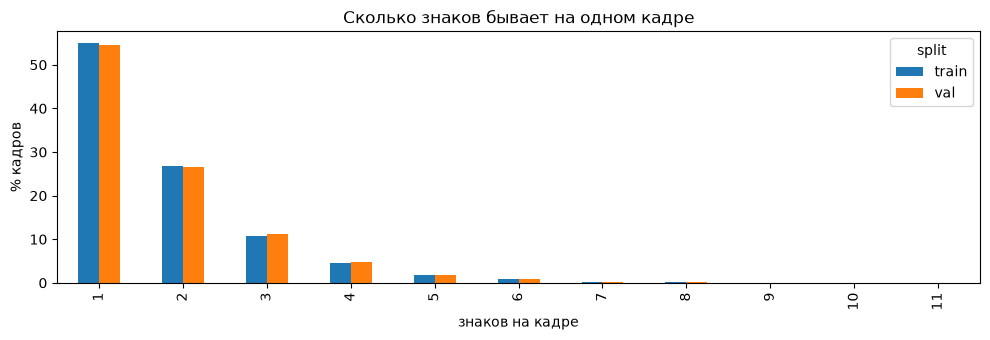

Размер кадра известен у 59188 из 59188 кадров
Доля кадров по разрешению, % внутри части:


split,train,val
разрешение,,
1280x720,80.9,80.6
1920x1080,19.1,19.4


In [16]:
if HAS_BOXES:
    per_frame = ann.groupby(["split", "image_key"]).size().rename("знаков").reset_index()
    display(per_frame.groupby("split")["знаков"].agg(["count", "mean", "median", "max"]).round(2)
            .rename(columns={"count": "кадров с рамками", "mean": "в среднем", "median": "медиана", "max": "максимум"}))

    share_by_count = pd.crosstab(per_frame["знаков"], per_frame.split, normalize="columns").mul(100).round(1)
    fig, ax = plt.subplots(figsize=(10, 3.5))
    share_by_count.plot.bar(ax=ax)
    ax.set_xlabel("знаков на кадре"); ax.set_ylabel("% кадров"); ax.set_title("Сколько знаков бывает на одном кадре")
    plt.tight_layout(); plt.show()

    with_size = active_images.dropna(subset=["img_w", "img_h"]).copy()
    print("Размер кадра известен у", len(with_size), "из", len(active_images), "кадров")
    if len(with_size):
        with_size["разрешение"] = with_size.img_w.astype(int).astype(str) + "x" + with_size.img_h.astype(int).astype(str)
        print("Доля кадров по разрешению, % внутри части:")
        display(pd.crosstab(with_size["разрешение"], with_size.split, normalize="columns").mul(100).round(1))
else:
    print("Исходных кадров нет (готовые вырезки): ячейка пропущена.")


### Вывод по разделам 3-5

> **RTSD: "watchman/rtsd-dataset":**
> 
> В train 54 188 кадров, 95 492 рамки и 155 классов, в val 5 000 кадров, 8 866 рамок и 139 классов. С разметкой всё в порядке: повторов, пустых классов, ссылок на несуществующие объекты и кадров без файла нет, и на каждом кадре есть хотя бы один знак. Размеры кадров известны у всех 59 188 кадров: 81% снят в 1280x720 и 19% в 1920x1080, в обеих частях поровну. На кадре в среднем 1,76 знака (обычно один, но бывает до 11 в train и до 9 в val), значит, детекция должна находить сразу несколько знаков. Мы открыли 600 кадров (по 300 из train и val): все открылись, а размеры в файлах совпали с разметкой. Остальные 58 588 кадров не открывали.
> 
> Есть и неудобные моменты. 16 классов есть в train, но в val их нет, поэтому их качество на val не проверить. Кадров без знаков нет, так что модель не увидит пустой фон и может чаще срабатывать там, где знака нет. Сторона любой рамки не меньше 16 пикселей. Скорее всего, эту границу поставили при создании датасета, а значит, более мелкие знаки могли остаться без разметки (это мы не проверяли).
> 
> Дальше мы оцениваем редкие классы отдельно, на примерах из раздела 9 смотрим, нет ли неразмеченных знаков, а для окончательных чисел при необходимости увеличиваем `CHECK_LIMIT`.

> **RTSD cleaned: "eleldar/rtsd_cleaned":**
> 
> Это 104 358 готовых вырезок знаков и 198 классов, всё в одной части `train`. Кадров, рамок, `val` и `test` здесь нет. Повторов, пустых классов и неизвестных ссылок нет, а из 300 проверенных вырезок открылись все. Размеры вырезок в разметке не записаны, поэтому мы прочитали их у 5 000 случайных вырезок (4,8% датасета): стороны от 16 до 222 пикселей.
> 
> Главная находка: `cleaned` состоит из тех же объектов, что `RTSD` `train` и `val` вместе. Мы сверили все классы (после объединения вариантов вроде `3_24_n40` в `3_24`), таблица различий получилась пустой, и общее число совпало: 104 358 = 95 492 + 8 866. Значит, нового здесь нет, это тот же `RTSD`, только в виде вырезок, и результаты на `cleaned` и на `RTSD` нельзя считать двумя независимыми подтверждениями. Готового деления на обучение и проверку нет, и порядок строк его не повторяет: в первых 95 492 строках класс `5_19_1` встречается 22 796 раз, а в `RTSD` `train` - 22 147.
> 
> Дальше мы используем `cleaned` только для классификации вырезок, делим данные сами (раздел 11) и все числа про размер пишем с оговоркой "по выборке 5 000 вырезок".

> **StarLine: "StarLineResearch/Russian_Road_Signs_Dataset":**
> 
> Всего 6 440 кадров (train 5 031, test 1 409) и 54 281 рамка (39 717 и 14 564). Классов 57 в train и 34 в test. В карточке датасета заявлено 61, но объединение train и test мы не считали, поэтому число 61 пока не подтверждено. Повторов ключей, пустых классов, неизвестных ссылок и кадров без файла нет, а из 300 проверенных кадров train открылись все. Размер кадра известен у 5 000 из 5 031 кадров train, и везде он 2880x1860. На кадре в среднем 7,9 рамки (медиана 6, максимум 42), но это с учётом лишних копий (раздел 8), без них получается около 5,5. Часть test по настройкам закрыта, мы её подробно не изучали, и кадры без знаков в таблице разметки не видны.
> 
> Кадр здесь больше кадров `RTSD` по числу пикселей в 2,6-5,8 раза, а знаков на нём в несколько раз больше. Моделям нужно больше памяти и времени, а при сильном уменьшении мелкие знаки пропадают (раздел 7). О 34 классах test и о качестве его разметки сказать нечего, пока он закрыт.
> 
> Дальше мы считаем объединение классов train и test (не открывая картинки test), при обучении на CPU берём выборку кадров или нарезаем кадры на фрагменты, а когда открывать test, решаем вместе с командой.



## 6. Классы и баланс

**Баланс классов** - сколько примеров у каждого типа знака. Если одни классы встречаются тысячи раз, а другие единицы, модель может отдавать предпочтение частым классам, а оценки редких классов будут менее надёжными.

Важно не смешивать: **объект** (запись разметки) и **физический знак** (один знак на десяти кадрах подряд даёт десять объектов). "Много примеров" и "легко распознаётся" (частота не гарантирует качество). Поэтому смотрятся все классы, а не только "топ20", проблемы обычно находятся в хвосте.

Опорная часть: train | всего классов в таблице: 155


split,train,val
class_name,,
5_19_1,22147,2117
2_1,10027,934
5_16,4727,445
5_15_2,4504,440
3_24,3761,343
2_4,3755,340
3_27,3268,290
1_23,2558,229
4_1_1,2137,196


split,train,val
class_name,,
8_4_3,5,3
6_15_3,4,0
8_14,4,0
6_8_1,4,1
8_23,3,0
8_16,3,0
4_5,2,0
8_3_3,2,0
3_33,1,0


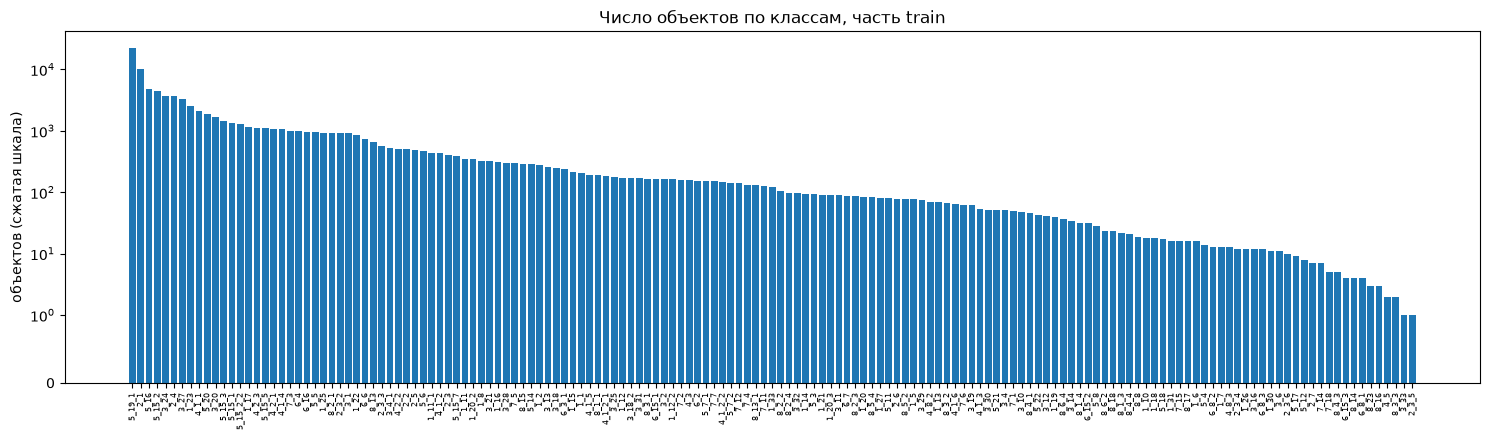

Топ- 1 классов дают 23.2% объектов части train
Топ- 5 классов дают 47.3% объектов части train
Топ-10 классов дают 61.5% объектов части train
Топ-20 классов дают 74.3% объектов части train
Топ-50 классов дают 91.8% объектов части train
Самый частый класс: 5_19_1 (22147); самый редкий с примерами: 2_3_5 (1); отношение примерно 22147 к 1

Сколько классов попадает в каждую группу по числу примеров:


,классов
train,
0,0
1-9,15
10-49,33
50-99,28
100-999,59
1000+,20


Часть train: классов без примеров = 0, классов с 1-5 примерами = 11
Часть val: классов без примеров = 16, классов с 1-5 примерами = 44
Есть в train, но нет в val: 16 классов ['5_22', '1_6', '5_4', '6_8_2', '4_8_3', '3_16', '6_8_3', '1_30', '6_15_3', '8_14', '8_23', '8_16', '4_5', '8_3_3', '3_33'] ...
  Ранговая корреляция числа примеров train и val: 0.96
Доли классов внутри каждой части, по всем её аннотациям:


split,train,val
class_name,,
5_19_1,0.2319,0.2388
2_1,0.1050,0.1053
5_16,0.0495,0.0502
5_15_2,0.0472,0.0496
3_24,0.0394,0.0387
2_4,0.0393,0.0383
3_27,0.0342,0.0327
1_23,0.0268,0.0258
4_1_1,0.0224,0.0221


In [17]:
counts = pd.crosstab(ann.class_name, ann.split)
if category_maps:                           # RTSD: добавляются классы из словаря, у которых нет ни одного примера
    declared = sorted({label for split, mapping in category_maps.items() if split in active_splits for label in mapping.values() if label is not None})
    counts = counts.reindex(counts.index.union(declared), fill_value=0)
counts = counts.reindex(columns=active_splits, fill_value=0)
if counts[reference].sum() == 0:
    raise ValueError("В опорной части нет размеченных классов. Сначала стоит выбрать подходящую часть.")
counts = counts.sort_values(reference, ascending=False)

print("Опорная часть:", reference, "| всего классов в таблице:", len(counts))
display(counts.head(10))
display(counts.tail(10))

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.bar(np.arange(len(counts)), counts[reference])
ax.set_yscale("symlog", linthresh=1)                  # шкала сжимает большие числа, но сохраняет ноль
ax.set_xticks(np.arange(len(counts)))
ax.set_xticklabels(counts.index, rotation=90, fontsize=6)
ax.set_ylabel("объектов (сжатая шкала)")
ax.set_title(f"Число объектов по классам, часть {reference}")
plt.tight_layout(); plt.show()

share = counts[reference] / counts[reference].sum()
cumulative = share.cumsum()
for k in (1, 5, 10, 20, 50):
    if k <= len(cumulative):
        print(f"Топ-{k:>2} классов дают {cumulative.iloc[k - 1]:.1%} объектов части {reference}")
nonzero = counts[reference][counts[reference] > 0]
print(f"Самый частый класс: {nonzero.index[0]} ({nonzero.iloc[0]}); самый редкий с примерами: "
      f"{nonzero.index[-1]} ({nonzero.iloc[-1]}); отношение примерно {nonzero.iloc[0] / nonzero.iloc[-1]:.0f} к 1")

bins = [0, 1, 10, 50, 100, 1000, np.inf]
labels = ["0", "1-9", "10-49", "50-99", "100-999", "1000+"]
rarity = pd.cut(counts[reference], bins, right=False, labels=labels).value_counts().reindex(labels)
print("\nСколько классов попадает в каждую группу по числу примеров:")
display(rarity.to_frame("классов"))

for split in counts.columns:
    print(f"Часть {split}: классов без примеров = {int((counts[split] == 0).sum())}, "
          f"классов с 1-5 примерами = {int(counts[split].between(1, 5).sum())}")
for s in [c for c in counts.columns if c not in (reference, "reduced")]:
    absent = list(counts.index[(counts[reference] > 0) & (counts[s] == 0)])
    print(f"Есть в {reference}, но нет в {s}: {len(absent)} классов", absent[:15], "..." if len(absent) > 15 else "")
    both = counts[(counts[reference] > 0) & (counts[s] > 0)]
    if len(both) > 2 and both[reference].nunique() > 1 and both[s].nunique() > 1:
        print(f"  Ранговая корреляция числа примеров {reference} и {s}: {both[reference].corr(both[s], method='spearman'):.2f}")
class_shares = counts.div(counts.sum(axis=0).replace(0, np.nan), axis=1)
print("Доли классов внутри каждой части, по всем её аннотациям:")
display(class_shares.head(15).round(4))


### Расшифровка самых частых знаков

Таблица ниже показывает самые частые классы опорной части (`train`) с названиями знаков, числом объектов, долей от всех объектов и накопленной долей. Коды классов (например, `5_19_1`) соответствуют номерам знаков в ПДД РФ (знак 5.19.1).

Как читать названия:
- Названия внесены вручную в словарь `SIGN_NAMES`.
- Вариант вида `5_15_2_2` или `3_4_1` - класс разметки RTSD, у которого нет собственного номера в ПДД. Название взято у родительского знака (`5_15_2`, `3_4`) с пометкой "вариант".
- Для `cleaned` и `StarLine` к названию добавляется число из кода (например, `3_24_n40` - "Ограничение максимальной скорости: 40").
- Метки `unknown_sign`, `table`, `scoreboard`, `scoreboard_sign` относятся только к `StarLine` и не являются знаками ПДД.

Таблица нужна для ознакомления с просмотренными дорожными знаками и для чтения остальных разделов, на выводы по классам она не влияет.

In [18]:
SIGN_NAMES = {
 "1_1": "Железнодорожный переезд со шлагбаумом", "1_2": "Железнодорожный переезд без шлагбаума",
 "1_5": "Пересечение с трамвайной линией", "1_6": "Пересечение равнозначных дорог",
 "1_7": "Пересечение с круговым движением", "1_8": "Светофорное регулирование",
 "1_10": "Выезд на набережную", "1_11": "Опасный поворот", "1_11_1": "Опасный поворот (1.11.1)",
 "1_12": "Опасные повороты", "1_12_2": "Опасные повороты (1.12.2)", "1_13": "Крутой спуск",
 "1_14": "Крутой подъём", "1_15": "Скользкая дорога", "1_16": "Неровная дорога",
 "1_17": "Искусственная неровность", "1_18": "Выброс гравия", "1_19": "Опасная обочина",
 "1_20": "Сужение дороги", "1_20_1": "Сужение дороги с обеих сторон", "1_20_2": "Сужение дороги справа",
 "1_20_3": "Сужение дороги слева", "1_21": "Двустороннее движение", "1_22": "Пешеходный переход (предупреждающий)",
 "1_23": "Дети", "1_25": "Дорожные работы", "1_26": "Перегон скота", "1_27": "Дикие животные",
 "1_30": "Низколетящие самолёты", "1_31": "Тоннель", "1_33": "Прочие опасности",
 "2_1": "Главная дорога", "2_2": "Конец главной дороги", "2_3": "Пересечение со второстепенной дорогой (общий класс)",
 "2_3_2": "Примыкание второстепенной дороги (2.3.2)", "2_3_3": "Примыкание второстепенной дороги (2.3.3)",
 "2_3_4": "Примыкание второстепенной дороги (2.3.4)", "2_3_5": "Примыкание второстепенной дороги (2.3.5)",
 "2_3_6": "Примыкание второстепенной дороги (2.3.6)", "2_4": "Уступите дорогу",
 "2_5": "Движение без остановки запрещено", "2_6": "Преимущество встречного движения",
 "2_7": "Преимущество перед встречным движением",
 "3_1": "Въезд запрещён", "3_2": "Движение запрещено", "3_4": "Движение грузовых автомобилей запрещено",
 "3_10": "Движение пешеходов запрещено", "3_11": "Ограничение массы", "3_12": "Ограничение массы на ось",
 "3_13": "Ограничение высоты", "3_14": "Ограничение ширины", "3_18": "Поворот направо запрещён (3.18.1)",
 "3_18_2": "Поворот налево запрещён", "3_19": "Разворот запрещён", "3_20": "Обгон запрещён",
 "3_21": "Конец зоны запрещения обгона", "3_24": "Ограничение максимальной скорости",
 "3_25": "Конец зоны ограничения максимальной скорости", "3_27": "Остановка запрещена",
 "3_28": "Стоянка запрещена", "3_29": "Стоянка запрещена по нечётным числам",
 "3_30": "Стоянка запрещена по чётным числам", "3_31": "Конец зоны всех ограничений",
 "4_1_1": "Движение прямо", "4_1_2": "Движение направо", "4_1_3": "Движение налево",
 "4_1_4": "Движение прямо или направо", "4_1_5": "Движение прямо или налево",
 "4_1_6": "Движение направо или налево", "4_2_1": "Объезд препятствия справа",
 "4_2_2": "Объезд препятствия слева", "4_2_3": "Объезд препятствия справа или слева",
 "4_3": "Круговое движение", "4_5": "Пешеходная дорожка",
 "5_3": "Дорога для автомобилей", "5_5": "Дорога с односторонним движением",
 "5_6": "Конец дороги с односторонним движением",
 "5_7_1": "Выезд на дорогу с односторонним движением (5.7.1)", "5_7_2": "Выезд на дорогу с односторонним движением (5.7.2)",
 "5_14": "Полоса для маршрутных транспортных средств", "5_15_1": "Направления движения по полосам (5.15.1)",
 "5_15_2": "Направления движения по полосе (5.15.2)", "5_15_3": "Начало полосы (5.15.3)",
 "5_15_5": "Конец полосы (5.15.5)", "5_15_7": "Направления движения по полосам (5.15.7)",
 "5_16": "Место остановки автобуса и (или) троллейбуса", "5_19_1": "Пешеходный переход (информационный)",
 "5_20": "Искусственная неровность (информационный)",
 "6_2": "Рекомендуемая скорость", "6_3_1": "Место для разворота", "6_4": "Парковка (парковочное место)",
 "6_6": "Подземный пешеходный переход", "6_15_1": "Направление движения грузовых автомобилей (6.15.1)",
 "6_15_2": "Направление движения грузовых автомобилей (6.15.2)", "6_15_3": "Направление движения грузовых автомобилей (6.15.3)",
 "6_16": "Стоп-линия",
 "7_1": "Пункт первой медицинской помощи", "7_2": "Больница", "7_3": "Автозаправочная станция",
 "7_4": "Техническое обслуживание автомобилей", "7_5": "Мойка автомобилей", "7_6": "Телефон",
 "7_7": "Пункт питания", "7_11": "Гостиница или мотель", "7_12": "Кемпинг",
 "8_1_1": "Расстояние до объекта", "8_1_3": "Расстояние до объекта", "8_1_4": "Расстояние до объекта",
 "8_2_1": "Зона действия", "8_2_2": "Зона действия", "8_2_3": "Зона действия", "8_2_4": "Зона действия",
 "8_3_1": "Направление действия", "8_3_2": "Направление действия", "8_3_3": "Направление действия",
 "8_4_1": "Вид транспортного средства (8.4.1)", "8_4_3": "Вид транспортного средства (8.4.3)",
 "8_4_4": "Вид транспортного средства (8.4.4)", "8_5_2": "Рабочие дни", "8_5_4": "Время действия",
 "8_8": "Платные услуги", "8_13": "Направление главной дороги", "8_13_1": "Направление главной дороги (8.13.1)",
 "8_14": "Полоса движения", "8_15": "Слепые пешеходы", "8_17": "Инвалиды", "8_18": "Кроме инвалидов",
 "8_23": "Фотовидеофиксация",
 "unknown_sign": "Неопознанный знак (метка StarLine)", "table": "Табличка (метка StarLine)",
 "scoreboard": "Табло (метка StarLine)", "scoreboard_sign": "Знак на табло (метка StarLine)",
}

def sign_title(code):
    if code in SIGN_NAMES:
        return SIGN_NAMES[code]
    m = re.match(r"^(.*?)_([nrs])([0-9.]+)(_white)?$", code)     # 3_24_n40, 3_24_s70, 3_13_r2.5
    if m and m.group(1) in SIGN_NAMES:
        return f"{SIGN_NAMES[m.group(1)]}: {m.group(3)}" + (" (белый фон)" if m.group(4) else "")
    if code.endswith("_white") and code[:-6] in SIGN_NAMES:
        return f"{SIGN_NAMES[code[:-6]]} (белый фон)"
    parent = code.rsplit("_", 1)[0]                              # 5_15_2_2 -> 5_15_2, 3_4_1 -> 3_4
    if "_" in code and parent in SIGN_NAMES:
        return f"{SIGN_NAMES[parent]} (вариант {code[len(parent) + 1:]}; родитель {parent})"
    return "(название не внесено)"

TOP_N = 30
ref_counts = counts[reference].sort_values(ascending=False)
total = ref_counts.sum()
top_view = pd.DataFrame({
    "название": [sign_title(c) for c in ref_counts.index],
    "объектов": ref_counts.values,
    "доля, %": (ref_counts / total * 100).round(1).values,
    "накопленная доля, %": (ref_counts.cumsum() / total * 100).round(1).values,
}, index=ref_counts.index).head(TOP_N)
display(top_view)
unnamed = [c for c in ref_counts.index[:50] if sign_title(c) == "(название не внесено)"]
print("Среди 50 самых частых классов без названия:", unnamed)

,название,объектов,"доля, %","накопленная доля, %"
class_name,,,,
5_19_1,Пешеходный переход (информационный),22147,23.2,23.2
2_1,Главная дорога,10027,10.5,33.7
5_16,Место остановки автобуса и (или) троллейбуса,4727,5.0,38.6
5_15_2,Направления движения по полосе (5.15.2),4504,4.7,43.4
3_24,Ограничение максимальной скорости,3761,3.9,47.3
2_4,Уступите дорогу,3755,3.9,51.2
3_27,Остановка запрещена,3268,3.4,54.7
1_23,Дети,2558,2.7,57.3
4_1_1,Движение прямо,2137,2.2,59.6


Среди 50 самых частых классов без названия: []


### 6.1. Объекты и независимые группы

Если в источнике есть идентификатор объекта (`object_id` у `StarLine`, `sign_id` у `cleaned`), число объектов можно сравнить с числом различных идентификаторов. Если у класса 500 объектов, но всего 8 различных идентификаторов, независимых знаков может быть гораздо меньше. Смысл и область уникальности идентификаторов не подтверждены, поэтому таблица служит ориентиром. У `RTSD` такого поля нет.

In [19]:
group_table = None
if active_objects.group_id.notna().any():
    group_table = (active_objects[active_objects.split == reference].groupby("class_name")
                   .agg(объектов=("annotation_id", "size"), различных_group_id=("group_id", "nunique")))
    group_table["объектов на один group_id"] = (group_table["объектов"] / group_table["различных_group_id"]).round(1)
    display(group_table.sort_values("объектов", ascending=False).head(15))
    display(group_table.sort_values("различных_group_id").head(10))
else:
    print("Идентификаторов объектов в этом датасете нет: число независимых знаков по ним оценить нельзя.")

Идентификаторов объектов в этом датасете нет: число независимых знаков по ним оценить нельзя.


In [20]:
# Только для cleaned: сколько различных знаков в каждом классе
if KIND == "cleaned":
    signs_per_class = objects.groupby("class_name").group_id.nunique().rename("знаков")
    by_signs = pd.concat([counts[reference].rename("вырезок"), signs_per_class], axis=1)
    by_signs["вырезок на знак"] = (by_signs["вырезок"] / by_signs["знаков"]).round(1)
    display(by_signs.sort_values("знаков").head(15))
    print("Классов с не менее 30 различных знаков:", int((by_signs["знаков"] >= 30).sum()), "из", len(by_signs))
    print("Классов с не менее 100 различных знаков:", int((by_signs["знаков"] >= 100).sum()))
else:
    print("Проверка относится только к cleaned.")

Проверка относится только к cleaned.


### 6.2. Группы знаков ПДД и "семейства" похожих классов

Первое число в коде класса - группа знаков ПДД: 1 предупреждающие, 2 приоритета, 3 запрещающие, 4 предписывающие, 5 особых предписаний, 6 информационные, 7 сервиса, 8 таблички.

Семейство - классы с общим началом (`2_3`, `2_3_1`, `2_3_2`): такие знаки могут быть похожи - это проверяется просмотром (раздел 9).

Системы классов у датасетов различаются: в `cleaned` встречаются: например, `3_24_n40` и `3_24_n20`, в `StarLine` - `3_24_s40_white`, в `RTSD` - общий `3_24`. Классы разных датасетов стоит сопоставить перед объединением. "Семейство" выделено по коду, а его реальную визуальную похожесть проверяют по картинкам.

In [21]:
GROUP_NAMES = {1: "1 Предупреждающие", 2: "2 Приоритета", 3: "3 Запрещающие", 4: "4 Предписывающие",
               5: "5 Особых предписаний", 6: "6 Информационные", 7: "7 Сервиса", 8: "8 Таблички"}
first_number = counts.index.to_series().str.extract(r"^(\d+)")[0].astype(float)
group_label = first_number.map(GROUP_NAMES).fillna("не по шаблону ПДД")
by_group = counts.groupby(group_label).sum()
by_group.insert(0, "классов", group_label.value_counts().reindex(by_group.index))
display(by_group)

families = {}                                    # семейство -> список классов
for class_name in counts.index:
    match = re.match(r"^(\d+_\d+)", str(class_name))
    if match:
        families.setdefault(match.group(1), []).append(class_name)
families = {key: members for key, members in families.items() if len(members) > 1}
print("Семейств с двумя и более классами:", len(families))
display(pd.Series(families, dtype=object).head(15).to_frame("классы в семействе"))

split,классов,train,val
0,,,
1 Предупреждающие,30,9166,832
2 Приоритета,12,16786,1542
3 Запрещающие,25,12506,1136
4 Предписывающие,15,7198,660
5 Особых предписаний,23,41148,3913
6 Информационные,12,3393,320
7 Сервиса,12,2165,198
8 Таблички,26,3130,265


Семейств с двумя и более классами: 20


,классы в семействе
5_15,"[5_15_2, 5_15_3, 5_15_1, 5_15_2_2, 5_15_5, 5_15_7]"
4_1,"[4_1_1, 4_1_4, 4_1_2, 4_1_5, 4_1_2_1, 4_1_2_2, 4_1_6, 4_1_3]"
4_2,"[4_2_3, 4_2_1, 4_2_2]"
8_2,"[8_2_1, 8_2_2, 8_2_4, 8_2_3]"
2_3,"[2_3_2, 2_3_3, 2_3, 2_3_4, 2_3_6, 2_3_5]"
8_13,"[8_13, 8_13_1]"
3_4,"[3_4_1, 3_4]"
1_11,"[1_11_1, 1_11]"
1_20,"[1_20_2, 1_20_3, 1_20]"
3_18,"[3_18, 3_18_2]"


### 6.3. Как записаны ограничения скорости

Нужно решить, различаются ли знаки ограничения скорости как общий тип (`3_24`) или как конкретное число. Таблица показывает классы, начинающиеся с `3_24` (максимальная скорость) и `3_25` (конец ограничения), и число примеров. Если скорость в классе не записана, для её распознавания потребуется дополнительная проверенная разметка.

In [22]:
speed_classes = [c for c in counts.index if re.match(r"^3_2[45](_|$)", str(c))]
if speed_classes:
    display(counts.loc[speed_classes])
else:
    print("Классов, начинающихся с 3_24 или 3_25, в таблице нет.")

split,train,val
class_name,,
3_24,3761,343
3_25,178,10


### 6.4. Названия классов и список кандидатов

"Выброс" для изображений - не только необычное число, но и класс, которого не должно быть, опечатка или служебная метка. Названия проверяются по шаблону "число_число_..." с возможным буквенным суффиксом. Те, которые не подошли под шаблон - нужно проверять вручную.

Список строится по двум условиям: достаточно примеров в опорной и в проверочной частях.

In [23]:
pattern = re.compile(r"^\d+(_\d+)*(_[A-Za-z][\w.]*)?$")
odd = [c for c in counts.index if not pattern.match(str(c))]
print("Классов с нестандартным названием:", len(odd))
display(counts.loc[odd] if odd else pd.DataFrame({"результат": ["все названия подходят под шаблон"]}))

eval_split = next((s for s in counts.columns if s not in (reference, "reduced")), None)
mask = counts[reference] >= MIN_TRAIN_FOR_CANDIDATES
if eval_split:
    mask &= counts[eval_split] >= MIN_EVAL_FOR_CANDIDATES
candidates = counts[mask].copy()
candidates["медиана стороны, px"] = ann[ann.split == reference].groupby("class_name").side.median().reindex(candidates.index).round(1)
print(f"Классов с числом примеров не меньше {MIN_TRAIN_FOR_CANDIDATES} в {reference}"
      + (f" и не меньше {MIN_EVAL_FOR_CANDIDATES} в {eval_split}" if eval_split else "") + f": {len(candidates)}")
print("Это список для обсуждения, а не окончательный выбор.")
display(candidates.head(30))

Классов с нестандартным названием: 0


,результат
0,все названия подходят под шаблон


Классов с числом примеров не меньше 200 в train и не меньше 20 в val: 53
Это список для обсуждения, а не окончательный выбор.


split,train,val,"медиана стороны, px"
class_name,,,
5_19_1,22147,2117,31.0
2_1,10027,934,35.8
5_16,4727,445,29.8
5_15_2,4504,440,24.5
3_24,3761,343,32.4
2_4,3755,340,35.0
3_27,3268,290,30.0
1_23,2558,229,39.0
4_1_1,2137,196,28.0


In [24]:
# Только для cleaned: классы, у которых достаточно различных знаков
if KIND == "cleaned":
    enough = by_signs[by_signs["знаков"] >= 100].sort_values("знаков", ascending=False)
    print("Классов с не менее 100 различных знаков:", len(enough))
    display(enough)
    in_both = [c for c in enough.index if c in candidates.index]
    print("Из них входят в прежний список кандидатов по вырезкам:", len(in_both), "из", len(enough))
else:
    print("Проверка относится только к cleaned.")

Проверка относится только к cleaned.


### 6.5. Доли классов в train и val и редкие классы

Три простые проверки, которые отвечают на вопрос "похожи ли train и val по составу классов и где данных не хватает":
- точечный график долей классов в train и val (точки около диагонали - доли похожи);
- список классов, доля которых в val отличается от доли в train больше чем в `SHARE_RATIO_LIMIT` раз (если в val у них не меньше 5 объектов);
- таблица редких классов по числу примеров в train: сколько классов вообще нет в val и сколько имеют там от 1 до 5 примеров (для них метрика на val ненадёжна).

Ячейка работает, если есть части `train` и `val`.


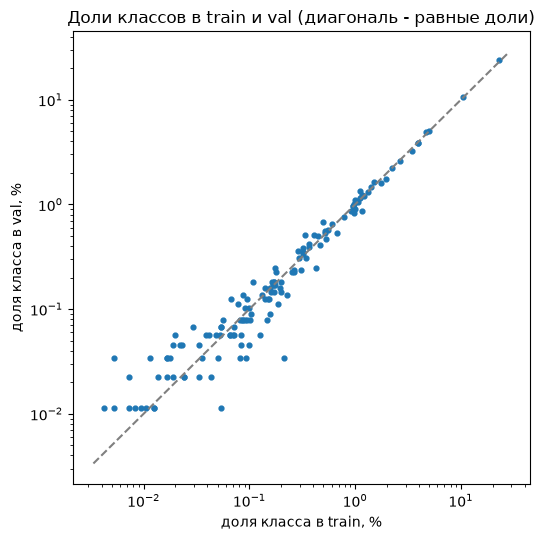

Классов, доля которых в val отличается от train больше чем в 3 раза (и в val не меньше 5 объектов): 0
Классы по числу примеров в train:


,классов,нет_в_val,в_val_от_1_до_5
группа,,,
1-9,15,8,7
10-49,33,8,24
50-99,28,0,11
100-999,59,0,2
1000+,20,0,0


In [25]:
SHARE_RATIO_LIMIT = 3   # во сколько раз доля класса в val может отличаться от доли в train
if {"train", "val"}.issubset(counts.columns):
    both = counts[["train", "val"]].copy()
    shares = both.div(both.sum()) * 100
    present = shares[(both.train > 0) & (both.val > 0)]

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.scatter(present.train, present.val, s=12)
    limits = [present.min().min() * 0.8, present.max().max() * 1.2]
    ax.plot(limits, limits, color="grey", ls="--")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("доля класса в train, %"); ax.set_ylabel("доля класса в val, %")
    ax.set_title("Доли классов в train и val (диагональ - равные доли)")
    plt.tight_layout(); plt.show()

    ratio = present.val / present.train
    far = present[(ratio > SHARE_RATIO_LIMIT) | (ratio < 1 / SHARE_RATIO_LIMIT)]
    far = far[both.loc[far.index, "val"] >= 5]
    print(f"Классов, доля которых в val отличается от train больше чем в {SHARE_RATIO_LIMIT} раза (и в val не меньше 5 объектов): {len(far)}")
    if len(far):
        display(far.round(3))

    train_classes = both[both.train > 0]
    size_bin = pd.cut(train_classes.train, [0, 9, 49, 99, 999, np.inf], labels=["1-9", "10-49", "50-99", "100-999", "1000+"])
    rare = pd.DataFrame({"группа": size_bin, "нет в val": train_classes.val.eq(0), "в val от 1 до 5": train_classes.val.between(1, 5)})
    print("Классы по числу примеров в train:")
    display(rare.groupby("группа", observed=False).agg(классов=("нет в val", "size"), нет_в_val=("нет в val", "sum"), в_val_от_1_до_5=("в val от 1 до 5", "sum")))
else:
    print("Нужны части train и val: ячейка пропущена.")


### Вывод по разделу 6

> **RTSD: "watchman/rtsd-dataset":**
> 
> Классов 155 в train и 139 в val. Распределение очень неравномерное. Самый частый класс `5_19_1` даёт 22 147 знаков в train, это 23,2%. Топ-10 классов дают 61,5% объектов, топ-50 дают 91,8%. Самый редкий класс встречается один раз, то есть самый частый знак попадается в 22 147 раз чаще. У 15 классов в train меньше 10 примеров. Почти половина объектов (около 43%) приходится на группу 5, особые предписания.
> 
> Train и val похожи: доли классов почти совпадают (корреляция рангов 0,96). Ни у одного класса, у которого в val не меньше 5 объектов, доля в val не отличается от доли в train больше чем в 3 раза. Заметный разброс есть только у редких классов, и объясняется он малыми числами. Но именно для редких классов val помогает слабо: 16 классов в нём нет совсем, ещё у 44 всего от 1 до 5 примеров. Из 15 классов с 1-9 примерами в train 8 нет в val, а у 7 в val от 1 до 5 примеров.
> 
> Ограничения скорости записаны одним классом `3_24` (3 761 в train и 343 в val), так что значение скорости по меткам различить нельзя. Класс `3_25` редкий (178 и 10). Нестандартных названий классов и идентификаторов объектов нет. Пороги 200 примеров в train и 20 в val проходят 53 класса.
> 
> Дальше мы выбираем из этих 53 кандидатов 10-20 классов для первого эксперимента, решаем, хватит ли общего класса `3_24`, и проверяем по картинкам пары похожих знаков. Семейства стрелок `5_15_x` и `4_1_x` разберём отдельно при анализе ошибок.

> **RTSD cleaned: "eleldar/rtsd_cleaned":**
> 
> Классов 198, и у всех есть примеры. Объекты те же, что в `RTSD`, но ограничения скорости здесь разбиты по числу: `3_24` на 9 классов (от `3_24_n5` до `3_24_n80`, самый частый `3_24_n40` - 2 197 вырезок, 53,5% от всех `3_24`) и `3_25` на 5 классов. Поэтому запрещающих классов стало 64 вместо 25, а информационных 16 вместо 12.
> 
> Дисбаланс такой же, как в `RTSD`. Самый частый класс `5_19_1` - 24 264 вырезки (23,3%), топ-10 дают 59,7%, топ-50 дают 90,5%, а самый частый класс встречается в 24 264 раза чаще самого редкого. У 36 классов меньше 10 вырезок, а порог 200 вырезок проходят 59 классов.
> 
> Важная деталь: вырезки повторяют друг друга. Всего в датасете 15 628 различных знаков (`sign_id`), то есть на один знак приходится в среднем 6,7 вырезки (медиана 6, максимум 63). Поэтому порог "200 вырезок" завышает реальный объём: независимых знаков в 6,7 раза меньше. Классов, у которых не меньше 30 различных знаков, 69, а не меньше 100 знаков - 31 (все они входят в те 59). Самый большой класс `5_19_1` - 3 244 знака. В показанных 15 самых бедных классах по одному знаку, а на таких классах нельзя ни обучиться, ни честно проверить качество на других знаках. Значения скорости по числу различить можно, но для этого нужно читать цифры на очень мелкой картинке.
> 
> Дальше мы составляем список классов по числу различных знаков. Для первого эксперимента берём 31 класс (не меньше 100 знаков), а расширенный вариант - 69 классов. Отдельно решаем, нужны ли значения скорости или хватит общего класса `3_24`.

> **StarLine: "StarLineResearch/Russian_Road_Signs_Dataset":**
> 
> Классов 57 в train, и четыре из них не похожи на обычные знаки ПДД: `unknown_sign` (12 672), `table` (1 679), `scoreboard_sign` (398) и `scoreboard` (50). Вместе это 14 799 объектов, то есть 37,3%. Самый частый класс как раз `unknown_sign` (31,9%), дальше идёт `1_25`, дорожные работы (15,1%). Топ-5 дают 61,6%, топ-10 дают 77,8%, топ-50 дают 99,7%. Самый редкий класс `8_2_3` встречается 6 раз, то есть самый частый больше его примерно в 2 112 раз. У 3 классов меньше 10 примеров, у 10 классов от 10 до 49, а порог 200 проходят 26 классов. Из группы "Приоритета" есть один класс (59 объектов), группы "Сервиса" нет.
> 
> Скорость размечена хаотично. Есть 21 класс с числом (`3_24` и `3_25`, в том числе с пометкой `white`), вместе 10 595 рамок (26,7%), и при этом есть общий `3_24` (2 329). По просмотренным вырезкам общий `3_24` содержит знаки с числами 90, 70, 60 и 50, то есть перекрывается с `3_24_s90`, `3_24_s70` и другими. Из-за этого качество на скоростях будет занижено. В `unknown_sign` попадают обычные знаки известных классов, поэтому как обычный класс его использовать нельзя. Что значит метка `table`, мы не подтвердили. Значения `group_id` (34 в train, у частых классов 7-26) на идентификатор знака не похожи. Ещё датасет смещён в сторону дорожных работ и ограничений скорости.
> 
> Дальше, если StarLine пойдёт в обучение, мы исключаем `unknown_sign` и `table` из классов (или называем их "класс не определён"). Нужно выяснить, что означают `3_24` без числа и `group_id`. Для проверки на другом домене берём только классы, общие с `RTSD`.




## 7. Размеры знаков

Для классификации важен размер самой вырезки, для детекции - размер знака относительно кадра и после уменьшения кадра. Знак в 12 пикселей после уменьшения может потерять цифры и символы. Размеры ниже считаются в пикселях исходного изображения.

- `obj_w`, `obj_h` - ширина и высота знака по отдельности;
- `side` - условная сторона: корень из площади рамки, то есть сторона квадрата той же площади (не ширина знака, а одна удобная цифра для сравнения);
- пороги 16 и 32 пикселя - ориентиры, а не универсальные границы распознавания;
- увеличение маленькой вырезки не возвращает потерянные детали.

Для `cleaned` размер готовой картинки не обязательно равен точному размеру знака: рамка исходного объекта неизвестна. Поэтому проценты мелких объектов между кропами и кадрами напрямую не сопоставляются. При неизвестных размерах проценты считаются только среди измеренных примеров, с указанием охвата.

Размер известен у 104358 из 104358 объектов


split          train     val
obj_w count  95492.0  8866.0
      mean      39.6    39.7
      std       24.7    25.2
      min       16.0    16.0
      5%        18.0    18.0
      50%       32.0    31.0
      95%       88.0    90.0
      max      307.0   263.0
obj_h count  95492.0  8866.0
      mean      38.5    38.6
      std       22.8    22.9
      min       16.0    16.0
      5%        18.0    18.0
      50%       31.0    31.0
      95%       84.0    85.0
      max      288.0   228.0
side  count  95492.0  8866.0
      mean      38.7    38.9
      std       22.8    23.2
      min       16.0    16.0
      5%        18.3    18.5
      50%       31.5    31.5
      95%       84.4    85.4
      max      290.8   244.9

Доля объектов по размеру (px, % внутри части):


split,train,val
side,,
16-32,51.4,51.8
32-64,37.5,36.6
64+,11.1,11.7


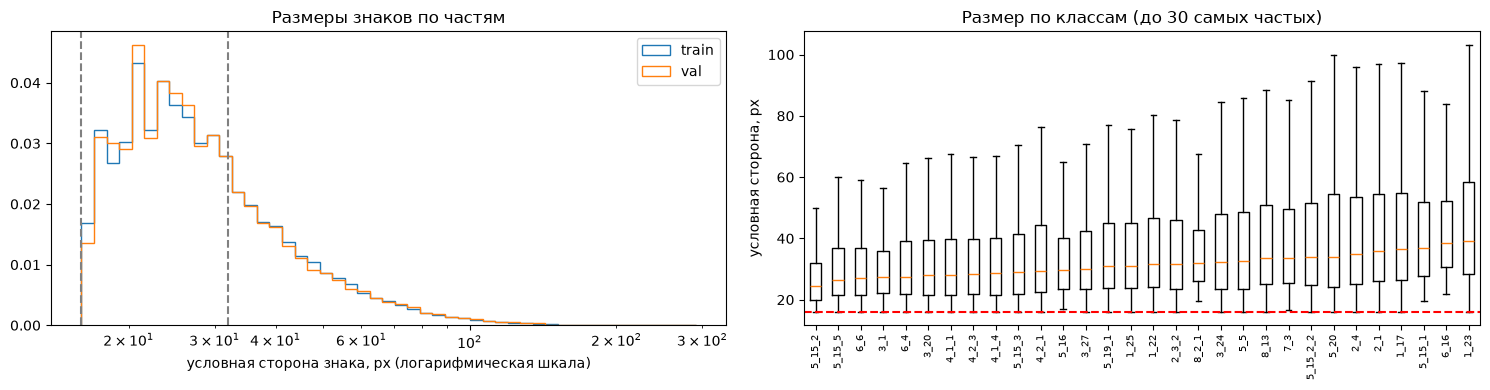

Самые мелкие классы по медиане:


,объектов,медиана_px,доля_меньше_16
class_name,,,
3_29,75,23.49,0.0
5_14,283,24.49,0.0
5_15_2,4504,24.49,0.0
8_1_4,32,25.44,0.0
5_15_5,1100,26.50,0.0
1_13,69,26.50,0.0
3_21,321,26.98,0.0
6_6,747,26.98,0.0
3_30,52,27.50,0.0


Показаны классы, у которых измерено не меньше 30 объектов; всего измерено объектов опорной части: 95492
Нормировка доступна для 104358 из 104358 объектов с корректными размерами.

Оценка: если длинную сторону кадра уменьшить до 640 px, доля знаков с шириной или высотой меньше 16 px:


,объектов,ширина_меньше_16,высота_меньше_16
split,,,
train,95492,0.564,0.574
val,8866,0.567,0.574


In [26]:
known = ann.dropna(subset=["side"])
known = known[np.isfinite(known.side) & (known.obj_w > 0) & (known.obj_h > 0)]
HAVE_SIZES = len(known) > 0
print(f"Размер известен у {len(known)} из {len(ann)} объектов")

if HAVE_SIZES:
    display(known.groupby("split")[["obj_w", "obj_h", "side"]].describe(percentiles=[0.05, 0.5, 0.95]).round(1).T)

    size_bin = pd.cut(known.side, [0, 8, 16, 32, 64, np.inf], labels=["<8", "8-16", "16-32", "32-64", "64+"], right=False)
    print("Доля объектов по размеру (px, % внутри части):")
    display(pd.crosstab(size_bin, known.split, normalize="columns").mul(100).round(1))

    fig, axes = plt.subplots(1, 2, figsize=(15, 4))
    edges = np.logspace(np.log10(max(known.side.min(), 1)), np.log10(max(known.side.max(), 2)), 50)
    for split, part in known.groupby("split"):
        axes[0].hist(part.side, bins=edges, histtype="step", density=True, label=split)
    axes[0].set_xscale("log"); axes[0].legend()
    for v in (16, 32):
        axes[0].axvline(v, color="grey", ls="--")
    axes[0].set_xlabel("условная сторона знака, px (логарифмическая шкала)")
    axes[0].set_title("Размеры знаков по частям")

    data = known[(known.split == reference) & known.class_name.isin(counts.index[:30])]
    order = data.groupby("class_name").side.median().sort_values().index
    if len(order):
        axes[1].boxplot([data.loc[data.class_name == c, "side"] for c in order], showfliers=False)
    axes[1].set_xticks(range(1, len(order) + 1)); axes[1].set_xticklabels(order, rotation=90, fontsize=7)
    axes[1].axhline(16, color="red", ls="--"); axes[1].set_ylabel("условная сторона, px")
    axes[1].set_title("Размер по классам (до 30 самых частых)")
    plt.tight_layout(); plt.show()

    small = (known[known.split == reference].groupby("class_name")
             .agg(объектов=("side", "size"), медиана_px=("side", "median"), доля_меньше_16=("side", lambda s: (s < 16).mean())))
    print("Самые мелкие классы по медиане:")
    MIN_N_SMALL = 30   # классы с меньшим числом измеренных объектов дают случайные медианы
    display(small[small.объектов >= MIN_N_SMALL].sort_values("медиана_px").head(10).round(2))
    print(f"Показаны классы, у которых измерено не меньше {MIN_N_SMALL} объектов; всего измерено объектов опорной части: {int((known.split == reference).sum())}")

    if HAS_BOXES and known.img_w.notna().any():
        sized = known.dropna(subset=["img_w", "img_h"])
        sized = sized[np.isfinite(sized.img_w) & np.isfinite(sized.img_h) & (sized.img_w > 0) & (sized.img_h > 0)]
        scale = TARGET_SIZE / sized[["img_w", "img_h"]].max(axis=1)
        resized = sized.assign(w_resized=sized.obj_w * scale, h_resized=sized.obj_h * scale)
        print("Нормировка доступна для", len(resized), "из", len(known), "объектов с корректными размерами.")
        print(f"\nОценка: если длинную сторону кадра уменьшить до {TARGET_SIZE} px, доля знаков с шириной или высотой меньше 16 px:")
        display(resized.groupby("split").agg(объектов=("side", "size"),
                                             ширина_меньше_16=("w_resized", lambda s: (s < 16).mean()),
                                             высота_меньше_16=("h_resized", lambda s: (s < 16).mean())).round(3))
else:
    print("Размеров нет: их нужно считать из изображений (раздел 5) или скачать кадры.")

### 7.1. Какую долю знаков модель увидит мелкими при разных размерах входа

При детекции берется кадр, уменьшенный до фиксированного размера (`INPUT_SIZES`). Чем больше вход, тем крупнее знаки, но тем медленнее и тяжелее обучение. Здесь для каждого размера входа считается, какая доля знаков по условной стороне (`side`, раздел 7) окажется меньше 8, 16 и 32 пикселей. Это дополняет оценку по ширине и высоте выше: меры разные, поэтому проценты могут немного отличаться, а вывод остаётся тем же.

Для `cleaned` ячейка пропускается: там нет кадров.

Доля знаков по условной стороне после уменьшения длинной стороны кадра (измерено у 104358 из 104358 объектов):


знаков  меньше 8 px, %  меньше 16 px, %  меньше 32 px, %
вход, px часть                                                          
640      train   95492             3.8             58.5             92.0
         val      8866             3.8             58.7             91.4
960      train   95492             0.0             22.3             76.8
         val      8866             0.0             22.4             76.9
1280     train   95492             0.0              3.8             58.5
         val      8866             0.0              3.8             58.7

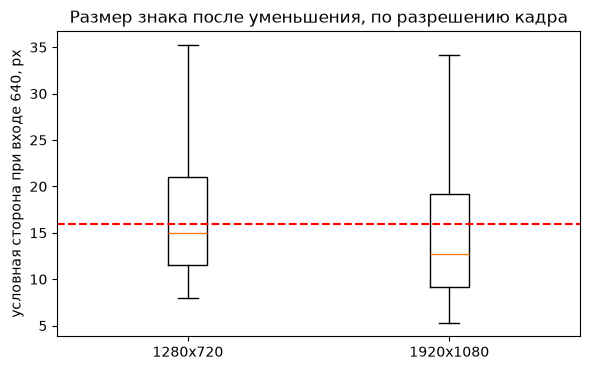

,знаков,"медиана при входе 640, px"
разрешение,,
1280x720,78310,14.9
1920x1080,26048,12.7


In [27]:
if HAS_BOXES and HAVE_SIZES and known.img_w.notna().any():
    framed = known.dropna(subset=["img_w", "img_h"])
    framed = framed[(framed.img_w > 0) & (framed.img_h > 0)]
    longest = framed[["img_w", "img_h"]].max(axis=1)
    rows = []
    for input_size in INPUT_SIZES:
        scaled = framed.side * input_size / longest
        for split_name, values in scaled.groupby(framed.split):
            rows.append({"вход, px": input_size, "часть": split_name, "знаков": len(values),
                         "меньше 8 px, %": (values < 8).mean() * 100, "меньше 16 px, %": (values < 16).mean() * 100,
                         "меньше 32 px, %": (values < 32).mean() * 100})
    print(f"Доля знаков по условной стороне после уменьшения длинной стороны кадра (измерено у {len(framed)} из {len(known)} объектов):")
    display(pd.DataFrame(rows).set_index(["вход, px", "часть"]).round(1))

    framed = framed.assign(разрешение=framed.img_w.astype(int).astype(str) + "x" + framed.img_h.astype(int).astype(str),
                           side_target=framed.side * TARGET_SIZE / longest)
    if framed.разрешение.nunique() > 1:
        resolutions = sorted(framed.разрешение.unique())
        fig, ax = plt.subplots(figsize=(6, 3.8))
        ax.boxplot([framed.loc[framed.разрешение == r, "side_target"] for r in resolutions], showfliers=False)
        ax.set_xticks(range(1, len(resolutions) + 1)); ax.set_xticklabels(resolutions)
        ax.axhline(16, color="red", ls="--"); ax.set_ylabel(f"условная сторона при входе {TARGET_SIZE}, px")
        ax.set_title("Размер знака после уменьшения, по разрешению кадра")
        plt.tight_layout(); plt.show()
    display(framed.groupby("разрешение").side_target.agg(["count", "median"]).round(1)
            .rename(columns={"count": "знаков", "median": f"медиана при входе {TARGET_SIZE}, px"}))
else:
    print("Нужны рамки и размеры кадров: ячейка пропущена.")


### Вывод по разделу 7

> **RTSD: "watchman/rtsd-dataset":**
> 
> Размер известен у всех 104 358 объектов. Самая маленькая сторона рамки - 16 пикселей, медиана условной стороны около 31,5 пикселя (это сторона квадрата той же площади, что и рамка). 51% знаков имеют сторону 16-32 пикселя, 38% - 32-64, 11% - от 64.
> 
> Проблема начинается, когда кадр уменьшают до размера входа модели. Если сжать длинную сторону кадра до 640 пикселей, мельче 16 пикселей становятся 58,5% знаков (мельче 8 - 3,8%). При входе 960 таких знаков 22,3%, при входе 1280 - 3,8%, в val почти так же. По ширине при входе 640 доля мелких знаков 56%. Кадры FullHD сжимаются сильнее: медиана условной стороны при входе 640 равна 12,7 пикселя против 14,9 на кадрах 1280x720. Самые мелкие классы по медиане (не меньше 30 объектов): `3_29`, `5_14`, `5_15_2` (около 24-25 пикселей), а частые `5_15_2` и `5_15_5` одновременно мелкие.
> 
> Ноль мелких знаков в исходном размере не значит, что их нет: это следствие границы разметки в 16 пикселей. Большой вход (1280 пикселей) резко сокращает долю мелких знаков, но замедляет работу и требует больше памяти.
> 
> Дальше мы сравниваем для детектции входы 640, 960 и 1280, для классификации берём вырезки в исходном разрешении и проверяем по кадрам, есть ли неразмеченные знаки меньше 16 пикселей.

> **RTSD cleaned: "eleldar/rtsd_cleaned":**
> 
> Размеры мы измерили только у 5 000 случайных вырезок из 104 358 (4,8%). Ширина и высота начинаются с 16 пикселей, наибольшая ширина 222, наибольшая высота 195, медиана условной стороны 31,9. Сторону 16-32 пикселя имеют 50,7% вырезок, 32-64 - 38,1%, от 64 - 11,2%. Это почти то же, что в `RTSD` (50,7% против 51,4% в диапазоне 16-32) и так и должно быть, ведь объекты те же. Самые мелкие классы по медиане (не меньше 30 измерений): `6_6`, `3_20`, `5_15_2` (26-26,5 пикселя).
> 
> Вырезки небольшие, и модель будет работать с картинками 16-40 пикселей. Нижняя граница 16 пикселей та же, что в `RTSD`, значит, более мелких вырезок в выборке нет. Посчитать, какими знаки становятся после уменьшения кадра, нельзя, так как кадров нет.
> 
> Дальше мы пишем размеры с оговоркой "по выборке", при необходимости увеличиваем `SIZE_SCAN_LIMIT`, чтобы прочитать все вырезки (долго), а для модели выбираем размер входа не меньше 32x32.

> **StarLine: "StarLineResearch/Russian_Road_Signs_Dataset":**
> 
> Размер есть у всех 39 717 рамок, координаты даны в пикселях кадра 2880x1860. Самая маленькая сторона 11 пикселей, медиана 45,4 (ширина 42,6, высота 47,4), самые крупные рамки 817x1296 пикселей. Меньше 16 пикселей только 2,2% знаков, 16-32 - 31,1%, 32-64 - 33,2%, от 64 - 33,6%. То есть в исходном кадре знаки заметно крупнее, чем в `RTSD`.
> 
> Но сам кадр очень большой, и после уменьшения знаки получаются мельче, чем в `RTSD` при том же входе. Мельче 16 пикселей становятся 71,8% знаков при входе 640 (мельче 8 - 39,7%), 52,5% при входе 960 (мельче 8 - 19,2%) и 39,7% при входе 1280 (мельче 8 - 5,4%). Для сравнения, у `RTSD` при входе 1280 таких знаков 3,8%. Медиана при входе 640 равна 10,1 пикселя (посчитано для 39 512 рамок, у 205 рамок нет границ кадра). Самые мелкие классы по медиане (не меньше 30 объектов): `scoreboard_sign` (24,4), `5_15_5` (25,4), `3_24_s60` (28,6). Значит, обычный вход детектора здесь не подходит: нужна нарезка кадра на фрагменты или очень большой вход.
> 
> Дальше мы пробуем для детекции нарезку кадра или вход не меньше 1280, для классификации берём вырезки из исходного кадра, а про 205 рамок без границ кадра выясняем причину (кадры не прочитаны из-за `SIZE_SCAN_LIMIT`).


## 8. Ошибки разметки и необычные объекты

Проверяются рамки (если они есть): нечисловые координаты, нулевые размеры, очень малые рамки, выход за границы кадра, точные повторы, странные пропорции. Ничего не удаляется автоматически: у находки может быть объяснение (знак у края кадра, вытянутая табличка). Отсутствие ошибок не доказывает правильность класса и полноту разметки. Ниже определяются функции для показа картинок.

In [28]:
def get_crop(obj, pad=0.15):
    """Вырезает знак из кадра с запасом pad (доля размера рамки). Для cleaned возвращает всю картинку.
    Исходные координаты в таблице при этом не меняются."""
    image = open_image(image_by_key.loc[obj["image_key"]]).convert("RGB")
    if not HAS_BOXES:
        return image
    coords = np.asarray([obj["x"], obj["y"], obj["w"], obj["h"]], dtype=float)
    if not np.isfinite(coords).all() or obj["w"] <= 0 or obj["h"] <= 0:
        raise ValueError("Некорректные координаты: исходная рамка не используется для вырезки.")
    p = max(obj["w"], obj["h"]) * pad
    box = (max(obj["x"] - p, 0), max(obj["y"] - p, 0),
           min(obj["x"] + obj["w"] + p, image.width), min(obj["y"] + obj["h"] + p, image.height))
    if not all(np.isfinite(box)) or box[2] - box[0] < 1 or box[3] - box[1] < 1:
        raise ValueError("пустая рамка")
    return image.crop(tuple(int(round(v)) for v in box))


def fmt(v):
    return f"{v:.2f}" if isinstance(v, (float, np.floating)) else str(v)[:14]


def gallery(rows, title, n=8, pad=0.3, caption_cols=("class_name",)):
    """Галерея вырезок: одна строка таблицы rows - один показанный объект."""
    rows = rows.head(n)
    if rows.empty or not HAVE_IMAGES:
        print("Нечего показывать:", title)
        return
    fig, axes = plt.subplots(1, len(rows), figsize=(1.9 * len(rows), 2.7), squeeze=False)
    for ax, (_, r) in zip(axes[0], rows.iterrows()):
        ax.axis("off")
        try:
            ax.imshow(get_crop(r, pad=pad))
            ax.set_title("\n".join(fmt(r[c]) for c in caption_cols), fontsize=8)
        except Exception as e:
            ax.set_title(type(e).__name__, fontsize=8)
    fig.suptitle(title, fontsize=10)
    plt.tight_layout(); plt.show()


def sample_per_group(df, cols, n):
    """Не более n случайных строк из каждой группы (по столбцам cols)."""
    parts = [g.sample(min(len(g), n), random_state=SEED) for _, g in df.groupby(cols) if len(g) > 0]
    return pd.concat(parts) if parts else df.head(0)

In [29]:
issues = pd.DataFrame(index=ann.index)
if HAS_BOXES:
    coords = ann[["x", "y", "w", "h"]].to_numpy(dtype=float)
    finite = np.isfinite(coords).all(axis=1)
    sized = ann.img_w.notna() & ann.img_h.notna()
    group_num = ann.class_name.str.extract(r"^(\d+)")[0].astype(float)
    aspect = ann.w / ann.h
    issues = pd.DataFrame({
        "нечисловые координаты": ~finite,
        "ширина или высота <= 0": (ann.w <= 0) | (ann.h <= 0),
        "рамка очень мала (<= 3 px)": (ann.w <= 3) | (ann.h <= 3),
        "рамка выходит за кадр": sized & ((ann.x < 0) | (ann.y < 0) | (ann.x + ann.w > ann.img_w) | (ann.y + ann.h > ann.img_h)),
        "точный повтор рамки": ann.duplicated(["image_key", "class_name", "x", "y", "w", "h"]),
        "странная пропорция (вне 0.5-2, не таблички)": group_num.ne(8) & ((aspect < 0.5) | (aspect > 2)),
    }, index=ann.index)
    if "annotation_area" in ann.columns:
        issues["area не равна w*h"] = ann.annotation_area.notna() & ((ann.annotation_area - ann.w * ann.h).abs() > 1)
    if "iscrowd" in ann.columns:
        issues["iscrowd = 1"] = ann["iscrowd"] == 1
    display(issues.groupby(ann.split).sum().T)
    print("Рамок с известными границами кадра:", int(sized.sum()), "из", len(ann))
else:
    print("Исходных рамок нет (это готовые вырезки): проверки рамок пропущены.")

split,train,val
нечисловые координаты,0,0
ширина или высота <= 0,0,0
рамка очень мала (<= 3 px),0,0
рамка выходит за кадр,0,0
точный повтор рамки,0,0
"странная пропорция (вне 0.5-2, не таблички)",2151,202
area не равна w*h,0,0
iscrowd = 1,0,0


Рамок с известными границами кадра: 104358 из 104358


**Зачем эта ячейка.** На `StarLine` эта ячейка находит 11 870 лишних копий рамок, около 30% строк. Ячейка показывает, в каких кадрах и классах они есть и чем копии различаются. Пока причина неизвестна, повторы не удаляются.

In [30]:
# Диагностика точных повторов рамок (рамка, кадр и класс совпадают полностью). Ничего не удаляется.
if HAS_BOXES:
    key = ["image_key", "class_name", "x", "y", "w", "h"]
    dup_all = ann.duplicated(key, keep=False)
    extra = ann.duplicated(key)   # лишние копии: первая запись из группы не считается
    print("строк в группах повторов:", int(dup_all.sum()), "; лишних копий:", int(extra.sum()),
          "; кадров с повторами:", ann[extra].image_key.nunique(), "из", ann.image_key.nunique())
    if dup_all.any():
        grp = ann[dup_all].groupby(key)
        display(grp.size().value_counts().head(10).rename("групп с таким числом копий"))
        for col in ["annotation_id", "group_id", "timestamp_ns", "bbox_msg_id"]:
            if col in ann.columns:
                print(col, ": доля групп повторов с разными значениями:", round(float((grp[col].nunique() > 1).mean()), 3))
        display(ann[extra].class_name.value_counts().head(10).rename("лишних копий"))
        print("Если повторы различаются служебными полями, возможно, это разные записи одного объекта; решение принимает команда.")
else:
    print("Исходных рамок нет: проверка повторов пропущена.")


строк в группах повторов: 0 ; лишних копий: 0 ; кадров с повторами: 0 из 59188


### 8.1. Пары сильно перекрывающихся рамок (IoU)

**IoU (Intersection over Union, «пересечение над объединением»)** - площадь общей части двух рамок, делённая на площадь их объединения: от 0 (рамки не касаются) до 1 (рамки совпадают). Если две рамки на одном кадре имеют IoU больше `IOU_LIMIT`, это либо дубль, либо один знак записан дважды, либо два соседних знака разметили слишком близко. Если классы у пары одинаковые, похоже на дубль, а если разные, на конфликт меток. Точные повторы выше - частный случай (IoU равен 1).


In [31]:
IOU_LIMIT = 0.7   # порог: пары рамок на одном кадре с IoU выше считаются подозрительными
if HAS_BOXES:
    boxes_ok = ann.dropna(subset=["x", "y", "w", "h"])
    boxes_ok = boxes_ok[(boxes_ok.w > 0) & (boxes_ok.h > 0)]
    multi = boxes_ok[boxes_ok.groupby("image_key").image_key.transform("size") > 1]
    pairs = []
    for frame_key, g in multi.groupby("image_key", sort=False):
        b = g[["x", "y", "w", "h"]].to_numpy(float)
        names = g.class_name.to_numpy()
        x2, y2 = b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
        inter_w = np.minimum(x2[:, None], x2[None, :]) - np.maximum(b[:, 0][:, None], b[:, 0][None, :])
        inter_h = np.minimum(y2[:, None], y2[None, :]) - np.maximum(b[:, 1][:, None], b[:, 1][None, :])
        inter = np.clip(inter_w, 0, None) * np.clip(inter_h, 0, None)
        area = b[:, 2] * b[:, 3]
        iou = inter / (area[:, None] + area[None, :] - inter)
        for i, j in zip(*np.where(np.triu(iou > IOU_LIMIT, k=1))):
            pairs.append((g.split.iloc[0], frame_key, names[i], names[j], round(float(iou[i, j]), 2)))
    overlap = pd.DataFrame(pairs, columns=["split", "image_key", "class_1", "class_2", "iou"])
    print(f"Кадров с несколькими рамками: {multi.image_key.nunique()}; пар рамок с IoU > {IOU_LIMIT}: {len(overlap)}")
    print("  из них с одинаковым классом (похоже на дубль):", int((overlap.class_1 == overlap.class_2).sum()))
    print("  из них с разными классами (конфликт меток):", int((overlap.class_1 != overlap.class_2).sum()))
    if len(overlap):
        display(overlap.groupby("split").size().rename("пар").to_frame())
        display(overlap.sort_values("iou", ascending=False).head(10))
else:
    print("Исходных рамок нет (готовые вырезки): ячейка пропущена.")


Кадров с несколькими рамками: 26706; пар рамок с IoU > 0.7: 0
  из них с одинаковым классом (похоже на дубль): 0
  из них с разными классами (конфликт меток): 0


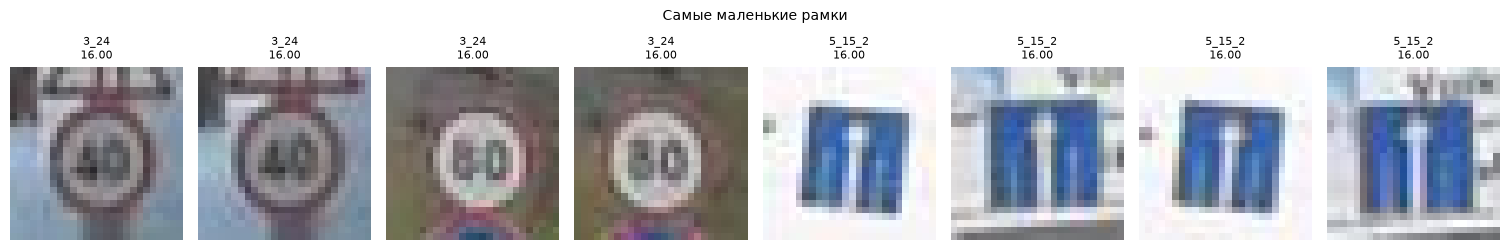

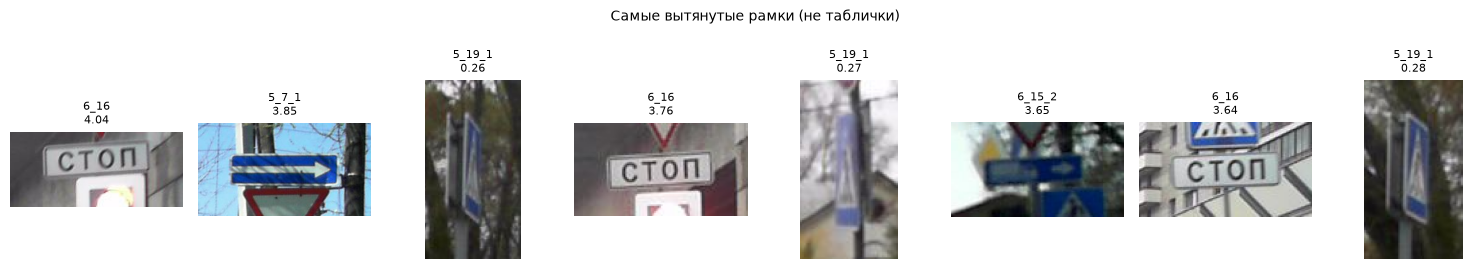

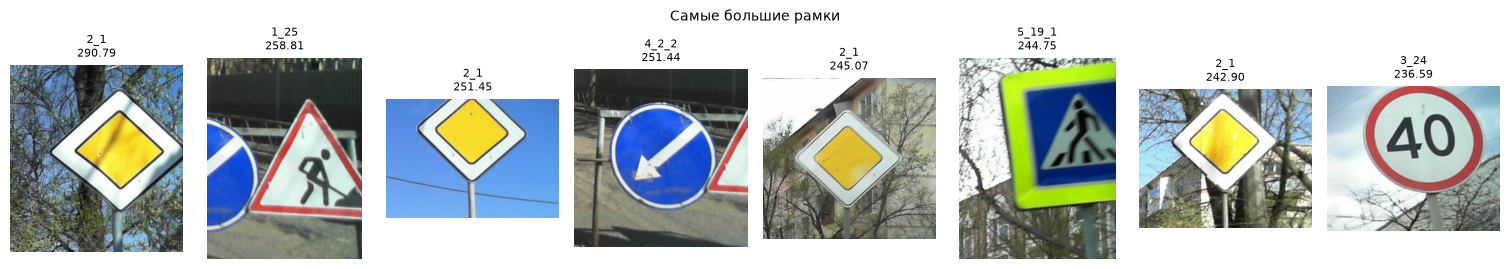

Нечего показывать: Рамки, выходящие за границы кадра


In [32]:
# Подозрительные объекты: смотрим сами, а не просто доверяем только таблице
if HAS_BOXES and HAVE_IMAGES and HAVE_SIZES:
    clean = ann[ann.split == reference].dropna(subset=["x", "y", "w", "h"])
    clean = clean[(clean.w > 0) & (clean.h > 0)]
    gallery(clean.sort_values("side").head(8), "Самые маленькие рамки", caption_cols=("class_name", "side"))
    elongated = clean[clean.class_name.str.extract(r"^(\d+)")[0].astype(float).ne(8)].copy()
    elongated["aspect"] = elongated.w / elongated.h
    elongated["deviation"] = np.log(elongated.aspect).abs()
    gallery(elongated.sort_values("deviation", ascending=False).head(8), "Самые вытянутые рамки (не таблички)", caption_cols=("class_name", "aspect"))
    gallery(clean.sort_values("side", ascending=False).head(8), "Самые большие рамки", caption_cols=("class_name", "side"))
    gallery(ann.loc[issues["рамка выходит за кадр"]], "Рамки, выходящие за границы кадра", caption_cols=("class_name", "x"))
else:
    print("Раздел пропущен: нужны исходные рамки, картинки и известные размеры.")

Какие классы дают вытянутые рамки. Вытянутая рамка - не обязательно ошибка, это может быть форма самого знака.

In [33]:
# Какие классы дают рамки с необычной пропорцией
if HAS_BOXES:
    odd = ann[issues["странная пропорция (вне 0.5-2, не таблички)"]]

    by_class = pd.DataFrame({
        "вытянутых рамок": odd.class_name.value_counts(),
        "всего рамок класса": ann.class_name.value_counts(),
    }).dropna().astype(int)
    by_class["доля вытянутых"] = (by_class["вытянутых рамок"] / by_class["всего рамок класса"]).round(3)

    print("Классы с наибольшим числом вытянутых рамок:")
    display(by_class.sort_values("вытянутых рамок", ascending=False).head(10))

    share_by_split = (odd.groupby("split").size() / ann.groupby("split").size()).round(4)
    print("Доля вытянутых рамок по частям:")
    display(share_by_split.to_frame("доля"))
else:
    print("Для cleaned нет рамок: ячейка пропущена.")

Классы с наибольшим числом вытянутых рамок:


,вытянутых рамок,всего рамок класса,доля вытянутых
class_name,,,
6_16,1006,1054,0.954
5_15_1,274,1493,0.184
5_19_1,255,24264,0.011
6_15_1,174,176,0.989
5_7_2,149,155,0.961
5_7_1,109,158,0.690
5_15_7,72,437,0.165
2_1,39,10961,0.004
2_4,37,4095,0.009


Доля вытянутых рамок по частям:


,доля
split,
train,0.0225
val,0.0228


### 8.2. Пропорция рамок по группам знаков

График ширины к высоте рамки для каждой группы знаков ПДД. Табличные знаки (группа 8) обычно вытянуты, остальные группы должны быть близки к квадрату. Красные линии - границы 0,5 и 2, которые мы считали странной пропорцией выше. Таблица ниже графика показывает, какая доля рамок каждой группы выходит за эти границы.

Для `cleaned` ячейка пропускается: нет рамок.

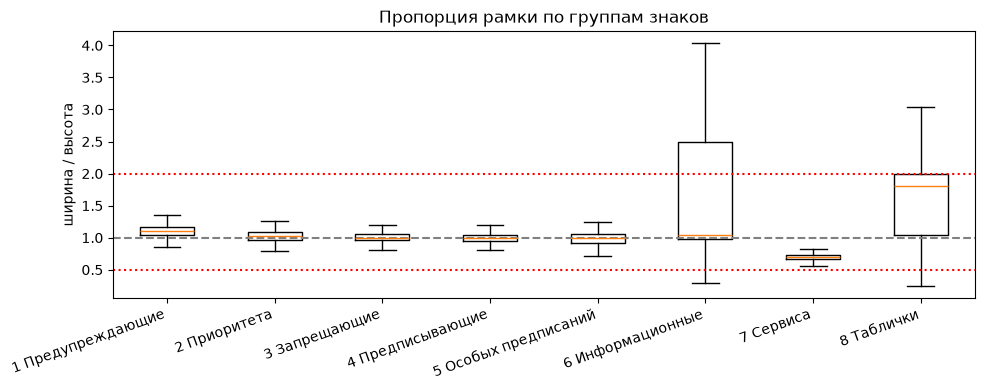

,рамок,медиана,доля_вне_0_5_2
группа,,,
1 Предупреждающие,9998,1.097,0.000
2 Приоритета,18328,1.022,0.004
3 Запрещающие,13642,1.000,0.005
4 Предписывающие,7858,1.000,0.002
5 Особых предписаний,45061,1.000,0.021
6 Информационные,3713,1.047,0.331
7 Сервиса,2363,0.692,0.004
8 Таблички,3395,1.812,0.263


In [34]:
if HAS_BOXES:
    class_group = ann.class_name.str.extract(r"^(\d+)")[0].astype(float).map(GROUP_NAMES).fillna("не по шаблону ПДД")
    aspect_df = pd.DataFrame({"группа": class_group, "пропорция": ann.w / ann.h}).dropna()
    group_order = sorted(aspect_df["группа"].unique())
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.boxplot([aspect_df.loc[aspect_df["группа"] == g, "пропорция"] for g in group_order], showfliers=False)
    ax.set_xticks(range(1, len(group_order) + 1)); ax.set_xticklabels(group_order, rotation=20, ha="right")
    ax.axhline(1, color="grey", ls="--"); ax.axhline(0.5, color="red", ls=":"); ax.axhline(2, color="red", ls=":")
    ax.set_ylabel("ширина / высота"); ax.set_title("Пропорция рамки по группам знаков")
    plt.tight_layout(); plt.show()
    display(aspect_df.groupby("группа")["пропорция"]
            .agg(рамок="size", медиана="median", доля_вне_0_5_2=lambda s: ((s < 0.5) | (s > 2)).mean()).round(3))
else:
    print("Исходных рамок нет (готовые вырезки): ячейка пропущена.")


### Вывод по разделу 8

> **RTSD: "watchman/rtsd-dataset":**
> 
> Технических ошибок в рамках нет: нечисловых координат, нулевых и очень малых рамок, выходов за кадр, несовпадений площади и повторов рамок везде 0. Пар рамок с IoU больше 0,7 тоже нет (проверили 26 706 кадров с несколькими рамками).
> 
> Необычная форма встречается редко. Вытянутых рамок (пропорция вне диапазона 0,5-2) 2,3% в обеих частях, и на десять классов приходится 91% из них. Четыре класса (`6_15_1`, `5_7_2`, `6_16`, `5_7_1`) почти целиком состоят из вытянутых рамок, а у шести других (`5_15_1`, `5_15_7`, `5_15_2_2`, `5_19_1`, `2_4`, `2_1`) это редкое исключение. По группам знаков вытянуты информационные знаки (33% вне диапазона 0,5-2: `6_16`, `6_15_1` и другие) и таблички (26%, медиана ширины к высоте 1,8). У предупреждающих, приоритета, запрещающих и предписывающих знаков рамки почти квадратные (вне диапазона не больше 0,5%), у особых предписаний - 2,1%. Знаки сервиса - вертикальные прямоугольники (медиана 0,69).
> 
> Мы посмотрели крайние случаи и ошибок разметки там не видно. Самые маленькие рамки (16 пикселей, `3_24` и `5_15_2`) читаются с трудом: число 40 и стрелки почти неразличимы. Самые вытянутые рамки - настоящие знаки: широкие (`6_16` "СТОП", `5_7_1`, `6_15_2`) и узкие `5_19_1`, снятые сбоку под углом. Самые большие рамки - близкие знаки (`2_1`, `1_25`, `4_2_2`, `5_19_1`, `3_24`). Для широких знаков вытянутость - это просто форма, поэтому правило про пропорцию нужно задавать для каждого класса отдельно. Узкие `5_19_1` размечены верно, но распознать их трудно.
> 
> Дальше мы не удаляем вытянутые рамки автоматически, а для классификации скорости берём более крупные вырезки.

> **RTSD cleaned: "eleldar/rtsd_cleaned":**
> 
> Проверки рамок мы не делали, так как в `cleaned` нет рамок, есть только готовые вырезки. Проверки целостности из раздела 4 пройдены: повторов ключей и ID нет, пустых классов нет, все проверенные вырезки открылись.
> 
> Это значит, что ошибки в положении рамок и их повторы в этом датасете нельзя ни найти, ни исключить. Мы не знаем, как создавались вырезки и сколько фона вокруг знака в них оставили. Правильность класса у каждой вырезки тоже не проверена.
> 
> Дальше, если в проекте будет детекция, ошибки рамок изучаем на `RTSD` или `StarLine`. Для `cleaned` смотрим по картинкам (раздел 9), нет ли вырезок с неверным или лишним содержимым.

> **StarLine: "StarLineResearch/Russian_Road_Signs_Dataset":**
> 
> Нечисловых, нулевых и очень малых рамок нет. За границы кадра выходят 6 рамок из 39 512 (у остальных 205 нет границ кадра). Вытянутых рамок (пропорция вне 0,5-2, без табличек) 616, это 1,55%. Почти все они у `unknown_sign` (254), `6_9_2` (100 из 100), `5_15_2` (55 из 150) и `scoreboard` (50 из 50).
> 
> Главная находка - лишние копии рамок: их 11 870, это 29,9% всех строк train, и они есть в 1 929 из 5 031 кадров (38%). Копией мы посчитали строку, у которой совпали кадр, класс, `x`, `y`, `w` и `h`. 6 686 групп состоят из двух строк, 2 592 группы - из трёх. У всех копий совпадают `timestamp_ns` и `bbox_msg_id`, в 99,8% групп совпадает `group_id`, а отличается всегда только `annotation_id`. Больше всего лишних копий у `unknown_sign` (4 852), `1_25` (2 570), `table` (807), `1_20_2` (769) и `8_22_2` (677). Похоже, что при выгрузке одни и те же рамки записали несколько раз, хотя мы это не доказали. Из-за копий завышены счётчики классов и число объектов, а при обучении детектора часть знаков получила бы двойной вес. Копии лежат в одном кадре, поэтому при делении по кадрам они не попадут в обучение и проверку одновременно.
> 
> Проверка IoU нашла 18 353 пары рамок с IoU больше 0,7 на 4 754 кадрах: 14 494 пары с одинаковым классом (в основном те же копии) и 3 859 пар с разными классами. В показанных парах с IoU 1,0 один и тот же знак записан двумя классами, общим и с числом (`3_25` и `3_25_s60`). Скорее всего, так и устроены конфликтные пары, но какая доля из 3 859 пар такая, мы не считали.
> 
> Дальше надо будет обсудить удаление копий и записать, сколько рамок удалено. Посчитать, какая доля пар с разными классами приходится на пары "общий класс и класс с числом", а после удаления пересчитать баланс классов (разделы 6 и 14). Вытянутые рамки не удаляем автоматически.

## 9. Реальные примеры: кадры и вырезки

Графики не заменяют просмотр картинок. Ниже - полные кадры с рамками (если есть), вырезки выбранных классов и классы из одного семейства. Классы задаются в `SELECT_CLASSES` и по умолчанию берутся самые частые. Кадры выбираются случайно, а не "лучшие": так будет честно.

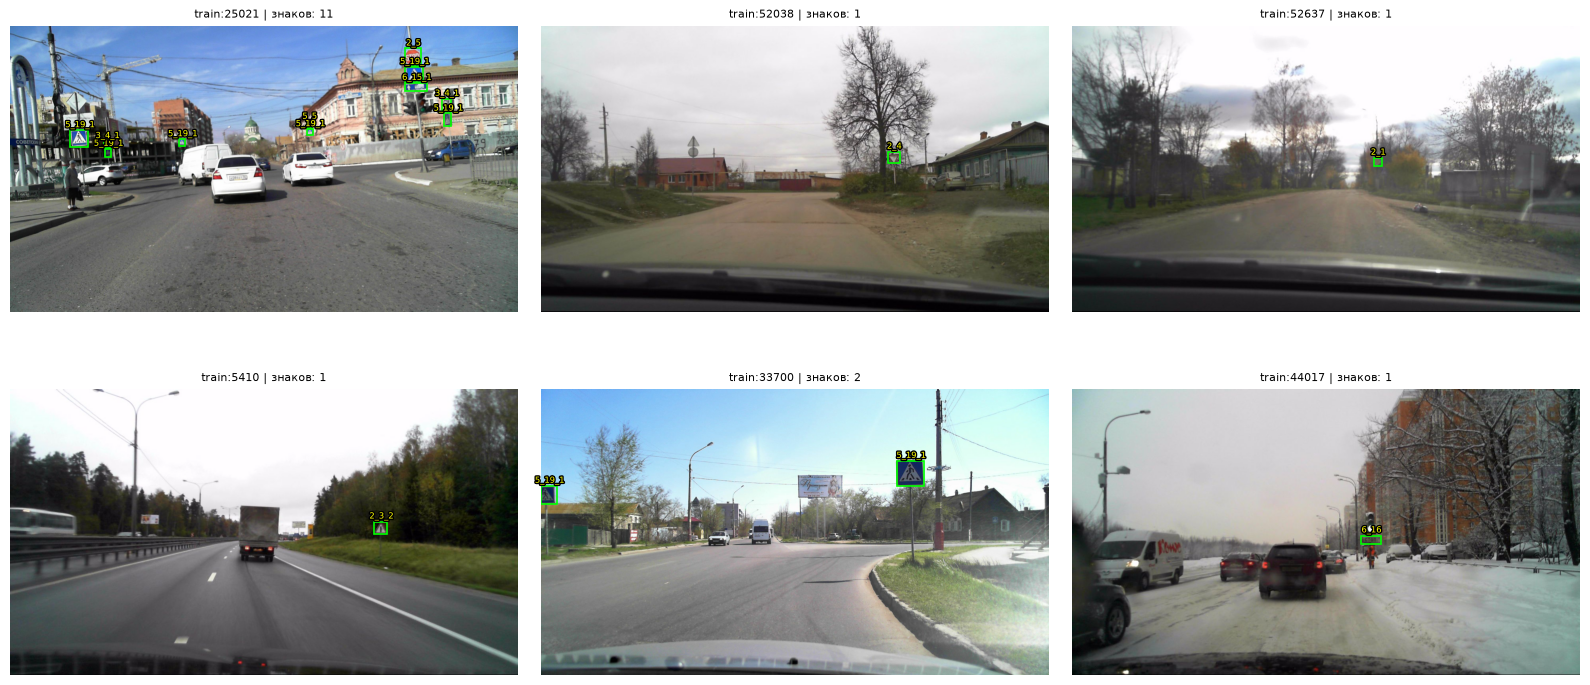

In [35]:
if HAS_BOXES and HAVE_IMAGES:
    per_image = ann.groupby("image_key").size().sort_values(ascending=False)
    available = active_images[(active_images.split == reference) & active_images.path.map(lambda p: Path(p).is_file())]
    chosen_keys = list(per_image.index[:1]) + list(available.sample(min(5, len(available)), random_state=SEED).image_key)
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    for ax in axes.flat:
        ax.axis("off")
    for ax, key in zip(axes.flat, chosen_keys):
        try:
            ax.imshow(open_image(image_by_key.loc[key]).convert("RGB"))
            for _, b in ann[ann.image_key == key].iterrows():
                if np.isfinite([b.x, b.y, b.w, b.h]).all() and b.w > 0 and b.h > 0:
                    ax.add_patch(Rectangle((b.x, b.y), b.w, b.h, fill=False, edgecolor="lime", linewidth=1.2))
                    ax.text(b.x + b.w / 2, b.y - 3, str(b.class_name), color="yellow", fontsize=6, ha="center", va="bottom", path_effects=[pe.withStroke(linewidth=2, foreground="black")])
            ax.set_title(f"{key[:38]} | знаков: {int(per_image.get(key, 0))}", fontsize=8)
        except Exception as e:
            ax.set_title(type(e).__name__)
    plt.tight_layout(); plt.show()
else:
    print("Полные кадры недоступны (нет картинок или это готовые вырезки).")

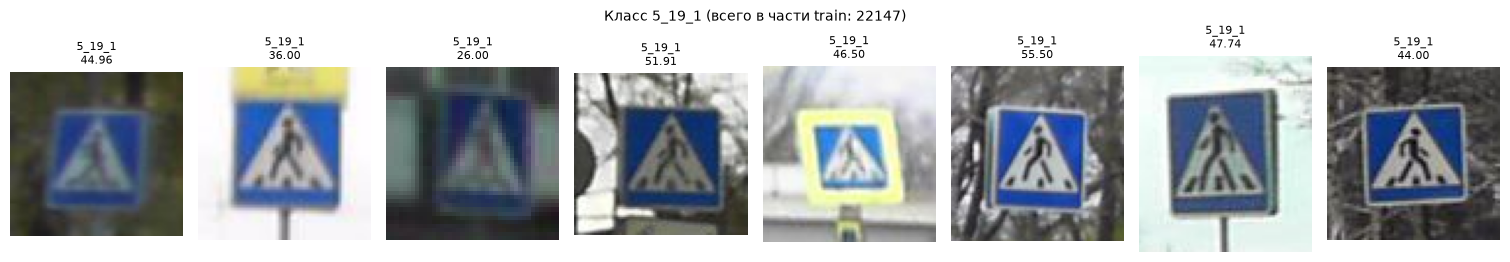

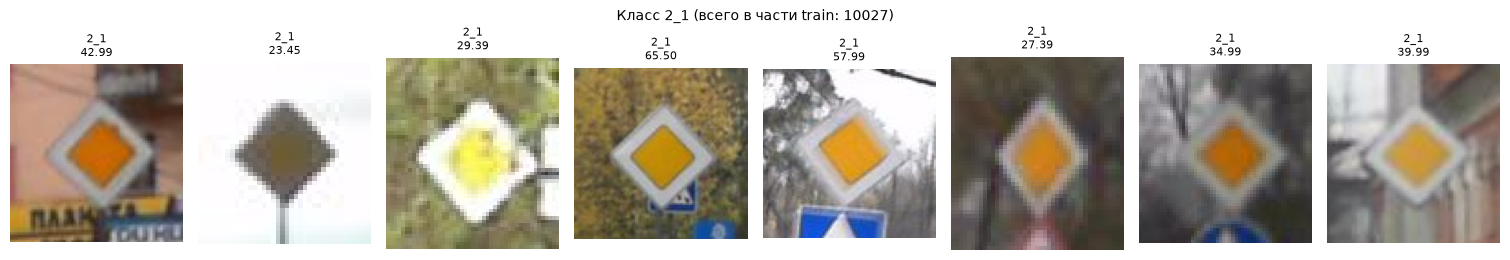

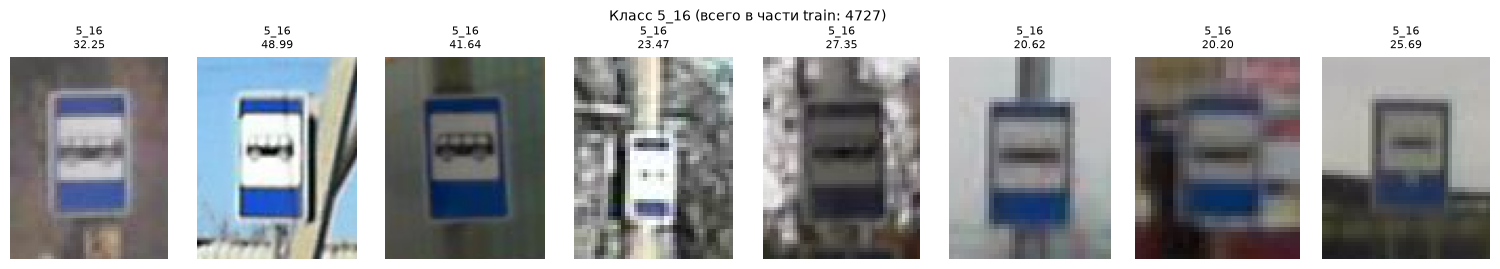

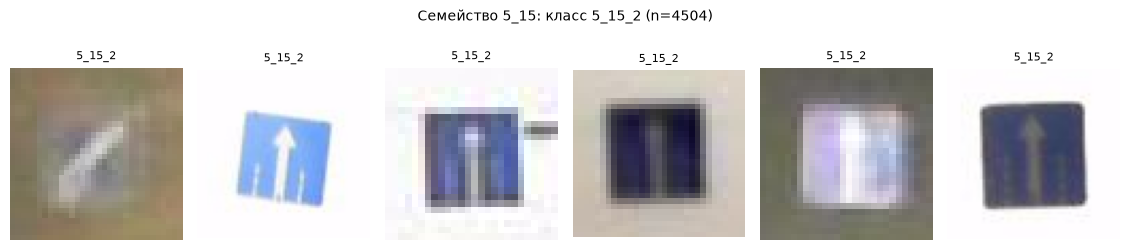

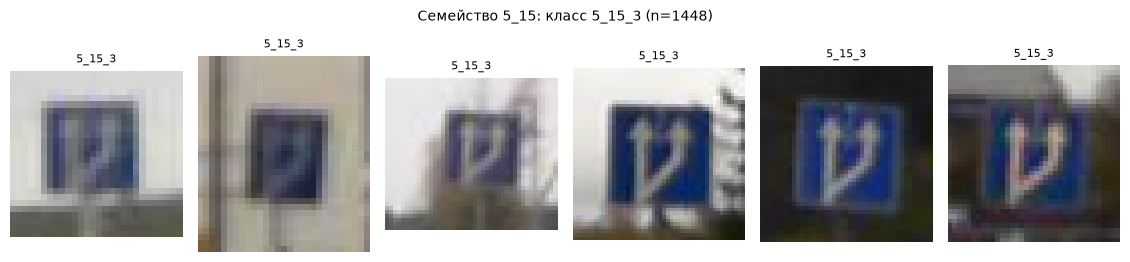

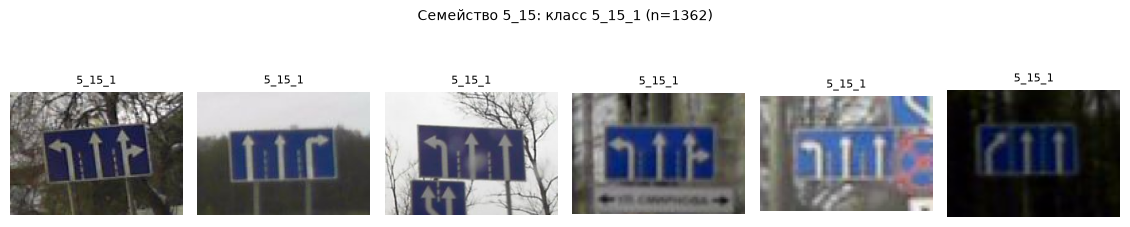

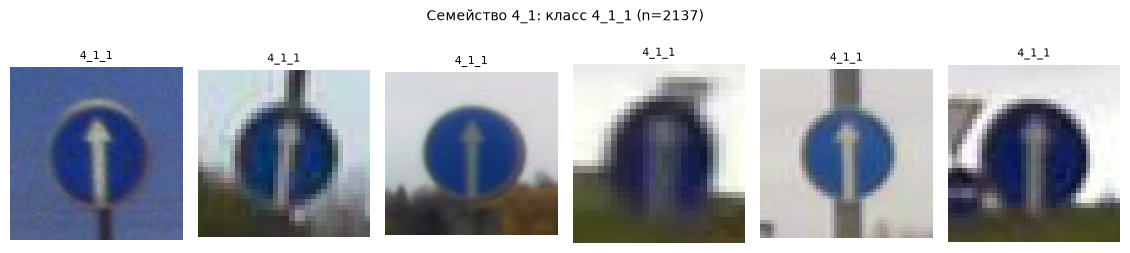

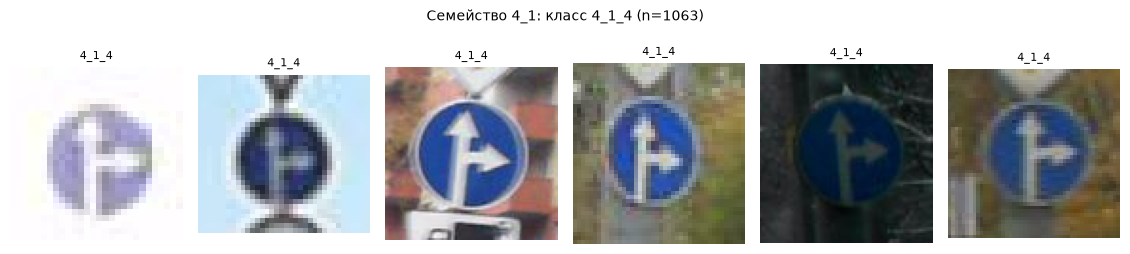

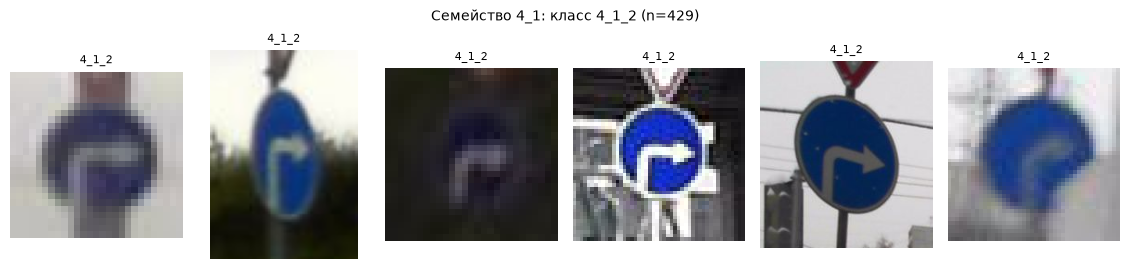

In [36]:
chosen = list(SELECT_CLASSES) or list(counts.index[counts[reference] > 0][:3])
for c in chosen:
    pool = ann[(ann.class_name == c) & (ann.split == reference)]
    gallery(pool.sample(min(8, len(pool)), random_state=SEED) if len(pool) else pool,
            f"Класс {c} (всего в части {reference}: {len(pool)})", caption_cols=("class_name", "side"))

# Классы из одного семейства: визуально похожие знаки, которые модель может путать
for fam, members in list(families.items())[:2]:
    for c in members[:3]:
        pool = ann[(ann.class_name == c) & (ann.split == reference)]
        gallery(pool.sample(min(6, len(pool)), random_state=SEED) if len(pool) else pool, f"Семейство {fam}: класс {c} (n={len(pool)})")

### 9.1. Пары похожих и зеркальных классов

Для нескольких пар классов, которые отличаются в основном направлением (например, объезд препятствия справа и слева, поворот направо и налево запрещён), показаны вырезки обоих классов. Так видно, почему горизонтальное отражение (раздел 13) может превратить один класс в другой, и какие пары модель, скорее всего, будет путать. Пары, которых нет в выбранном датасете, пропускаются.


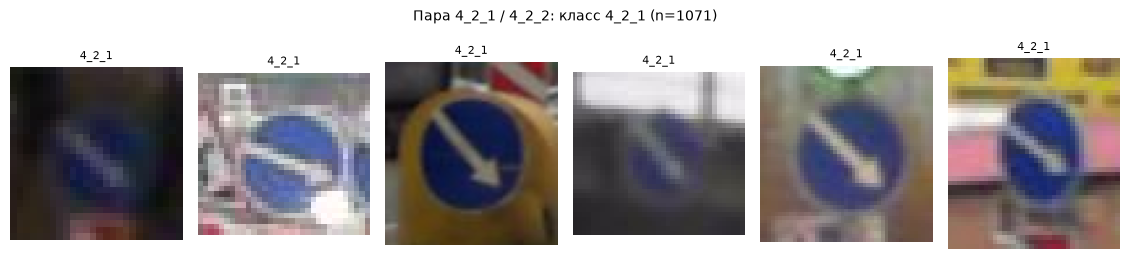

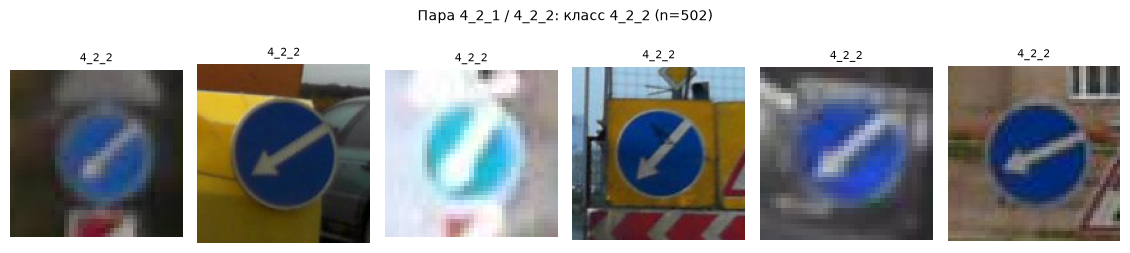

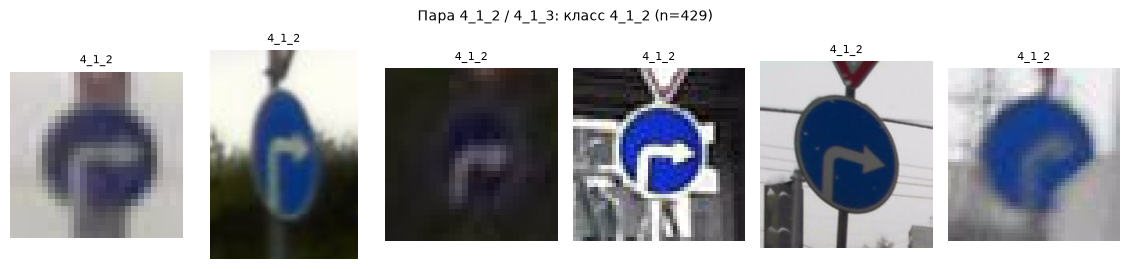

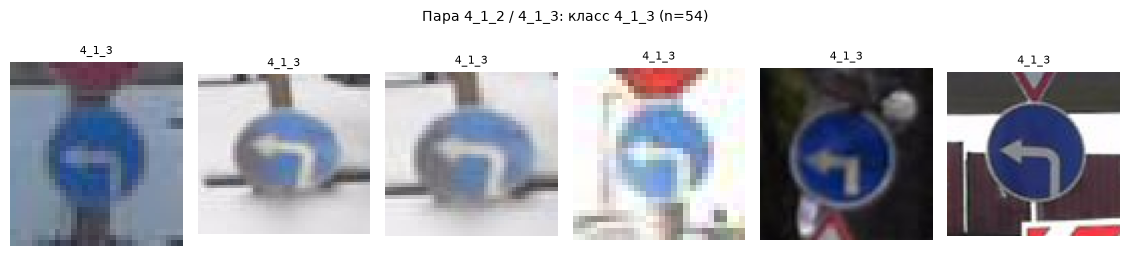

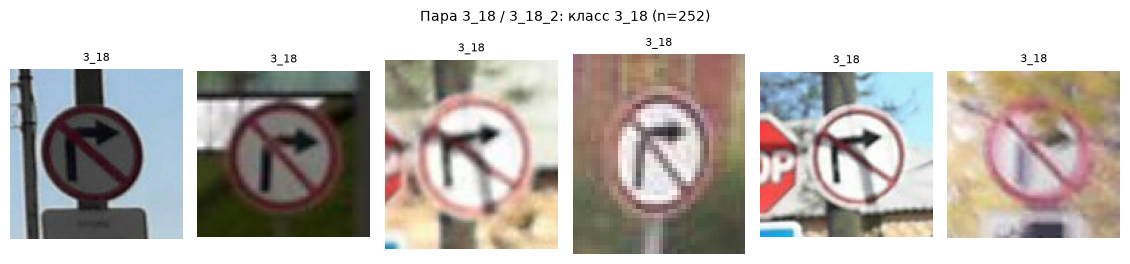

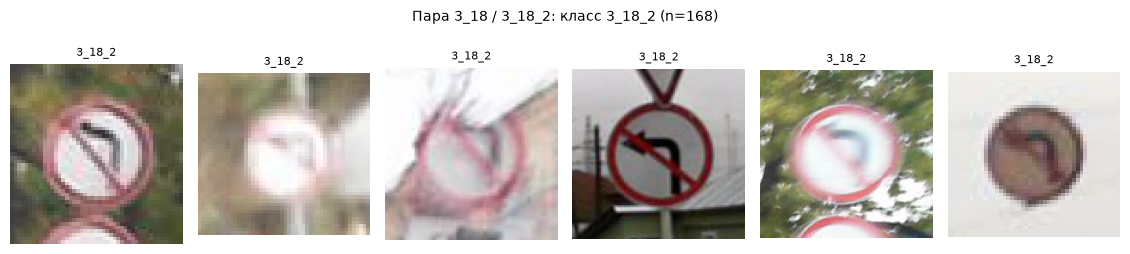

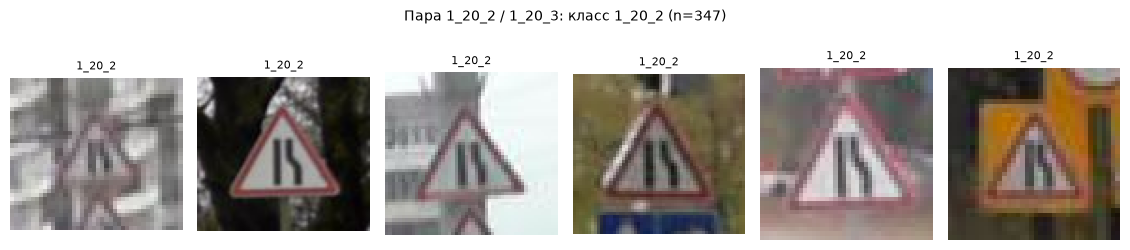

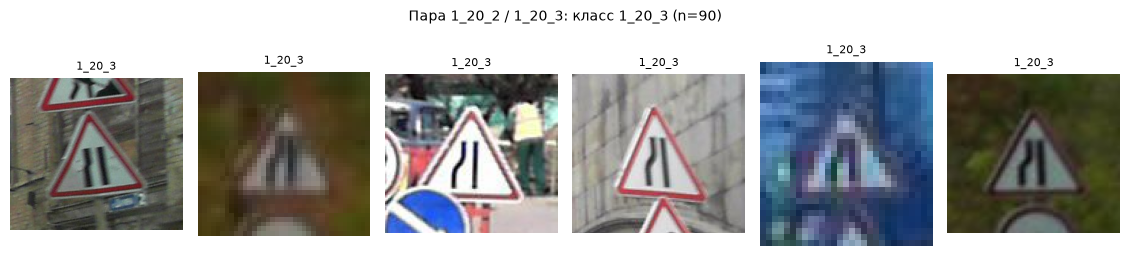

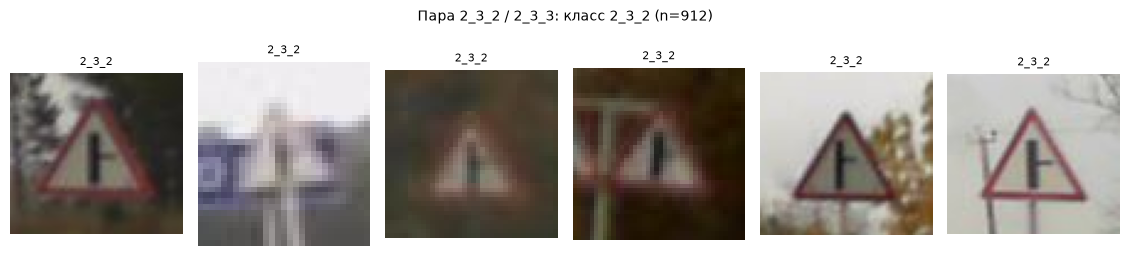

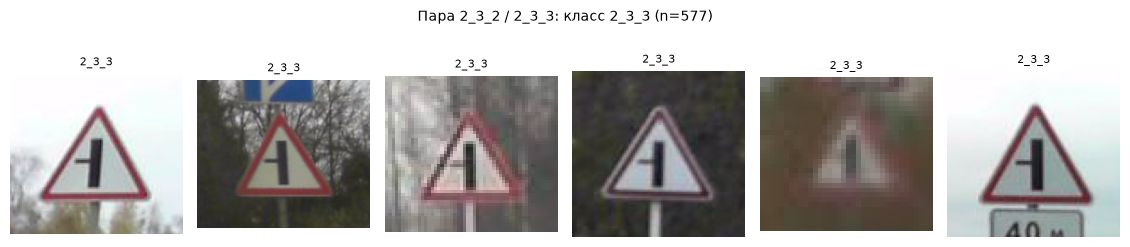

In [37]:
SIMILAR_PAIRS = [("4_2_1", "4_2_2"), ("4_1_2", "4_1_3"), ("3_18", "3_18_2"), ("1_20_2", "1_20_3"), ("2_3_2", "2_3_3")]
shown_pairs = 0
for left, right in SIMILAR_PAIRS:
    if left in counts.index and right in counts.index:
        shown_pairs += 1
        for c in (left, right):
            pool = ann[(ann.class_name == c) & (ann.split == reference)]
            gallery(pool.sample(min(6, len(pool)), random_state=SEED) if len(pool) else pool,
                    f"Пара {left} / {right}: класс {c} (n={len(pool)})")
if not shown_pairs:
    print("Ни одной пары из списка SIMILAR_PAIRS в этом датасете нет.")


### Вывод по разделу 9

> **RTSD: "watchman/rtsd-dataset":**
> 
> На просмотренных кадрах рамки совпадают со знаками, а подписи рамок читаются и не закрывают знаки. Знаки небольшие относительно кадра 1280x720 и сосредоточены в средней полосе, на одном кадре бывает до 11 знаков. Кадры сняты в разное время года и при разной погоде (снег, пасмурно, солнце), и это полезно для обучения. Вырезки классов `5_19_1`, `2_1` и `5_16` сильно различаются по размеру, освещению и чёткости, а среди `2_1` встретилась выцветшая вырезка почти без цвета.
> 
> Часть классов легко перепутать. Семейства `5_15_x` и `4_1_x` (стрелки и указатели полос) визуально похожи, а `5_15_2` на самых мелких вырезках почти не различим. Зеркальные пары (`4_2_1` и `4_2_2`, `4_1_2` и `4_1_3`, `3_18` и `3_18_2`) отличаются только направлением стрелки или поворота, и на тёмных и размытых вырезках его трудно разглядеть (у тёмной вырезки `4_1_2` стрелка почти не видна). Эти пары модель будет путать, а горизонтальное отражение превратило бы один класс в другой.
> 
> На кадре `train:52038` слева на столбе виден знак без рамки - это два знака, повёрнутые к нам обратной стороной, они предназначены для встречных водителей, так что отсутствие рамок не ошибка. Других неразмеченных знаков на просмотренных кадрах мы не нашли.
> 
> Дальше мы отдельно смотрим семейства `5_15_x` и `4_1_x` при разборе ошибок модели, просматриваем больше кадров в поиске неразмеченных знаков и выбираем несколько спорных вырезок для обсуждения.

> **RTSD cleaned: "eleldar/rtsd_cleaned":**
> 
> Кадров здесь нет, показаны только вырезки. Подписи "nan" на картинках означают, что размер вырезки не измерен: он известен только у случайных 5 000.
> 
> Вырезки одного класса сильно различаются по цвету, яркости и резкости. Например, `5_19_1` бывает светло-голубым, тёмно-синим и с жёлто-зелёным фоном, а `2_1` то жёлтый, то оранжевый, то серо-зелёный. Много размытых и тёмных вырезок, у `5_16`, `5_15_2` и `4_1_1` часть изображений почти не читается. Разнообразие условий полезно для обучения, но размытые вырезки и сходство стрелочных знаков (семейства `5_15_x` и `4_1_x`), скорее всего, дадут путаницу между такими классами.
> 
> Есть и странности. Среди `5_16` нашлась вырезка, которая выглядит как размытое изображение без видимого знака, а у `5_15_2` одна вырезка с изогнутой стрелкой отличается от остальных (там прямые стрелки). Это может быть ошибкой разметки или очень сильным размытием.
> 
> Дальше мы при разборе ошибок модели смотрим семейства `5_15_x` и `4_1_x`, проверяем, не ошибки ли отдельные вырезки (например, `5_16` без знака), и выбираем несколько спорных вырезок для обсуждения.

> **StarLine: "StarLineResearch/Russian_Road_Signs_Dataset":**
> 
> Мы посмотрели вырезки (по 8 штук на класс), и главное тут - `unknown_sign`. В нём встречаются обычные знаки: "Главная дорога", "Уступите дорогу", остановка запрещена, опасный поворот, указатель полос. Поэтому как отдельный класс он будет только мешать.
> 
> С общим `3_24` та же история: он содержит знаки с разными числами (90, 70, 60, 50 и нечитаемые), то есть пересекается с `3_24_s90`, `3_24_s70` и другими. Это объясняет часть путаниц модели (`3_24_s90` с `3_24`). Знаки `3_24_s70` и `3_24_s60` бывают и на жёлто-оранжевом, и на белом фоне.
> 
> Ещё много тёмных, размытых и частично закрытых вырезок. Рядом со знаками часто видны таблички и другие знаки, они попадают в вырезки и могут сбивать модель. `1_25` (дорожные работы) показан в разных условиях освещения, в том числе очень тёмный, а `1_20_1`, `1_20_2` и `1_20_3` различаются стороной сужения. Кадры целиком в этом разделе мы не просматривали.
> 
> Дальше мы не будем использовать `unknown_sign` и `table` как обычные классы в классификации, и нужно будет решить, что делать с общим `3_24`, посмотреть больше вырезок с табличками и соседними знаками.


## 10. Качество вырезок: яркость, контраст, резкость

Для выборки вырезок считаются три числа по серой версии картинки 32x32 пикселей (используется одинаковая подготовка, но размер исходного объекта всё равно влияет на результат):

- **яркость** - среднее значение пикселей (0 - чёрный, 255 - белый);
- **контраст** - стандартное отклонение пикселей;
- **резкость** - дисперсия лапласиана, то есть насколько меняются локальные перепады яркости. Это лишь вспомогательная оценка. Значения считаются как вещественные числа, чтобы отрицательные величины не обрезались.

Темная картинка не обязательно снята ночью, низкая резкость может быть следствием малого размера. Расчёт идёт по выборке (`QUALITY_PER_CLASS` вырезок на класс и часть для самых частых классов), а не по всему датасету.

Пропорции сохраняются, поля дополняются серым цветом. Фон, запас вокруг рамки, поля и уменьшение тоже влияют на показатели, поэтому их нельзя считать чистой объективной мерой качества знака или сравнивать с расчётом по другой подготовке. Ошибки чтения записываются отдельно, не скрываются.

In [38]:
def crop_stats(obj, out_size=32):
    """Оценки по вырезке: пропорции сохраняются, края дополняются серым."""
    crop = get_crop(obj, pad=0.15)
    gray = ImageOps.pad(crop.convert("L"), (out_size, out_size), method=Image.Resampling.LANCZOS, color=128)
    g = np.asarray(gray, dtype=float)
    lap = -4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:]
    side = float(obj["side"]) if pd.notna(obj["side"]) else np.sqrt(crop.width * crop.height)
    return g.mean(), g.std(), lap.var(), side


quality = pd.DataFrame()
quality_errors = pd.DataFrame(columns=["image_key", "annotation_id", "error"])
if HAVE_IMAGES:
    pool = ann[ann.class_name.isin(counts.index[:QUALITY_CLASSES])]
    if HAS_BOXES:
        pool = pool[(pool.w >= 4) & (pool.h >= 4)]
    sample = sample_per_group(pool, ["split", "class_name"], QUALITY_PER_CLASS)
    rows, errors = [], []
    for _, row in sample.iterrows():
        try:
            brightness, contrast, sharpness, side = crop_stats(row)
            rows.append({"annotation_id": row.annotation_id, "image_key": row.image_key, "split": row.split,
                         "class_name": row.class_name, "side": side,
                         "time_sec": image_by_key.loc[row.image_key].time_sec,
                         "brightness": brightness, "contrast": contrast, "sharpness": sharpness})
        except Exception as error:
            errors.append({"image_key": row.image_key, "annotation_id": row.annotation_id,
                           "error": f"{type(error).__name__}: {error}"})
    quality = pd.DataFrame(rows)
    quality_errors = pd.DataFrame(errors, columns=["image_key", "annotation_id", "error"])
    print("Выбрано вырезок:", len(sample), "; оценено:", len(quality), "; ошибок:", len(quality_errors))
    display(quality_errors.head(10))
    if len(quality):
        display(quality[["brightness", "contrast", "sharpness"]].describe().round(1))
else:
    print("Для раздела нужны изображения; в этом запуске он пропущен.")

Выбрано вырезок: 2400 ; оценено: 2400 ; ошибок: 0


,image_key,annotation_id,error


,brightness,contrast,sharpness
count,2400.0,2400.0,2400.0
mean,118.2,42.8,2174.0
std,37.6,15.3,2200.1
min,26.5,6.6,14.0
25%,89.8,30.6,683.3
50%,116.4,41.0,1436.0
75%,143.4,53.7,2871.7
max,224.8,96.0,18953.5


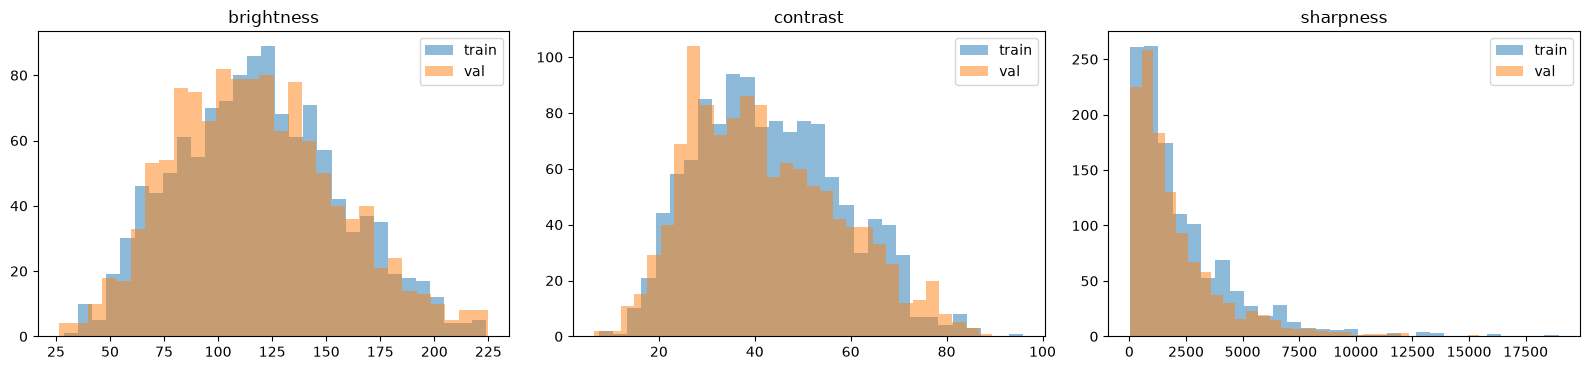

10 классов с наименьшей оценкой резкости в этой выборке (не диагноз размытия):


,вырезок,медиана_стороны,яркость,контраст,резкость
class_name,,,,,
6_6,80,27.7,107.3,36.9,650.3
4_2_1,80,29.5,118.1,43.8,702.2
5_15_5,80,26.2,94.5,36.8,909.5
3_20,80,31.5,112.4,41.9,945.9
5_15_2,80,26.7,147.3,56.1,1044.5
4_1_4,80,29.0,119.6,45.9,1056.0
4_1_1,80,31.7,112.4,45.6,1073.1
2_3_2,80,31.5,114.9,41.4,1073.1
4_2_3,80,28.5,121.3,44.3,1096.6


Связь размера знака и резкости (Спирмен): 0.6
Доля тёмных вырезок (яркость < 60): 0.047
Часы съёмки в выборке: 6 - 17


time_sec,6,7,8,9,10,11,12,13,14,15,16,17
средняя яркость по часу,116.0,122.0,111.0,105.0,115.0,125.0,128.0,115.0,124.0,124.0,92.0,159.0


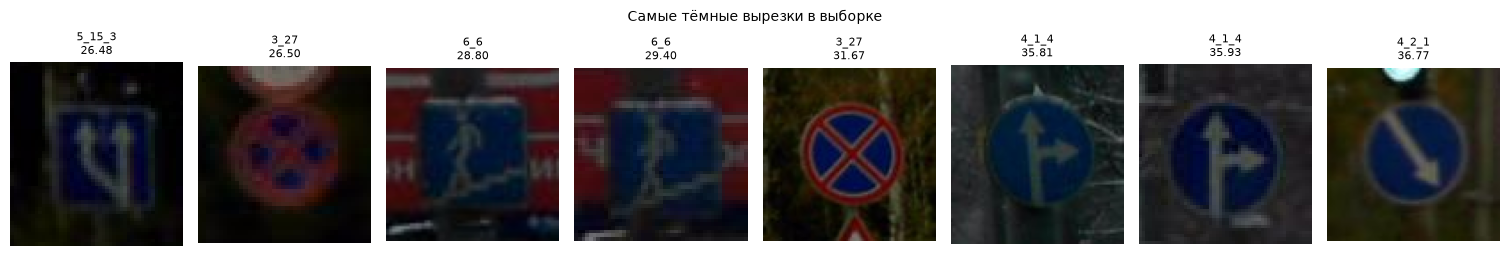

In [39]:
if len(quality):
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
    for ax, col in zip(axes, ["brightness", "contrast", "sharpness"]):
        for split, part in quality.groupby("split"):
            ax.hist(part[col], bins=30, alpha=0.5, label=split)
        ax.set_title(col); ax.legend()
    plt.tight_layout(); plt.show()

    by_class = quality.groupby("class_name").agg(вырезок=("side", "size"), медиана_стороны=("side", "median"),
                                                 яркость=("brightness", "mean"), контраст=("contrast", "mean"),
                                                 резкость=("sharpness", "median")).round(1)
    print("10 классов с наименьшей оценкой резкости в этой выборке (не диагноз размытия):")
    display(by_class.sort_values("резкость").head(10))
    if quality.side.nunique() > 1 and quality.sharpness.nunique() > 1:
        print("Связь размера знака и резкости (Спирмен):", round(quality.side.corr(quality.sharpness, method="spearman"), 2))
    print("Доля тёмных вырезок (яркость < 60):", round(float((quality.brightness < 60).mean()), 3))

    if KIND == "rtsd" and quality.time_sec.notna().any():
        hours = (quality.time_sec % 86400) // 3600        # час, записанный в имени; это не перевод в UTC
        print("Часы съёмки в выборке:", int(hours.min()), "-", int(hours.max()))
        display(quality.groupby(hours.astype("Int64")).brightness.mean().round(0).to_frame("средняя яркость по часу").T)

    dark = quality.sort_values("brightness").merge(ann, on=["annotation_id", "image_key", "split"], suffixes=("", "_a"))
    gallery(dark, "Самые тёмные вырезки в выборке", caption_cols=("class_name", "brightness"))
else:
    print("Данных о качестве нет.")

### 10.1. Когда сняты кадры: час, месяц, день

В разделе 10 часы считались по выборке вырезок. Здесь то же самое по всем кадрам: в какие часы, месяцы и дни они сняты и сколько общих дней у разных частей. Время берётся из имени файла (`RTSD`) или из метки времени (`StarLine`)- это записанное в данных время. Для `cleaned` ячейка пропускается - времени там нет.


In [40]:
frame_time = active_images.dropna(subset=["time_sec"]).copy()
if len(frame_time):
    stamp = pd.to_datetime(frame_time.time_sec, unit="s")
    frame_time["час"], frame_time["месяц"], frame_time["день"] = stamp.dt.hour, stamp.dt.month, stamp.dt.date
    print(f"Время известно у {len(frame_time)} из {len(active_images)} кадров. Часы съёмки: {frame_time['час'].min()} - {frame_time['час'].max()}")
    print("Доля кадров по часам, % внутри части:")
    display(pd.crosstab(frame_time["час"], frame_time.split, normalize="columns").mul(100).round(1).T)
    print("Доля кадров по месяцам, % внутри части:")
    display(pd.crosstab(frame_time["месяц"], frame_time.split, normalize="columns").mul(100).round(1).T)
    days = frame_time.groupby("split")["день"].agg(lambda s: set(s))
    print("Дней съёмки по частям:", {k: len(v) for k, v in days.items()})
    if len(days) > 1:
        shared_days = set.intersection(*days.tolist())
        print("Дней, общих для всех частей:", len(shared_days))
else:
    print("Времени съёмки нет: ячейка пропущена.")


Время известно у 59188 из 59188 кадров. Часы съёмки: 6 - 17
Доля кадров по часам, % внутри части:


час,6,7,8,9,10,11,12,13,14,15,16,17
split,,,,,,,,,,,,
train,1.1,1.8,8.7,15.7,12.4,19.7,14.6,12.0,7.9,5.6,0.3,0.1
val,1.0,1.9,8.4,15.5,12.3,19.1,14.2,13.1,8.2,5.8,0.4,0.1


Доля кадров по месяцам, % внутри части:


месяц,1,2,4,10,11
split,,,,,
train,4.9,5.0,19.1,68.0,2.9
val,4.9,4.7,19.4,68.0,2.9


Дней съёмки по частям: {'train': 12, 'val': 12}
Дней, общих для всех частей: 12


### 10.2. Яркость и резкость кадра целиком

Раздел 10 оценивал вырезки знаков. Здесь та же идея для кадров целиком: берётся случайная выборка кадров (`FRAME_QUALITY_SAMPLE`), каждый уменьшается и переводится в серый, считаются яркость, контраст и резкость (дисперсия лапласиана). Кадр считается тёмным, если средняя яркость ниже `DARK_FRAME_LIMIT`. Порог выше, чем у вырезок (60), потому что на кадре много неба и дороги, поэтому проценты нельзя сравнивать с разделом 10 напрямую.

Расчёт по выборке. Для `cleaned` ячейка пропускается.


In [41]:
frame_quality = pd.DataFrame()
if HAS_BOXES and HAVE_IMAGES and FRAME_QUALITY_SAMPLE:
    pool_frames = active_images[active_images.image_key.isin(ann.image_key)]
    frame_sample = pool_frames.sample(min(FRAME_QUALITY_SAMPLE, len(pool_frames)), random_state=SEED)
    frame_rows, frame_errors = [], 0
    for _, frame in frame_sample.iterrows():
        try:
            with Image.open(get_source(frame)) as im:
                im.draft("L", (640, 640))
                gray = im.convert("L")
            gray.thumbnail((480, 480))
            g = np.asarray(gray, dtype=float)
            lap = -4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:]
            frame_rows.append({"image_key": frame.image_key, "split": frame.split, "time_sec": frame.time_sec,
                               "brightness": g.mean(), "contrast": g.std(), "sharpness": lap.var()})
        except Exception:
            frame_errors += 1
    frame_quality = pd.DataFrame(frame_rows)
    print(f"Кадров в выборке: {len(frame_sample)}; оценено: {len(frame_quality)}; ошибок чтения: {frame_errors}")
    if len(frame_quality):
        display(frame_quality.groupby("split")[["brightness", "contrast", "sharpness"]].median().round(1))
        print(f"Доля тёмных кадров (яркость < {DARK_FRAME_LIMIT}), % внутри части:")
        display((frame_quality.brightness.lt(DARK_FRAME_LIMIT).groupby(frame_quality.split).mean() * 100).round(1).to_frame("тёмных кадров, %").T)
        if frame_quality.time_sec.notna().any():
            frame_hours = (pd.to_datetime(frame_quality.time_sec, unit="s")).dt.hour
            print("Средняя яркость кадра по часам:")
            display(frame_quality.groupby(frame_hours).brightness.mean().round(0).to_frame("яркость").T)
else:
    print("Нужны кадры (не вырезки) и непустой FRAME_QUALITY_SAMPLE: ячейка пропущена.")


Кадров в выборке: 1000; оценено: 1000; ошибок чтения: 0


,brightness,contrast,sharpness
split,,,
train,136.1,75.5,499.7
val,131.2,76.6,467.2


Доля тёмных кадров (яркость < 100), % внутри части:


split,train,val
"тёмных кадров, %",1.1,1.1


Средняя яркость кадра по часам:


time_sec,6,7,8,9,10,11,12,13,14,15,16,17
яркость,108.0,105.0,135.0,132.0,135.0,138.0,138.0,134.0,135.0,132.0,136.0,139.0


### Вывод по разделу 10

> **RTSD: "watchman/rtsd-dataset":**
> 
> Мы оценили выборку вырезок: 30 самых частых классов, по 40 на класс и часть, всего 2 400, ошибок чтения нет. Средняя яркость 118 (от 26 до 225), средний контраст 43, медиана резкости 1 436 (от 14 до 18 954). Тёмных вырезок (яркость ниже 60) 4,7%. Распределения в train и val почти совпадают. Связь размера знака и резкости 0,6: чем крупнее знак, тем резче вырезка. Классы с наименьшей резкостью (`6_6`, `4_2_1`, `5_15_5`, `3_20`, `5_15_2`) одновременно мелкие (медиана стороны 26-32 пикселя), так что низкая резкость в основном объясняется малым размером, а не плохой съёмкой. Самые тёмные вырезки (яркость 26-37) - настоящие знаки (`5_15_3`, `3_27`, `6_6`, `4_1_4`, `4_2_1`): они узнаются, но контраст у них низкий.
> 
> По всем кадрам съёмка идёт с 6 до 17 часов, основная масса (97%) с 8 до 15 часов, а в 16 и 17 часов вместе не более 0,5%. По месяцам: октябрь 68%, апрель 19%, январь 5%, февраль 5%, ноябрь 3%. Всего 12 дней съёмки. По выборке из 1 000 кадров целиком средняя яркость кадра 136 (train) и 131 (val), тёмных кадров (яркость ниже 100) 1,1%. Самая низкая яркость в 6-7 часов (105-108 против 132-139 днём), то есть тёмные кадры, по-видимому, утренние. Ночных и вечерних кадров в датасете нет, поэтому работу в темноте по нему проверить нельзя.
> 
> Оценка по вырезкам сделана на выборке из частых классов, а не на всех объектах.
> 
> Дальше мы включаем в аугментации изменение яркости, контраста и размытие (раздел 13), отдельно оцениваем качество модели на тёмных и мелких знаках и фиксируем в ограничениях проекта, что ночных изображений нет.

> **RTSD cleaned: "eleldar/rtsd_cleaned":**
> 
> Мы оценили 1 200 вырезок (30 самых частых классов, по 40 на класс), ошибок чтения нет. Средняя яркость 112 (от 28 до 233), средний контраст 38, медиана резкости 968 (от 17 до 17 334). Тёмных вырезок (яркость ниже 60) 4,2%. Связь размера знака и резкости 0,64. Меньше всего резкость у `5_15_5`, `6_4`, `4_2_1`, `4_1_1`, `6_6`, и у этих классов медиана стороны 24-31 пиксель. Как и в `RTSD`, низкая резкость связана с малым размером знака.
> 
> Вырезки чуть темнее и менее контрастны, чем в `RTSD` (контраст 38 против 43). Но это выборка из 40 вырезок на класс, поэтому считать это настоящим различием между датасетами нельзя. Время съёмки неизвестно, кадров нет, так что часы, месяцы и качество кадров целиком посчитать невозможно, а значит, освещение по времени суток проверить нельзя.
> 
> Дальше мы используем те же аугментации яркости, контраста и размытия, что и для `RTSD`, и не переносим оценку качества по частым классам на редкие.

> **StarLine: "StarLineResearch/Russian_Road_Signs_Dataset":**
> 
> Мы оценили 1 200 вырезок из train (30 самых частых классов, по 40 на класс), ошибок чтения нет. Средняя яркость 98 (от 9 до 237), средний контраст 39, медиана резкости 1 307 (от 8 до 12 822). Тёмных вырезок (яркость ниже 60) 15,6%, это в 3-4 раза больше, чем в `RTSD` и `cleaned` (4-5%). Связь размера знака и резкости 0,61. Меньше всего резкость у `3_24_s60`, `3_24_s50`, `4_2_2`, `3_25_s60_white` и `3_25`, и часть из них очень тёмная (у `3_25_s60_white` средняя яркость 45).
> 
> По всем кадрам train съёмка идёт с 7 до 20 часов, основная масса с 9 до 13 часов, а в 20 часов снято 3% кадров. По месяцам: май 36,5%, июль 27,4%, сентябрь 19,5%, июнь 13,4%, август и ноябрь по 1,6%. Всего 16 дней съёмки. По выборке из 1 000 кадров целиком средняя яркость кадра 114, контраст 63, тёмных кадров (яркость ниже 100) 3,3%. В 20 часов средняя яркость кадра всего 22, а в остальные часы 106-116. То есть в `StarLine` есть сумеречные или ночные кадры, и он полезнее `RTSD` для проверки устойчивости к освещению.
> 
> Выборки не показывают долю тёмных кадров и вырезок во всём датасете, а кадров в 20 часов в выборке мало. Время мы взяли из метки времени, местное время и год всех кадров не проверяли (по первым строкам разметки `test` - 2023 год).
> 
> Дальше мы усиливаем аугментации яркости и контраста, отдельно оцениваем качество на тёмных знаках и проверяем по картинкам, что кадры в 20 часов действительно ночные, а не ошибка времени.


## 11. Независимость обучения и проверки

**Утечка данных (data leakage)** - ситуация, когда проверка получает информацию, недоступную при оценке на новых данных. Соседние кадры могут быть почти одинаковыми, а один физический знак - появляться на нескольких кадрах подряд. Если такие кадры попали в разные части датасета, модель может узнавать знакомое, и оценка на проверочной части окажется завышенной. Общий `SEED` делает выборку повторяемой, но не делает части независимыми.

Ниже четыре признака риска:

1. **Близость по времени** между частями (`RTSD`: время из имён файлов, `StarLine`: из `timestamp_ns`, если единицы действительно наносекунды).
2. **Последовательности**: кадры с паузой меньше `GAP_SECONDS` объединяются. Считается, сколько последовательностей содержат кадры из нескольких частей. Группировка предварительная: повторный проезд того же места тоже возможен.
3. **Общие идентификаторы объектов** (`group_id`) между частями.
4. **Точные копии** изображений (по запросу, `HASH_LIMIT > 0`).

Раздел использует только время и идентификаторы, поэтому затрагивает и часть `test`, но не изучает её классы и качество.

Последовательности кадров мы определяем по паузе между ними (по умолчанию 10 секунд). Это приблизительная группировка: в данных нет настоящего идентификатора поездки, поэтому один проезд может оказаться разбит на несколько последовательностей, а разные проезды - склеены в одну. Кадры разных камер могут быть сняты почти в одно время, но показывать разные места.
Для `StarLine` время записано числом `timestamp_ns`. Мы используем его только для сравнения "какой кадр ближе по времени", а не для того, чтобы вычислять дату или время суток.

In [42]:
def nearest_gap(reference_times, other_times):
    """Для каждого времени из other_times - расстояние (с) до ближайшего времени из reference_times."""
    ref = np.sort(np.asarray(reference_times, dtype=float))
    other = np.asarray(other_times, dtype=float)
    if len(ref) == 0 or len(other) == 0:
        return np.array([])
    i = np.searchsorted(ref, other)
    left, right = ref[np.clip(i - 1, 0, len(ref) - 1)], ref[np.clip(i, 0, len(ref) - 1)]
    return np.minimum(np.abs(other - left), np.abs(right - other))


leak_facts = {}
seq_map = pd.Series(dtype=float)           # image_key -> номер последовательности (используется в разделе 14)
timed = images[images.split != "reduced"].copy()
timed = timed[np.isfinite(timed.time_sec)]
print("Кадров с известным временем:", len(timed), "из", len(images))

if timed.split.nunique() > 1 and reference in set(timed.split):
    for other in [s for s in timed.split.unique() if s != reference]:
        gaps = nearest_gap(timed.loc[timed.split == reference, "time_sec"], timed.loc[timed.split == other, "time_sec"])
        for t in (5, 30, 60, 300):
            share = float((gaps <= t).mean())
            leak_facts[f"{other}: доля кадров с соседом из {reference} ближе {t} с"] = round(share, 3)
            print(f"Часть {other}: у {share:.1%} кадров есть кадр из {reference} ближе {t} с")

    ordered = timed.sort_values("time_sec").copy()
    ordered["seq_id"] = (ordered.time_sec.diff().fillna(0) > GAP_SECONDS).cumsum()
    seq = ordered.groupby("seq_id").agg(кадров=("image_key", "size"), частей=("split", "nunique"))
    mixed = int((seq["частей"] > 1).sum())
    seq_map = ordered.set_index("image_key").seq_id
    leak_facts["последовательностей"] = int(len(seq))
    leak_facts["последовательностей с кадрами из нескольких частей"] = mixed
    print(f"\nПри паузе {GAP_SECONDS} с получилось последовательностей: {len(seq)}; "
          f"содержат кадры из нескольких частей: {mixed} ({mixed / len(seq):.0%})")
    display(seq["кадров"].describe().round(1).to_frame("кадров в последовательности"))
    days = ordered.assign(day=ordered.time_sec // 86400).groupby("split").day.agg(set)   # номер суток от 1970 года
    if "train" in days.index and "val" in days.index:
        print("Дней съёмки: train", len(days["train"]), "| val", len(days["val"]), "| общих", len(days["train"] & days["val"]))
else:
    print("Для проверки по времени нужны время кадров и хотя бы две части: раздел пропущен.")

Кадров с известным временем: 59188 из 59188
Часть val: у 99.8% кадров есть кадр из train ближе 5 с
Часть val: у 100.0% кадров есть кадр из train ближе 30 с
Часть val: у 100.0% кадров есть кадр из train ближе 60 с
Часть val: у 100.0% кадров есть кадр из train ближе 300 с

При паузе 10 с получилось последовательностей: 2868; содержат кадры из нескольких частей: 1893 (66%)


,кадров в последовательности
count,2868.0
mean,20.6
std,22.9
min,1.0
25%,7.0
50%,13.0
75%,26.0
max,273.0


Дней съёмки: train 12 | val 12 | общих 12


In [43]:
from itertools import combinations

grouped = objects[objects.split != "reduced"].dropna(subset=["group_id"])
if len(grouped):
    id_sets = grouped.groupby("split").group_id.agg(set)
    print("Различных group_id по частям:", {s: len(v) for s, v in id_sets.items()})
    for a, b in combinations(id_sets.index, 2):
        overlap = id_sets[a] & id_sets[b]
        smaller = max(min(len(id_sets[a]), len(id_sets[b])), 1)
        leak_facts[f"общих group_id: {a} и {b}"] = len(overlap)
        print(f"{a} и {b}: общих значений group_id = {len(overlap)} ({len(overlap) / smaller:.0%} от меньшей части). "
              "Смысл и область уникальности group_id не подтверждены.")
else:
    print("Идентификаторов объектов нет: проверка пропущена.")

Идентификаторов объектов нет: проверка пропущена.


In [44]:
# Проверка только для cleaned: совпадает ли порядок строк с разметкой RTSD
if KIND == "cleaned":
    first = objects.head(5)[["class_name", "group_id"]].copy()
    sizes = [image_size(image_by_key.loc[key]) for key in objects.head(5).image_key]
    first["w"], first["h"] = zip(*sizes)
    display(first)
    print("В RTSD первые рамки: 18x18, 20x21, 27x26, 37x36, 17x17; первые четыре - класс 2_1.")
else:
    print("Проверка относится только к cleaned.")

Проверка относится только к cleaned.


In [45]:
# Проверка только для cleaned: делится ли датасет на те же части, что RTSD, и есть ли общие знаки
if KIND == "cleaned":
    first_part = objects.iloc[:95492]
    rest = objects.iloc[95492:]
    print(first_part.class_name.value_counts().loc[["5_19_1", "2_1", "5_16"]])
    print("В RTSD train: 5_19_1 = 22147, 2_1 = 10027, 5_16 = 4727")
    ids_first, ids_rest = set(first_part.group_id), set(rest.group_id)
    print("различных sign_id в первой части:", len(ids_first),
          "| во второй части:", len(ids_rest), "| общих:", len(ids_first & ids_rest))
else:
    print("Проверка относится только к cleaned.")

Проверка относится только к cleaned.


In [46]:
# Проверки только для cleaned: что означает sign_id
if KIND == "cleaned":
    classes_per_sign = objects.groupby("group_id").class_name.nunique()
    crops_per_sign = objects.groupby("group_id").size()
    print("Строки идут по возрастанию sign_id:", objects.group_id.is_monotonic_increasing)
    print("Знаков с одним классом:", int((classes_per_sign == 1).sum()), "из", len(classes_per_sign))
    print("Максимум разных классов у одного sign_id:", int(classes_per_sign.max()))
    display(crops_per_sign.describe().round(1).to_frame("вырезок на один sign_id"))
else:
    print("Проверка относится только к cleaned.")

Проверка относится только к cleaned.


In [47]:
# Только для cleaned: смотрим вырезки с одним sign_id (первый знак и знак с максимумом вырезок)
if KIND == "cleaned":
    for sid in [objects.group_id.iloc[0], crops_per_sign.idxmax()]:
        gallery(ann[ann.group_id == sid], f"sign_id = {sid}", n=8, caption_cols=("class_name", "side"))
else:
    print("Проверка относится только к cleaned.")

Проверка относится только к cleaned.


In [48]:
hashes = pd.DataFrame(columns=["image_key", "split", "pixel_hash"])
if HASH_LIMIT and HAVE_IMAGES:
    rows = []
    for split, part in active_images.groupby("split"):
        for _, row in part.sample(min(HASH_LIMIT, len(part)), random_state=SEED).iterrows():
            try:
                im = open_image(row).convert("RGB")
                rows.append({"image_key": row.image_key, "split": split,
                             "pixel_hash": hashlib.sha256(str(im.size).encode() + im.tobytes()).hexdigest()})
            except Exception:
                continue
    hashes = pd.DataFrame(rows, columns=["image_key", "split", "pixel_hash"])
    shared = hashes.groupby("pixel_hash").split.nunique()
    copies = hashes[hashes.pixel_hash.isin(shared[shared > 1].index)]
    if hashes.split.nunique() < 2:
        leak_facts["записей с точной копией в другой части (в выборке)"] = "не проверено: проверена одна часть"
        print("ВНИМАНИЕ: проверена только одна часть датасета, сравнивать не с чем. Ноль копий здесь ничего не доказывает.")
    else:
        leak_facts["записей с точной копией в другой части (в выборке)"] = int(len(copies))
    print(f"Проверено изображений: {len(hashes)} (по частям: {hashes.split.value_counts().to_dict()}); записей с точной копией в другой части: {len(copies)}")
    display(copies.head(20))
    print("Проверка точная, но ограничена выборкой; похожие, но не одинаковые кадры она не находит.")
else:
    print("Поиск точных копий выключен (HASH_LIMIT = 0): отсутствие копий не проверено.")

Проверено изображений: 15000 (по частям: {'train': 10000, 'val': 5000}); записей с точной копией в другой части: 4


,image_key,split,pixel_hash
842,train:37327,train,f48922e763f767fd7613248056ebecaed8ba375da40dea3985cb42288ae5f4ad
5788,train:36330,train,04da047dd4def047f12508f3214262bc93435aa94468824fb13bb083363bd906
11011,val:37326,val,f48922e763f767fd7613248056ebecaed8ba375da40dea3985cb42288ae5f4ad
13648,val:36331,val,04da047dd4def047f12508f3214262bc93435aa94468824fb13bb083363bd906


Проверка точная, но ограничена выборкой; похожие, но не одинаковые кадры она не находит.


**Сравнение частей по именам файлов.** Быстрая проверка: есть ли в разных частях файлы с одинаковым именем. Она не заменяет побайтовое сравнение выше? одинаковые кадры могут называться по-разному. Проверка нужна только для `RTSD`.


In [49]:
if KIND == "rtsd" and active_images.split.nunique() > 1:
    names_by_split = active_images.groupby("split").file_name.agg(set)
    shared_names = set.intersection(*names_by_split.tolist())
    print("Файлов с одинаковым именем в разных частях:", len(shared_names))
    print("Побайтовое сравнение (выше) находит одинаковые кадры и с разными именами.")
else:
    print("Проверка по именам нужна только для RTSD с несколькими частями: пропущена.")


Файлов с одинаковым именем в разных частях: 0
Побайтовое сравнение (выше) находит одинаковые кадры и с разными именами.


### Вывод по разделу 11

> **RTSD: "watchman/rtsd-dataset":**
> 
> Здесь главная проблема датасета. У 99,8% кадров `val` есть кадр из `train`, снятый ближе чем за 5 секунд, то есть почти такая же картинка. Все 12 дней съёмки общие для обеих частей. Мы объединили кадры в последовательности (пауза между ними 10 секунд): из 2 868 последовательностей 1 893 (66%) содержат кадры обеих частей. Идентификаторов объектов нет.
> 
> Мы также искали точные копии кадров на 15 000 кадрах (все 5 000 из `val` и 10 000 случайных из `train`) и нашли 2 пары побайтово одинаковых кадров в train и val. Файлов с одинаковым именем в разных частях нет, значит, эти кадры лежат под разными именами и проверки по именам недостаточно. Из `train` мы проверили около 18% кадров (10 000 из 54 188), поэтому всего таких пар может быть больше.
> 
> Вывод: официальная проверка, вероятно, не независима, и метрики на ней могут быть завышены. Делить по дням, как в официальном разбиении, нельзя (все 12 дней есть в обеих частях), но можно заново выделить test из целых дней. Сколько кадров в каждом дне, мы пока не посчитали.
> 
> Дальше мы обсудим деление по последовательностям или по целым дням и проверим, как оно зависит от порога паузы. Считаем число кадров по дням, а результаты на официальном `val` считаем ориентировочными. Отдельно надо решить, нужно ли искать копии по всему `train`.

> **RTSD cleaned: "eleldar/rtsd_cleaned":**
> 
> Времени съёмки и частей здесь нет, поэтому проверить независимость по времени и между частями нельзя, а проверка копий пустая: часть одна.
> 
> Зато мы подтвердили смысл `sign_id` (в таблицах он называется `group_id`). У всех 15 628 знаков ровно один класс, в среднем на знак приходится 6,7 вырезки (медиана 6, максимум 63). Размеры первых вырезок (18x18, 20x21, 27x26, 37x36, класс `2_1`) совпали с первыми рамками `RTSD`. Мы посмотрели галерею: у `sign_id = 0` пять вырезок класса `2_1` ("Главная дорога") показывают один и тот же знак, а у `sign_id = 15009` восемь вырезок класса `5_15_1` ("Направления движения по полосам", три полосы: налево, прямо, прямо и направо) тоже показывают один знак.
> 
> Из этого следует, что вырезки одного знака почти одинаковы, и случайное деление по вырезкам завысило бы качество. Поэтому нужно делить по `sign_id`. Но даже так вырезки разных знаков из соседних кадров и дней могут быть похожи по сцене, а проверить это мы не можем. Строки идут не по порядку `sign_id`, поэтому деление `RTSD` на `train` и `val` по порядку строк восстановить нельзя.
> 
> Дальше мы можем поделить по `sign_id` (`GroupShuffleSplit` с группами), записать в выводах, что независимость по сценам и дням не доказана, и мы будем считать метрики предварительными.

> **StarLine: "StarLineResearch/Russian_Road_Signs_Dataset":**
> 
> Здесь разделение train и test выглядит чище, чем в `RTSD`. У кадров `test` нет кадров `train` ближе 5 и 30 секунд, ближе 60 секунд есть у 0,2%, ближе 300 секунд - у 17,7%. Из 115 последовательностей (в среднем 56 кадров) ни одна не содержит кадров обеих частей. Кадры `train` сняты в 16 разных днях.
> 
> Но есть оговорки. У 18% кадров `test` есть кадр `train` в пределах пяти минут, вероятно, с того же маршрута. Кадры идут с интервалом около 0,1 секунды (по первым строкам разметки), поэтому соседние кадры внутри последовательности почти одинаковы, и случайное деление `train` по кадрам даст завышенные метрики. `group_id` для деления не подходит: у него 34 значения в `train` и 55 в `test`, все 34 из `train` встречаются в `test`, и на идентификатор поездки или знака он не похож. Точные копии между `train` и `test` мы не проверяли, потому что загружен только `train`.
> 
> Дальше можно поделить `train` по временным последовательностям или по дням, уточнить, не повторяют ли кадры `test` маршруты `train`, выяснить смысл `group_id` и проверить точные копии между частями, когда решим открывать `test`.


## 12. RTSD: файл `train_anno_reduced.json`

В черновом ноутбуке обнаружилось, что "сокращённая" разметка может не быть простой уменьшенной копией `train`: у части кадров в ней меньше рамок, чем в `train`, встречаются повторы. Блок сравнивает сочетания "файл + класс + координаты", а не только число рамок - одинаковые счётчики не означают одинаковый состав. Раздел относится только к `RTSD`.

Если кадр попал в сокращённую разметку, а часть его знаков не размечена, настоящие знаки превращаются в фон. Безопасный вариант для отладки - несколько кадров из полного `train` вместе со всеми их рамками (ниже).

In [50]:
reduced_report = pd.DataFrame()
debug_frames = []
if KIND != "rtsd":
    print("Раздел относится только к RTSD: пропущен.")
elif not has_file(data_root, "train_anno_reduced.json"):
    print("train_anno_reduced.json не найден: аудит пропущен, пригодность файла не подтверждена.")
else:
    red = json.loads(find_unique_file(data_root, "train_anno_reduced.json").read_text(encoding="utf-8"))
    names_by_id = {r["id"]: r["file_name"] for r in red["images"]}
    cats = {c["id"]: str(c["name"]) for c in red["categories"]}
    red_df = pd.DataFrame([{"file_name": names_by_id.get(a["image_id"]), "class_name": cats.get(a["category_id"]),
                            **dict(zip("xywh", parse_bbox(a["bbox"])))} for a in red["annotations"]], columns=["file_name", "class_name", "x", "y", "w", "h"])
    full = (objects[objects.split == "train"]
            .merge(images[["image_key", "file_name"]], on="image_key", how="left", validate="many_to_one"))
    keys = ["file_name", "class_name", "x", "y", "w", "h"]
    red_ok, full_ok = red_df.dropna(subset=keys), full.dropna(subset=keys)
    full_on_red_frames = full_ok[full_ok.file_name.isin(set(names_by_id.values()))]
    full_set = set(full_on_red_frames[keys].itertuples(index=False, name=None))
    red_set = set(red_ok[keys].itertuples(index=False, name=None))

    both = pd.concat([full_on_red_frames.groupby("file_name").size(), red_ok.groupby("file_name").size()],
                     axis=1, keys=["train", "reduced"]).fillna(0)
    per_class = red_ok.class_name.value_counts()
    reduced_report = pd.DataFrame({
        "рамок в reduced": [len(red_df)], "кадров в reduced": [len(red["images"])], "ошибочных строк reduced": [len(red_df) - len(red_ok)],
        "повторяющихся рамок в reduced": [int(red_ok.duplicated(keys).sum())],
        "рамок на кадрах reduced, которых нет в reduced": [len(full_set - red_set)],
        "рамок в reduced, которых нет в train": [len(red_set - full_set)],
        "кадров, где в reduced рамок меньше, чем в train": [int((both.reduced < both.train).sum())],
        "мин./макс. рамок на класс": [f"{per_class.min()}/{per_class.max()}" if len(per_class) else "нет данных"]}).T
    reduced_report.columns = ["значение"]
    display(reduced_report)

    # безопасная отладочная выборка: кадры из полного train вместе со всеми их рамками
    pool = images[(images.split == "train") & images.image_key.isin(objects.image_key)]
    debug_frames = list(pool.sample(min(200, len(pool)), random_state=SEED).image_key)
    print(f"Отладочная выборка: {len(debug_frames)} кадров из полного train; рамок на них: "
          f"{int(objects.image_key.isin(debug_frames).sum())}, классов: {objects[objects.image_key.isin(debug_frames)].class_name.nunique()}")

,значение
рамок в reduced,2325
кадров в reduced,1889
ошибочных строк reduced,0
повторяющихся рамок в reduced,378
"рамок на кадрах reduced, которых нет в reduced",2645
"рамок в reduced, которых нет в train",0
"кадров, где в reduced рамок меньше, чем в train",1157
мин./макс. рамок на класс,15/15


Отладочная выборка: 200 кадров из полного train; рамок на них: 350, классов: 65


### 12.1. Какие группы знаков попали в `reduced`

Сравнение долей групп знаков (раздел 6.2) в `train`, `reduced` и `val`. Если доли в `reduced` сильно отличаются от `train`, файл не отражает весь датасет: он собран по правилу "15 рамок на класс", поэтому редкие группы в нём раздуты. Раздел относится только к `RTSD`.


In [51]:
if KIND == "rtsd" and "red_ok" in globals() and len(red_ok):
    def group_of(class_names):
        number = class_names.str.extract(r"^(\d+)")[0].astype(float)
        return number.map(GROUP_NAMES).fillna("не по шаблону ПДД")
    shares = pd.DataFrame({
        "train, %": group_of(objects.loc[objects.split == "train", "class_name"]).value_counts(normalize=True) * 100,
        "reduced, %": group_of(red_ok.class_name).value_counts(normalize=True) * 100,
        "val, %": group_of(objects.loc[objects.split == "val", "class_name"]).value_counts(normalize=True) * 100,
    }).fillna(0).round(1)
    display(shares)
else:
    print("Нужен аудит reduced (RTSD): ячейка пропущена.")


,"train, %","reduced, %","val, %"
0,,,
1 Предупреждающие,9.6,19.4,9.4
2 Приоритета,17.6,7.7,17.4
3 Запрещающие,13.1,16.1,12.8
4 Предписывающие,7.5,9.7,7.4
5 Особых предписаний,43.1,14.8,44.1
6 Информационные,3.6,7.7,3.6
7 Сервиса,2.3,7.7,2.2
8 Таблички,3.3,16.8,3.0


### Вывод по разделу 12

> **RTSD: "watchman/rtsd-dataset":**
> 
> В файле `reduced` 2 325 рамок на 1 889 кадрах, ровно по 15 рамок на каждый из 155 классов. 378 рамок из них повторяются. Файл собирали не целыми кадрами, а выборкой 15 рамок на класс, поэтому разметка его кадров неполная - на кадрах `reduced` не хватает 2 645 рамок, которые есть в полном `train`, и на 1 157 из 1 889 кадров (61%) рамок меньше, чем в `train`. Рамок, которых нет в `train`, нет.
> 
> Состав тоже не похож на весь датасет. Особых предписаний в `reduced` 14,8% против 43,1% в `train`, предупреждающих 19,4% против 9,6%, табличек 16,8% против 3,3%, сервиса 7,7% против 2,3%. А `val` почти совпадает с `train`.
> 
> Из-за неполной разметки настоящие знаки на этих кадрах не размечены, и при обучении детектора они превратились бы в фон. Поэтому для оценки качества и отладки детекции файл не подходит.
> 
> Дальше мы можем взять кадры из полного `train` вместе со всеми их рамками (отладочная выборка из раздела 12: 200 кадров, 350 рамок, 65 классов). `reduced` годится только для быстрой проверки кода классификации вырезок, но не для оценки качества.

> **RTSD cleaned и StarLine:**
> 
> Раздел к этим датасетам не относится (файла `train_anno_reduced.json` в них нет), поэтому мы его пропустили.


## 13. Аугментации: какие преобразования подходят задаче

**Аугментация (augmentation)** - искусственное изменение обучающих картинок (яркость, небольшой поворот, размытие), чтобы модель меньше зависела от условий съёмки. Не всякое изменение безопасно для дорожных знаков. Пункт входит в требования чекпоинта, поэтому преобразования показаны на прочитанных вырезках нескольких классов (на копиях, исходные данные не меняются). Если картинки недоступны, этот пункт пока не выполнен.

- Горизонтальное отражение меняет смысл направленных знаков (стрелки, повороты, объезд препятствия) и зеркалит цифры и текст. Список классов ниже - для проверки по ПДД.
- Яркость, контраст, лёгкое размытие, небольшой поворот имитируют реальные условия съёмки, но слишком сильное изменение делает знак неразличимым.
- Уменьшение и увеличение имитирует дальний знак, восстановленные таким способом детали не настоящие.
- Для полных кадров преобразования геометрии применяются и к рамкам.
- Аугментации применяются после разделения данных и только к обучающей части, проверочная и тестовая части остаются без случайных изменений.

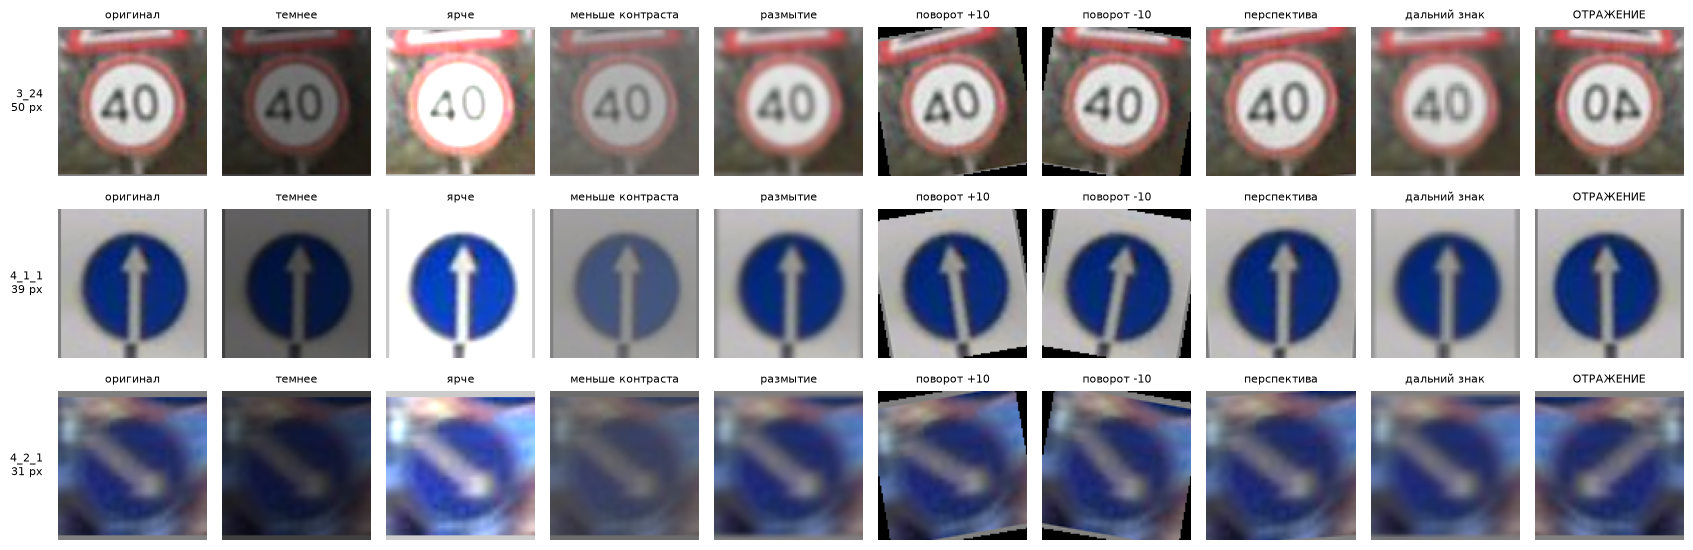

Классы в этом датасете, для которых отражение может изменить смысл (гипотеза): 21 из 155


split,train,val
class_name,,
5_15_2,4504,440
3_24,3761,343
4_1_1,2137,196
5_15_3,1448,144
5_15_1,1362,131
5_15_2_2,1274,116
4_2_3,1114,76
5_15_5,1100,108
4_2_1,1071,120


In [52]:
def augmentation_variants(img):
    """Варианты одной вырезки (квадрат 96x96). Каждый вариант - копия, оригинал не меняется."""
    w, h = img.size
    return {
        "оригинал": img,
        "темнее": ImageEnhance.Brightness(img).enhance(0.5),
        "ярче": ImageEnhance.Brightness(img).enhance(1.6),
        "меньше контраста": ImageEnhance.Contrast(img).enhance(0.5),
        "размытие": img.filter(ImageFilter.GaussianBlur(1.5)),
        "поворот +10": img.rotate(10, resample=Image.Resampling.BICUBIC),
        "поворот -10": img.rotate(-10, resample=Image.Resampling.BICUBIC),
        "перспектива": img.transform(img.size, Image.Transform.QUAD, (6, 0, 0, h - 6, w, h, w - 6, 6), Image.Resampling.BICUBIC),
        "дальний знак": img.resize((w // 3, h // 3), Image.Resampling.BILINEAR).resize((w, h), Image.Resampling.BILINEAR),
        "ОТРАЖЕНИЕ": img.transpose(Image.Transpose.FLIP_LEFT_RIGHT),
    }


def pick_aug_classes(max_n=3):
    """Классы для показа: цифры (3_24), стрелки (4_1), частый знак (2_1); иначе самые частые."""
    pool = ann[(ann.split == reference) & (ann.side >= AUG_MIN_SIDE)]
    present = list(pool.class_name.value_counts().index)
    picked = []
    for prefix in ("3_24", "4_1", "4_2", "2_1", "1_"):
        match = [c for c in present if str(c).startswith(prefix) and c not in picked]
        if match:
            picked.append(match[0])
    picked += [c for c in present if c not in picked]
    if not picked:                                    # крупных знаков нет: берутся самые частые классы
        picked = list(counts.index[counts[reference] > 0])
    return picked[:max_n]


aug_classes = list(AUG_CLASSES) or pick_aug_classes()
if HAVE_IMAGES and aug_classes:
    fig, axes = plt.subplots(len(aug_classes), 10, figsize=(17, 1.9 * len(aug_classes)), squeeze=False)
    for row_axes, class_name in zip(axes, aug_classes):
        pool = ann[(ann.split == reference) & (ann.class_name == class_name) & (ann.side >= AUG_MIN_SIDE)]
        if pool.empty:                                # нет крупных примеров: берутся самые крупные из имеющихся
            pool = ann[(ann.split == reference) & (ann.class_name == class_name)].sort_values("side", ascending=False).head(5)
        for ax in row_axes:
            ax.axis("off")
        if pool.empty:
            continue
        base = None
        for _, obj in pool.sample(min(5, len(pool)), random_state=SEED).iterrows():
            try:
                crop = get_crop(obj, pad=0.15)
                base = ImageOps.pad(crop, (96, 96), method=Image.Resampling.BILINEAR, color=(128, 128, 128))
                break
            except Exception as error:
                print("Пример для аугментации не прочитан:", obj.image_key, type(error).__name__)
        if base is None:
            row_axes[0].set_title(f"{class_name}: нет читаемого примера", fontsize=8)
            continue
        for ax, (name, variant) in zip(row_axes, augmentation_variants(base).items()):
            ax.imshow(variant); ax.set_title(name, fontsize=8)
        row_axes[0].text(-0.1, 0.5, f"{class_name}\n{obj.side:.0f} px", transform=row_axes[0].transAxes, ha="right", va="center", fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("Нужны картинки и классы: показ аугментаций пропущен.")

FLIP_RISK_PREFIXES = ("1_11", "1_34", "3_24", "3_25", "4_1", "4_2", "5_15")   # гипотеза, проверить по ПДД
risky = counts[[str(c).startswith(FLIP_RISK_PREFIXES) for c in counts.index]]
print("Классы в этом датасете, для которых отражение может изменить смысл (гипотеза):", len(risky), "из", len(counts))
display(risky.head(15))

### Вывод по разделу 13

| Преобразование | Подходит? | Почему (по нашим примерам) |
|---|---|---|
| яркость и контраст | да, для `StarLine` особенно | тёмных вырезок (яркость ниже 60) в `RTSD` 4,7%, в `cleaned` 4,2%, в `StarLine` 15,6%. Если сильно затемнить, знак почти не разглядеть, а если сильно осветлить, на `3_24` смывается число, поэтому силу изменения лучше ограничить |
| небольшой поворот | да, с оговоркой | знаки на кадрах бывают наклонены, но при повороте на 10 градусов появляются чёрные углы, и их лучше заполнять иначе |
| перспектива | пока неясно | при текущих параметрах изменение почти не видно, нужны более сильные значения (проверить) |
| лёгкое размытие | да | мелкие знаки в данных и так размыты, а резкость сильно зависит от размера (связь 0,6 во всех трёх датасетах) |
| уменьшение и увеличение (дальний знак) | да | так можно изобразить мелкий дальний знак, по виду это близко к размытию |
| горизонтальное отражение | не как общее правило | цифры на `3_24` зеркалятся (число 40 превращается в зеркальные цифры), а диагональная стрелка `4_2_1` меняет направление. Безопасно, вероятно, только для симметричных знаков (`2_1`, `4_1_1`: на галерее `4_1_1` почти не меняется). В списке риска `RTSD` 21 класс из 155, `cleaned` 33 из 198, `StarLine` 30 из 57 (в основном классы скорости с цифрами, это гипотеза, её нужно проверить по ПДД) |

> Аугментации мы применяем только после разделения данных и только к обучающей части. Параметры мы выбирали по просмотру нескольких классов, а не по измеренному эффекту для модели.
>
> В `cleaned` классов в списке риска больше, потому что скорость там разбита на классы по числу (`3_24_n40` и другие). В `StarLine` риск высок из-за 21 класса скорости (`3_24_sXX`, `3_25_sXX`).


## 14. Простая модель

**Бейзлайн (baseline)** - первое простое решение, с которым потом сравниваются улучшения. По описанию чекпоинта достаточно модели попроще, поэтому нейросети здесь нет:

1. вырезка переводится в серую, уменьшается до 16x16 и раскладывается в 256 чисел;
2. "наивная модель" (`DummyClassifier`) всегда отвечает самым частым классом - нижняя планка;
3. логистическая регрессия (`LogisticRegression`) - простейший обучаемый классификатор. Несмотря на название, она выбирает **категорию**, а не число.

**Accuracy** - доля верных ответов, **macro-F1** - среднее качество по классам, где редкие классы весят столько же, сколько частые. Таблица путаницы показывает, какие классы путаются.

Числа - ориентир на небольшой выборке нескольких классов, а не итоговое качество проекта. Связанные кадры могут завышать оценку. Групповое деление в этом разделе предварительное, пока смысл групп не подтверждён - его тоже нужно проверить по сценам. Включается параметром `RUN_BASELINE = True`. Работает на CPU, время зависит от данных.

Настройки группового опыта:
- `BASELINE_GROUP_SOURCE = "auto"` пробует `group_id`, затем временные последовательности. `None` оставляет только валидацию `val`.
- Пока `GROUPING_CONFIRMED = False`, результат помечен как предварительный, смысл групп не подтверждён, и значения нельзя считать проверенным качеством.
- Строки без группы исключаются с подсчётом, а не объединяются в одну группу.
- `test` и `reduced` для подбора не используются, даже если их подробный EDA разрешён.

Классы выбираются только по обучающей части. Macro-F1 считается по зафиксированному списку этих классов. Отсутствующие в проверке отмечаются и получают ноль при выбранном правиле `zero_division=0`. Это условность расчёта, а не измеренное качество отсутствующего класса.

Переход в серый цвет и размер 16x16 - намеренно простое ограниченное решение, теряющее цвет и мелкие детали, а не рекомендуемая окончательная подготовка. Пропорции сохраняются.

In [53]:
baseline_table, last = None, None
baseline_errors = pd.DataFrame(columns=["image_key", "error"])
if not RUN_BASELINE:
    print("Простая модель выключена: RUN_BASELINE = False.")
elif not HAVE_IMAGES:
    print("Для модели нужны изображения; раздел пропущен.")
else:
    from sklearn.dummy import DummyClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import accuracy_score, f1_score
    from sklearn.model_selection import GroupShuffleSplit

    classes = [c for c in counts.index[counts[reference] >= BASELINE_MIN_TRAIN] if c not in BASELINE_EXCLUDE][:BASELINE_N_CLASSES]
    eval_split = BASELINE_EVAL_SPLIT if BASELINE_EVAL_SPLIT in active_splits else None
    if eval_split in (reference, "test", "reduced"):
        eval_split = None
    parts = [reference] + ([eval_split] if eval_split else [])
    pool = ann[ann.class_name.isin(classes) & ann.split.isin(parts)]
    if HAS_BOXES:
        pool = pool[(pool.w >= BASELINE_MIN_SIDE) & (pool.h >= BASELINE_MIN_SIDE)]
    sample = sample_per_group(pool, ["split", "class_name"], BASELINE_PER_CLASS)
    features, kept, errors = [], [], []
    for idx, row in sample.iterrows():
        try:
            crop = get_crop(row, pad=0.15)
            if min(crop.size) < BASELINE_MIN_SIDE:
                continue
            gray = ImageOps.pad(crop.convert("L"), (16, 16), method=Image.Resampling.BILINEAR, color=128)
            features.append(np.asarray(gray, dtype=float).ravel() / 255.0)
            kept.append(idx)
        except Exception as error:
            errors.append({"image_key": row.image_key, "error": f"{type(error).__name__}: {error}"})
    sample = sample.loc[kept].reset_index(drop=True)
    baseline_errors = pd.DataFrame(errors, columns=["image_key", "error"])
    X = np.asarray(features, dtype=float).reshape(-1, 256)
    y = sample.class_name.to_numpy()
    ref_indices = np.flatnonzero(sample.split.to_numpy() == reference)
    print("Классы выбраны по обучающей части:", classes)
    print(f"Случайное угадывание при {len(classes)} классах дало бы accuracy около {1 / max(len(classes), 1):.3f} (выборка сбалансирована по классам)")
    print("Прочитано вырезок:", len(sample), "; ошибок чтения:", len(baseline_errors))

    scenarios = []
    if eval_split:
        eval_indices = np.flatnonzero(sample.split.to_numpy() == eval_split)
        scenarios.append((f"Исходное разделение: {reference} -> {eval_split}", ref_indices, eval_indices))
    if BASELINE_GROUP_SOURCE is not None:
        group_columns = {"group_id": sample.group_id, "time": sample.image_key.map(seq_map)}
        order = ["group_id", "time"] if BASELINE_GROUP_SOURCE == "auto" else [BASELINE_GROUP_SOURCE]
        for source_name in order:
            groups = group_columns.get(source_name)
            if groups is None:
                continue
            eligible = ref_indices[groups.iloc[ref_indices].notna().to_numpy()]
            if len(eligible) and groups.iloc[eligible].nunique() >= 4:
                print(f"Группы для деления: {source_name}; строки без группы исключены: {len(ref_indices) - len(eligible)}")
                splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
                tr, va = next(splitter.split(X[eligible], y[eligible], groups.iloc[eligible].astype(str)))
                print("Различных групп в обучении / в проверке:", groups.iloc[eligible[tr]].nunique(), "/", groups.iloc[eligible[va]].nunique())
                label = "Деление по подтверждённым группам" if GROUPING_CONFIRMED else "ПРЕДВАРИТЕЛЬНОЕ деление по группам (смысл групп не подтверждён)"
                scenarios.append((f"{label}: {source_name}", eligible[tr], eligible[va]))
                break
        else:
            print("Подходящих групп для отдельного деления нет (нужно минимум четыре).")
    results = []
    for scenario, tr, va in scenarios:
        if len(tr) == 0 or len(va) == 0 or len(set(y[tr])) < 2:
            print(scenario, "- пропуск: нужны две обучаемые категории и непустая проверочная часть.")
            continue
        for model_name, model in [("Самый частый класс", DummyClassifier(strategy="most_frequent")),
                                  ("Логистическая регрессия", LogisticRegression(max_iter=500))]:
            model.fit(X[tr], y[tr])
            prediction = model.predict(X[va])
            results.append({"сценарий": scenario, "модель": model_name, "обучающих": len(tr), "проверочных": len(va),
                            "accuracy": accuracy_score(y[va], prediction),
                            "macro-F1": f1_score(y[va], prediction, labels=classes, average="macro", zero_division=0),
                            "macro-F1 (только классы из проверки)": f1_score(y[va], prediction, labels=sorted(set(y[va])), average="macro", zero_division=0),
                            "классов без примеров в проверке": len(set(classes) - set(y[va])),
                            "что отвечает (для самого частого класса)": ", ".join(sorted(set(prediction))[:3]) if model_name == "Самый частый класс" else ""})
            if model_name == "Логистическая регрессия":
                last = (scenario, y[va], prediction, sample.iloc[va])
    if results:
        baseline_table = pd.DataFrame(results)
        display(baseline_table.round(4))
    else:
        print("Метрики не вычислялись. Нужны подходящая валидация или проверенные группы; случайное деление кропов автоматически не создаётся.")

Классы выбраны по обучающей части: ['5_19_1', '2_1', '5_16', '5_15_2', '3_24', '2_4', '3_27', '1_23', '4_1_1', '5_20', '3_20', '5_15_3', '5_15_1', '5_15_2_2', '1_17']
Случайное угадывание при 15 классах дало бы accuracy около 0.067 (выборка сбалансирована по классам)
Прочитано вырезок: 4390 ; ошибок чтения: 0
Группы для деления: time; строки без группы исключены: 0
Различных групп в обучении / в проверке: 769 / 257


,сценарий,модель,обучающих,проверочных,accuracy,macro-F1,macro-F1 (только классы из проверки),классов без примеров в проверке,что отвечает (для самого частого класса)
0,Исходное разделение: train -> val,Самый частый класс,2250,2140,0.0500,0.0063,0.0063,0,1_17
1,Исходное разделение: train -> val,Логистическая регрессия,2250,2140,0.8131,0.8149,0.8149,0,
2,ПРЕДВАРИТЕЛЬНОЕ деление по группам (смысл групп не подтверждён): time,Самый частый класс,1696,554,0.0415,0.0053,0.0053,0,5_20
3,ПРЕДВАРИТЕЛЬНОЕ деление по группам (смысл групп не подтверждён): time,Логистическая регрессия,1696,554,0.7834,0.7848,0.7848,0,


Разбор ошибок для сценария: ПРЕДВАРИТЕЛЬНОЕ деление по группам (смысл групп не подтверждён): time


,доля верных,проверочных
1_17,0.59,37
2_1,0.71,41
1_23,0.74,38
5_15_2_2,0.74,38
3_24,0.76,42
2_4,0.77,43
3_27,0.77,39
3_20,0.77,35
5_15_3,0.80,25
5_19_1,0.81,37


Самые частые путаницы:


,на самом деле,модель ответила,раз
4,1_17,5_20,6
2,1_17,3_27,5
17,2_4,2_1,5
53,5_15_2_2,5_19_1,5
35,3_27,2_1,4
6,1_23,2_1,4
57,5_16,1_17,4
11,2_1,3_24,4
48,5_15_2,5_15_3,3
40,4_1_1,3_27,3


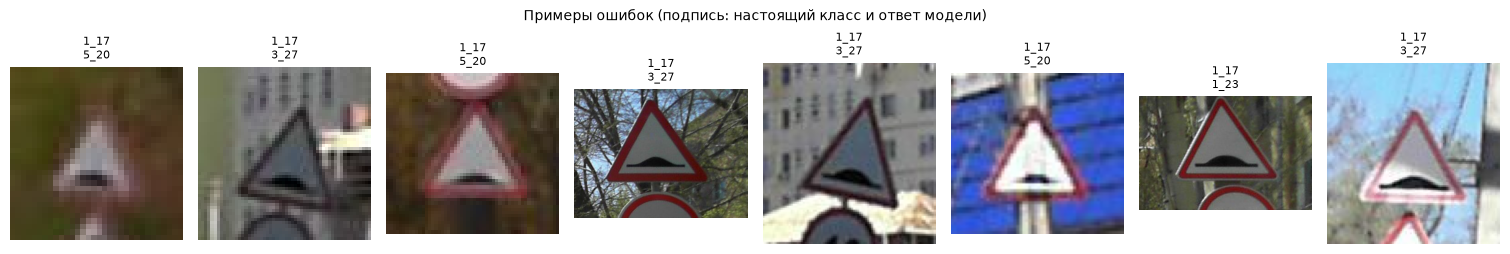

In [54]:
if last is not None:
    name, y_true, y_pred, meta_te = last
    print("Разбор ошибок для сценария:", name)
    recall = pd.Series(y_true == y_pred).groupby(y_true).mean().rename("доля верных")
    support = pd.Series(y_true).value_counts().rename("проверочных")
    display(pd.concat([recall, support], axis=1).sort_values("доля верных").round(2))

    confusion = pd.crosstab(pd.Series(y_true, name="на самом деле"), pd.Series(y_pred, name="модель ответила"))
    pairs = [(a, b, int(confusion.loc[a, b])) for a in confusion.index for b in confusion.columns if a != b and confusion.loc[a, b] > 0]
    pairs = pd.DataFrame(pairs, columns=["на самом деле", "модель ответила", "раз"]).sort_values("раз", ascending=False)
    print("Самые частые путаницы:")
    display(pairs.head(10))

    wrong = meta_te[y_true != y_pred].copy()
    wrong["ответ модели"] = y_pred[y_true != y_pred]
    gallery(wrong, "Примеры ошибок (подпись: настоящий класс и ответ модели)", caption_cols=("class_name", "ответ модели"))
else:
    print("Разбор ошибок недоступен: модель не выполнялась.")

### Вывод по разделу 14

> **RTSD: "watchman/rtsd-dataset":**
> 
> Мы обучили самую простую модель: логистическую регрессию на серых вырезках 16x16 по 15 самым частым классам (до 150 вырезок на класс и часть). При исходном разделении `train` -> `val` (2 250 и 2 140 вырезок) получилось accuracy 0,813 и macro-F1 0,815. При предварительном делении `train` по временным последовательностям (769 и 257 групп, 1 696 и 554 вырезки) получилось 0,783 и 0,785. Для сравнения: модель "всегда отвечать самым частым классом" даёт около 0,05 и 0,006, а случайное угадывание при 15 классах - около 0,067. То есть даже такая простая модель решает задачу значительно лучше угадывания.
> 
> Хуже всего распознаются `1_17` (0,59), `2_1` (0,71), `1_23` (0,74) и `5_15_2_2` (0,74). Частые путаницы: `1_17` с `5_20` и `3_27`, `2_4` с `2_1`, `5_15_2_2` с `5_19_1`. Часть путаниц между знаками разной формы и цвета, вероятно, возникла из-за того, что при переходе к серым 16x16 теряются цвет и детали.
> 
> Разница между двумя схемами деления (около 3 пунктов) сопоставима с погрешностью оценки на 554 примерах (около 1,7 пункта). Поэтому влияние утечки на эту модель мы не подтвердили, но и не опровергли- для более сложных моделей оно может быть важнее. Выборка ограничена 150 вырезками на класс, поэтому абсолютные числа нельзя сравнивать с результатами на полном распределении.
> 
> Дальше можно повторить эксперимент с другими значениями `SEED`, чтобы оценить разброс, сравнить с моделью, которая использует цвет и больший размер входа, и выбрать метрики для следующего чекпоинта.

> **RTSD cleaned: "eleldar/rtsd_cleaned":**
> 
> Здесь та же простая модель на 15 самых частых классах (вместо `3_24` в списке `3_24_n40`, остальные 14 классов совпадают с `RTSD`). Деление идёт по `sign_id`: 1 344 группы в обучении и 448 в проверке, 1 707 и 543 вырезки. Получилось accuracy 0,812 и macro-F1 0,809. Модель "всегда самый частый класс" (она ответила `5_15_2_2`) дала 0,052 и 0,007, случайное угадывание - около 0,067.
> 
> Лучше всего распознаются `5_15_1` (0,95), `3_20` (0,92) и `5_15_3` (0,91), хуже всего `2_4` (0,59), `1_23` (0,69), `5_20` (0,72) и `1_17` (0,76). Частые путаницы: `2_1` с `3_27` (5 раз) и в обратную сторону (4), `1_17` с `5_20` (4). Скорость `3_24_n40` распознана в 88% случаев.
> 
> Результат почти такой же, как у `RTSD` при делении по последовательностям (0,81 и 0,78), но сравнивать их напрямую нельзя. Группы устроены по-разному (знаки против временных блоков), список классов отличается одним классом, а погрешность на 543 примерах около 1,7 пункта. Деление по `sign_id` убирает самую очевидную утечку (вырезки одного знака), но не гарантирует независимость по сценам.
> 
> Дальше мы считаем результат предварительным, повторяем с другими `SEED` и позже сравниваем с `RTSD` при одинаковой схеме деления.

> **StarLine: "StarLineResearch/Russian_Road_Signs_Dataset":**
> 
> Та же простая модель на 15 самых частых классах, но среди них есть `unknown_sign` и `table`, которые не являются знаками по шаблону ПДД. Деление по временным последовательностям: 52 группы в обучении и 18 в проверке, 1 735 и 515 вырезок. Получилось accuracy 0,466 и macro-F1 0,451. Модель "всегда самый частый класс" (она ответила `3_24`) дала 0,021 и 0,003. В предыдущем запуске с делением по `group_id` вышло 0,588 и 0,474 (337 проверочных вырезок, 2 класса без примеров).
> 
> Результат заметно хуже, чем у `RTSD` и `cleaned`. Лучше всего распознаются `1_20_2` (0,79), `3_25` (0,74), `1_25` и `8_22_1` (по 0,67). Хуже всего - классы скорости: `3_24_s110`, `3_24_s60`, `3_24_s70` (по 0,20), `3_24_s90` (0,23), `3_24` (0,27), а ещё `1_20_3` (0,28). Частые путаницы: `3_24_s90` с общим `3_24` (20 раз), `3_24_s110` с `3_25` (19), `8_22_1` с `8_22_2` (17), `3_31` с `3_25` (13).
> 
> Скорее всего, простая модель по серым 16x16 плохо различает числа на знаках скорости. К тому же общий класс `3_24` содержит знаки с теми же числами, что и `3_24_sXX` (разделы 8 и 9), так что часть путаниц заложена самой разметкой. Возможно, добавляются тёмные кадры и малое число групп (52 и 18). При переходе от `group_id` к времени результат изменился на 12 пунктов, поэтому такой оценке нельзя доверять.
> 
> Дальше мы можем повторить эксперимент после удаления копий, запустить его второй раз без `unknown_sign`, `table` и `scoreboard*` (`BASELINE_EXCLUDE`) и сравнить. Выводов о качестве по такому делению не делаем, пока не выяснен смысл групп, а для скорости можно попробовать модель с цветом и большим входом.


## 15. Итоги

### 15.1. Ключевые факты одним списком

Ячейка собирает числа для текстов выводов и сравнения датасетов. Она ничего не оценивает, решение будем принимать сами.

In [55]:
size_ref = known[known.split == reference].side
facts = {
    "датасет": DATASETS[KIND]["name"],
    "что считается изображением": "вырезка" if KIND == "cleaned" else "кадр",
    "изображений (кадров или вырезок) всего": len(images),
    "объектов всего": len(objects),
    "изображений в подробном EDA": len(active_images),
    "классов в подробном EDA": int(active_objects.class_name.nunique()),
    "исходные рамки на полных кадрах": HAS_BOXES,
    "картинки доступны": HAVE_IMAGES,
    "картинок проверено на чтение / открылось": f"{len(read_check)} / {int(read_check.ok.sum()) if len(read_check) else 0}",
    "размер известен у объектов (опорная часть)": f"{len(size_ref)} из {int((ann.split == reference).sum())}",
    "доля объектов со стороной < 16 px (опорная часть)": round(float((size_ref < 16).mean()), 3) if len(size_ref) else None,
    "доля объектов со стороной < 32 px (опорная часть)": round(float((size_ref < 32).mean()), 3) if len(size_ref) else None,
    "доля топ-10 классов (опорная часть)": round(float(cumulative.iloc[9]), 3) if len(cumulative) >= 10 else None,
    "классов без примеров (опорная часть)": int((counts[reference] == 0).sum()),
    "классов-кандидатов по порогам": len(candidates),
    "независимость проверки доказана": "нет: нужно обсуждение и дополнительные проверки",
}
facts.update(leak_facts)
decision_facts = pd.Series(facts, name="значение").astype(str).to_frame()
display(decision_facts)

,значение
датасет,watchman/rtsd-dataset
что считается изображением,кадр
изображений (кадров или вырезок) всего,59188
объектов всего,104358
изображений в подробном EDA,59188
классов в подробном EDA,155
исходные рамки на полных кадрах,True
картинки доступны,True
картинок проверено на чтение / открылось,600 / 600
размер известен у объектов (опорная часть),95492 из 95492


### 15.2. Итоговые выводы

В каждом пункте мы отделяем то, что проверили полностью, то, что проверили выборочно, и то, что не проверили. Основной датасет проекта - `RTSD` (`watchman/rtsd-dataset`), а `RTSD cleaned` и `StarLine` мы можем использовать как дополнительные.

1. **Данные и разметка.** Мы разобрали три датасета. `RTSD` (версия 3): 59 188 кадров (train 54 188, val 5 000), 104 358 рамок, 155 классов в train и 139 в val. На кадре в среднем 1,76 знака (максимум 11), 81% кадров 1280x720 и 19% - 1920x1080. Технических ошибок разметки нет: повторов, пустых классов, неверных рамок и рамок за кадром 0. `RTSD cleaned`: 104 358 готовых вырезок и 198 классов в одной части. Это те же объекты, что в `RTSD` `train` и `val` вместе (сверка по классам дала полное совпадение), только скорость разбита по числу. `StarLine`: 6 440 кадров 2880x1860 (train 5 031, test 1 409), 54 281 рамка, 57 классов в train и 34 в test, в среднем 7,9 рамки на кадре (максимум 42, с учётом лишних копий). Подробно мы изучили только `train`, `test` закрыт. Структуру разметки проверили полностью, а чтение картинок - выборочно (`RTSD` 600 из 59 188, `cleaned` 300 из 104 358, `StarLine` 300 из 6 440, везде все открылись). Качество вырезок оценено по выборкам (2 400, 1 200 и 1 200), качество кадров целиком - по выборкам по 1 000 кадров `RTSD` и `StarLine`.
2. **Баланс классов.** Во всех датасетах сильный дисбаланс. `RTSD`: топ-10 классов дают 61,5% объектов, топ-50 - 91,8%. Самый частый `5_19_1` - 22 147 в train (23,2%), самый редкий встречается один раз. 16 классов в val нет, ещё у 44 там от 1 до 5 примеров, а пороги 200 (train) и 20 (val) проходят 53 класса. Доли классов в train и val почти совпадают (ни у одного класса с не менее чем 5 объектами в val отличие не больше чем в 3 раза). `Cleaned`: топ-10 дают 59,7%, у 36 классов меньше 10 вырезок, а независимых знаков (`sign_id`) 15 628, то есть в 6,7 раза меньше, чем вырезок. Классов с не менее чем 100 разными знаками 31. `StarLine`: топ-10 дают 77,8%, а 37% объектов - классы не по шаблону ПДД (`unknown_sign`, `table`, `scoreboard`, `scoreboard_sign`). **Решение:** первый эксперимент делаем на ограниченном числе классов из 53 кандидатов `RTSD` (точный список обсуждается), редкие классы оцениваем отдельно, а для `cleaned` отбираем классы по числу различных знаков.
3. **Качество и размер знаков.** В `RTSD` все рамки не меньше 16 пикселей (это граница датасета), медиана условной стороны около 31,5. Если уменьшить длинную сторону кадра до 640 пикселей, мельче 16 пикселей станут 58,5% знаков (по ширине 56%), при входе 960 - 22,3%, при входе 1280 - 3,8%. На кадрах Full HD знаки мельче (медиана условной стороны при входе 640: 12,7 пикселя против 14,9 на кадрах 1280x720). В `cleaned` по выборке 5 000 вырезок картина такая же (медиана 31,9, 50,7% вырезок 16-32 пикселя). В `StarLine` в исходном кадре знаки крупнее (медиана 45,4), но кадр огромный (2880x1860), и после уменьшения мельче 16 пикселей становятся 71,8% знаков при входе 640, 52,5% при 960 и 39,7% при 1280. То есть мельче, чем в `RTSD` при том же входе. Тёмных вырезок в `RTSD` 4,7%, в `cleaned` 4,2%, в `StarLine` 15,6%. В `RTSD` ночных и вечерних кадров нет: съёмка идёт с 6 до 17 часов, основная масса с 8 до 15 часов, в 16 и 17 часов вместе не более 0,5%. Тёмных кадров по выборке около 1%, по-видимому, утренних (самая низкая яркость в 6-7 часов). В `StarLine` кадры есть вплоть до 20 часов (в 20 часов средняя яркость кадра 22), тёмных кадров по выборке 3,3%. **Решение:** для детекции сравниваем входные размеры (для `StarLine` ещё и нарезку кадра), для классификации берём вырезки в исходном разрешении.
4. **Выбросы и ошибки.** В `RTSD` вытянутые рамки (около 2,3%) в основном принадлежат классам неквадратной формы (`6_16`, `6_15_1`, `5_7_x`). Мы посмотрели крайние случаи (самые маленькие, вытянутые и большие рамки) и ошибок разметки не нашли: вытянутые рамки - это широкие знаки (`6_16`, `5_7_1`) и `5_19_1`, снятые под углом. По группам знаков вытянуты информационные знаки (33% рамок вне диапазона 0,5-2) и таблички (26%), остальные группы почти квадратные. Пар рамок с IoU больше 0,7 нет (проверили 26 706 кадров с несколькими рамками). Файл `reduced` не годится для обучения детектора: разметка его кадров неполная (не хватает 2 645 рамок), а по составу он сильно отличается от `train` (особых предписаний 14,8% против 43,1%). В `StarLine` 11 870 лишних копий рамок (29,9% строк, 38% кадров). У копий совпадают служебные поля `timestamp_ns` и `bbox_msg_id`, так что это, вероятно, дубли при выгрузке (не доказано). Проверка IoU нашла 18 353 пары рамок с IoU больше 0,7, из них 3 859 с разными классами, и в показанных парах один знак записан общим классом и классом с числом (`3_25` и `3_25_s60`). Кроме того, `unknown_sign` содержит обычные знаки известных классов, а общий `3_24` содержит знаки с разными числами и перекрывается с `3_24_sXX`. В `cleaned` рамок нет, поэтому проверка невозможна; на галереях видны размытые вырезки и одна вырезка `5_16` без видимого знака. Ничего из этого мы не удаляем автоматически.
5. **Независимость проверки.** В `RTSD` у 99,8% кадров val есть кадр из train ближе 5 секунд, все 12 дней съёмки общие, 66% последовательностей содержат кадры обеих частей, а в train и val нашли 2 пары побайтово одинаковых кадров (проверили 15 000 кадров). Файлов с одинаковым именем в train и val нет, поэтому одинаковые кадры находит только побайтовое сравнение. Значит, официальный `val` не независим. В `cleaned` частей и времени нет. `sign_id` подтверждён, и деление по нему убирает утечку между вырезками одного знака, но независимость по сценам не доказана. В `StarLine` `test` отделён по времени (нет кадров train ближе 30 секунд, ни одна из 115 последовательностей не смешивает части), но у 17,7% кадров `test` есть кадр train в пределах пяти минут, а `group_id` как группа не годится. **Решение:** для `RTSD` делим по временным последовательностям. Официальное деление по дням невозможно, так как все 12 дней есть в обеих частях, но для честной оценки можно заново выделить test из целых дней. Результаты на официальном `val` считаем ориентировочными.
6. **Аугментации.** Подходят яркость и контраст (особенно для `StarLine`, сильное осветление почти смывает число на `3_24`, поэтому силу изменения лучше ограничить), небольшой поворот (появляются чёрные углы), размытие и имитация дальнего знака. Отражение подходит не для всех классов (цифры, несимметричные стрелки): в списке риска `RTSD` 21 класс из 155, `cleaned` 33 из 198, `StarLine` 30 из 57. Аугментации применяем после деления данных и только к обучающей части.
7. **Простая модель.** Логистическая регрессия на серых вырезках 16x16 по 15 самым частым классам. `RTSD`: accuracy 0,81 и macro-F1 0,81 при исходном разделении и 0,78 и 0,78 при делении по последовательностям (разница сопоставима с погрешностью около 1,7 пункта на 554 примерах). `Cleaned`: 0,81 и 0,81 при делении по `sign_id`. `StarLine`: 0,47 и 0,45 при делении по времени (в прошлом запуске по `group_id` 0,59 и 0,47), хуже всего классы скорости. Наивная модель (самый частый класс) даёт 0,02-0,05, случайное угадывание - около 0,067. Выборка сбалансирована (не более 150 вырезок на класс), поэтому эти числа нельзя сравнивать с результатами на полном распределении и между датасетами (классы и схемы деления разные).
8. **Что не удалось проверить.** Работу в темноте на `RTSD`. Различение конкретной скорости на `3_24` в `RTSD` (в метках один общий класс). Полноту разметки на всех кадрах (мы просмотрели лишь некоторые; подозрительный случай на `train:52038` оказался знаками, повёрнутыми обратной стороной, то есть не ошибкой). Точные копии по всему `train` `RTSD` и между `train` и `test` `StarLine`. Независимость по сценам и дням в `cleaned`. Число кадров в каждом дне съёмки `RTSD` (оно нужно, чтобы выделить test из целых дней). Часть `test` `StarLine`. Год и местное время кадров `StarLine` (по первым строкам `test` - 2023 год). Долю пар "общий класс и класс с числом" среди конфликтов меток `StarLine`. Смысл `group_id`, `table` и классов-вариантов (`3_4_1`, `4_1_2_x`). Число классов `StarLine` (заявлено 61, в train 57, в test 34).
9. **Что делаем дальше.** К следующему чекпоинту: согласовать метрики (accuracy, macro-F1), выбрать список классов и схему разбиения по последовательностям или по дням, получить результат простой модели на `RTSD` и сравнить схемы проверки. Для детекции сравнить входные размеры 640, 960 и 1280, для редких классов использовать оверсэмплинг или аугментации. Решить, что делать с копиями рамок, парами "общий класс и класс с числом" и классами `unknown_sign`, `table` в `StarLine`, если он будет использоваться.




### 15.3. Выбор датасета: таблица

Заполнена по результатам запусков на разных датасетах.

| Вопрос | RTSD: watchman/rtsd-dataset | RTSD cleaned: eleldar/rtsd_cleaned | StarLine: StarLineResearch/Russian_Road_Signs_Dataset |
|---|---|---|---|
| Читается ли датасет без ошибок | да; JSON и кадры читаются, 600 из 600 проверенных кадров открылись; данные взяты из локального кэша, возможность скачать заново без учётной записи Kaggle не проверена | да; 104 358 вырезок, 300 из 300 проверенных открылись | да; архив около 7 ГБ распакован, 300 из 300 проверенных кадров train открылись; `test` не изучался |
| Подходит ли под задачу (классификация, детекция) | и то и другое: кадры, рамки, вырезки создаются по рамкам | только классификация вырезок | и то и другое, но 37% рамок - не знаки по шаблону ПДД, а часть рамок продублирована |
| Есть ли исходные рамки на полных кадрах | да | нет | да |
| Понятна ли система классов | да: 155 классов с кодами ПДД; общий класс `3_24`; варианты вроде `5_15_2_2` и `3_4_1` объяснены только по соседним кодам | в основном да: 198 классов (скорость по числу); смысл вариантов не подтверждён | частично: 57 классов, 4 из них не по шаблону (`unknown_sign`, `table`, `scoreboard*`); `3_24` без числа перекрывается с `3_24_sXX` (один знак бывает записан двумя классами); число классов 61 не подтверждено |
| Как записаны ограничения скорости | одним классом `3_24` (3 761 в train, 343 в val); `3_25` редкий | по числу: 9 классов `3_24_nXX` (самый частый `3_24_n40`, 2 197) и 5 классов `3_25_nXX` | 21 класс `3_24_sXX`, `3_25_sXX` и `white`, и общий `3_24` (2 329); вместе 10 595 рамок |
| Достаточно ли разных знаков и сцен | 12 дней съёмки, 2 868 последовательностей, в среднем 1,76 знака на кадре (до 11); но 15 классов имеют менее 10 примеров | 15 628 разных знаков, но 6,7 вырезки на знак; 31 класс имеет не менее 100 знаков | 115 последовательностей (6 440 кадров с интервалом около 0,1 секунды), 16 дней съёмки в train, 57 классов, в среднем 7,9 рамки на кадре (до 42); много зон дорожных работ; сцен мало |
| Доля мелких знаков (меньше 16 px) | 0% в исходном кадре (граница датасета); 51% меньше 32 px; после уменьшения до 640 px 58,5% меньше 16, при 1280 - 3,8% | 0% (граница датасета), по выборке 5 000 вырезок 50,7% меньше 32 px; уменьшение кадра не оценивалось | 2,2% меньше 16 px, 33% меньше 32 px; после уменьшения до 640 px 71,8% меньше 16, при 1280 - 39,7% |
| Можно ли отделить связанные наблюдения (раздел 11) | только по времени (последовательности) или по целым дням (если заново выделить test); идентификаторов объектов нет; официальный `val` не независим | да, по `sign_id` (15 628 знаков); независимость по сценам не доказана | `test` отделён по времени, `train` можно делить по последовательностям; `group_id` не годится |
| Сохраняется ли происхождение вырезок | да: кадр, рамка, класс | нет кадров; по счётам совпадает с `RTSD` train + val | да: кадр, рамка, `timestamp_ns`, `bbox_msg_id` |
| Посильность (объём, время, диск) | около 18 ГБ с кадрами; вырезки и простая модель на CPU посильны, детектор лучше на Colab или Kaggle | самый лёгкий вариант (мелкие вырезки), размер на диске не фиксировался | около 7 ГБ архив, кадры 2880x1860: на CPU тяжело, нужна выборка или нарезка кадров, обучение лучше на Colab |
| Условия использования (по странице) | на странице Kaggle лицензия указана как Unknown; публикацию изображений оценивать отдельно (лица, номера) | в карточке не найдена (проверить) | в карточке не найдена (проверить); публикацию изображений оценивать отдельно |
| **Решение и причина** | **основной датасет для использования**: есть кадры и рамки (подходит и для классификации, и для детекции), официальное деление, понятные классы ПДД; ограничения: val не независим, нет ночных кадров, один общий класс скорости | **вспомогательный** для классификации вырезок с делением по `sign_id`; не считать независимым подтверждением `RTSD` (это те же объекты) | **дополнительный** для проверки на другом домене (другие камеры, мелкие знаки после сжатия, тёмные и ночные кадры) после решения по копиям рамок, парам «общий класс и класс с числом» и классам `unknown_sign`, `table`; прямое сравнение метрик с `RTSD` нельзя без таблицы соответствия классов |



### 15.4. Практическая применимость

Оформляется отдельным PDF и в `EDA.ipynb` не входит.

## 16. Сохранение результатов и сравнение запусков

Таблицы сохраняются в **новую** папку с временной меткой, поэтому предыдущий запуск не перезаписывается. Картинки не копируются. В `manifest.json` записаны датасет, настройки и версии библиотек.

In [56]:
run_dir = RESULTS_ROOT / f"{KIND}_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
run_dir.mkdir(parents=True, exist_ok=False)
overview.to_csv(run_dir / "overview.csv")
(run_dir / "passport.json").write_text(json.dumps(passport, ensure_ascii=False, indent=2), encoding="utf-8")
counts.to_csv(run_dir / "classes.csv")
class_shares.to_csv(run_dir / "class_shares.csv")
excluded_objects.to_csv(run_dir / "excluded_objects.csv", index=False)
quality_errors.to_csv(run_dir / "crop_errors.csv", index=False)
baseline_errors.to_csv(run_dir / "baseline_errors.csv", index=False)
integrity.to_frame().to_csv(run_dir / "integrity.csv")
decision_facts.to_csv(run_dir / "decision_facts.csv")
if len(read_check):
    read_check.to_csv(run_dir / "image_read_check.csv", index=False)
if len(quality):
    quality.to_csv(run_dir / "crop_quality_sample.csv", index=False)
if HAS_BOXES and len(issues.columns):
    issues.assign(image_key=ann.image_key, split=ann.split, annotation_id=ann.annotation_id).to_csv(run_dir / "box_checks.csv", index=False)
if group_table is not None:
    group_table.to_csv(run_dir / "objects_vs_group_id.csv")
if len(reduced_report):
    reduced_report.to_csv(run_dir / "reduced_audit.csv")
if len(hashes):
    hashes.to_csv(run_dir / "checked_pixel_hashes.csv", index=False)
if baseline_table is not None:
    baseline_table.to_csv(run_dir / "baseline_metrics.csv", index=False)

versions = {}
for package in ["pandas", "numpy", "matplotlib", "Pillow", "scikit-learn", "datasets", "pyarrow", "kagglehub", "huggingface_hub"]:
    try:
        versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        versions[package] = "не установлена"
manifest = {"dataset": DATASETS[KIND]["name"], "kind": KIND, "active_splits": active_splits, "seed": SEED,
            "check_limit": CHECK_LIMIT, "size_scan_limit": SIZE_SCAN_LIMIT, "hash_limit": HASH_LIMIT,
            "include_test_details": INCLUDE_TEST_DETAILS, "quality_classes": QUALITY_CLASSES,
            "quality_per_class": QUALITY_PER_CLASS, "selected_classes": SELECT_CLASSES,
            "augmentation_classes": AUG_CLASSES, "base_classes": BASELINE_N_CLASSES,
            "base_min_train": BASELINE_MIN_TRAIN, "base_per_class": BASELINE_PER_CLASS,
            "base_min_side": BASELINE_MIN_SIDE, "base_eval_split": BASELINE_EVAL_SPLIT,
            "group_source": BASELINE_GROUP_SOURCE, "grouping_confirmed": GROUPING_CONFIRMED, "gap_seconds": GAP_SECONDS, "run_baseline": RUN_BASELINE,
            "python": platform.python_version(), "versions": versions,
            "status": "EDA выполнен; независимость проверки автоматически не подтверждена"}
(run_dir / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print("Результаты сохранены:", run_dir)

Результаты сохранены: eda_results/rtsd_20261110_231521_398550


### Сравнение сохранённых запусков

Ячейка берёт самый свежий запуск каждого датасета из `eda_results` и ставит ключевые факты рядом. Если запущен один датасет, будет один столбец. Сравнивать корректно, когда настройки (`CHECK_LIMIT`, `INCLUDE_TEST_DETAILS`) одинаковы.

Таблица помогает сопоставить охват и структуру, но не выбирает победителя автоматически: системы классов и размер кадра/кропа различаются. Перед сравнением стоит сверить manifest каждого запуска. Она использует последние запуски, а не обязательно лучшие или согласованные командой.

In [57]:
latest = {}
for path in sorted(RESULTS_ROOT.glob("*/decision_facts.csv")):      # в именах папок есть время, поэтому более поздние перезаписывают ранние
    latest[path.parent.name.split("_")[0]] = path
if latest:
    frames = {DATASETS[k]["short"]: pd.read_csv(p, index_col=0)["значение"] for k, p in latest.items() if k in DATASETS}
    display(pd.DataFrame(frames))
else:
    print("Сохранённых запусков пока нет.")

,RTSD cleaned,RTSD,StarLine
test: доля кадров с соседом из train ближе 30 с,NaN,NaN,0.0
test: доля кадров с соседом из train ближе 300 с,NaN,NaN,0.177
test: доля кадров с соседом из train ближе 5 с,NaN,NaN,0.0
test: доля кадров с соседом из train ближе 60 с,NaN,NaN,0.002
val: доля кадров с соседом из train ближе 30 с,NaN,1.0,NaN
val: доля кадров с соседом из train ближе 300 с,NaN,1.0,NaN
val: доля кадров с соседом из train ближе 5 с,NaN,0.998,NaN
val: доля кадров с соседом из train ближе 60 с,NaN,1.0,NaN
датасет,eleldar/rtsd_cleaned,watchman/rtsd-dataset,StarLineResearch/Russian_Road_Signs_Dataset
доля объектов со стороной < 16 px (опорная часть),0.0,0.0,0.022


### Сверка cleaned и RTSD

Проверяет, что cleaned состоит из тех же объектов, что RTSD train и val: по каждому классу сумма вырезок должна совпасть после объединения вариантов вроде `3_24_n40` в `3_24`.

In [58]:
# Необязательная сверка: cleaned = RTSD (train + val) с классами, разбитыми на числовые значения. Нужны сохранённые запуски обоих датасетов.
import glob
def last_classes(kind):
    files = sorted(glob.glob(str(RESULTS_ROOT / f"{kind}_*" / "classes.csv")))
    return pd.read_csv(files[-1], index_col=0).sum(axis=1) if files else None
rt, cl = last_classes("rtsd"), last_classes("cleaned")
if rt is None or cl is None:
    print("Нужны сохранённые запуски rtsd и cleaned.")
else:
    cl_family = cl.groupby(cl.index.str.replace(r"_[nr][0-9.]+$", "", regex=True)).sum()
    all_classes = rt.index.union(cl_family.index)
    diff = (rt.reindex(all_classes).fillna(0) - cl_family.reindex(all_classes).fillna(0))
    print("Объектов RTSD:", int(rt.sum()), "; вырезок cleaned:", int(cl.sum()))
    print("Классы с разной суммой после объединения числовых вариантов (пусто = полное совпадение):")
    display(diff[diff != 0])


Объектов RTSD: 104358 ; вырезок cleaned: 104358
Классы с разной суммой после объединения числовых вариантов (пусто = полное совпадение):


Series([], dtype: int64)